In [116]:
import os 
import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats


In [117]:

def load_projections():
    
    projections_files = os.listdir('../data/picks_v2/')
    projections_files = [f for f in projections_files if f.endswith('.csv')]
    projection_paths = [os.path.join('../data/picks_v2/', f) for f in projections_files]
    projections = pd.concat([pd.read_csv(f) for f in projection_paths], ignore_index=True)
    projections = projections.drop(columns=['ML' ,'Fudge'])
    projections['Track'] = projections['Track'].map({
        'Churchill':'churchill-downs',
        'Keeneland':'keeneland',
        'Pimlico':'pimlico',
        'Saratoga':'saratoga',
        'Del Mar':'del-mar',
    })
    projections.columns=['date','track','race','horse','form','time','composite','has_cappers','sweep','hersh','consensus','peck','drf_sum', 'joe_k', 'tony_c', 'david_a',	'mike_b', 'jk', 'andy_s','fudge_sum']
    projections['date'] = pd.to_datetime(projections['date']).apply(lambda x: x.strftime('%Y-%m-%d'))

    return projections


def load_results():
    
    results_files = os.listdir('../data/entries/')
    results_files = [f for f in results_files if f.endswith('.csv')]
    results_files = [f for f in results_files if '2025' in f]
    results_paths = [os.path.join('../data/entries/', f) for f in results_files]
    results = pd.concat([pd.read_csv(f) for f in results_paths], ignore_index=True)
    
    return results

projections = load_projections()
results = load_results()

data = pd.merge(projections, results, on=['date','track','race','horse'], how='left')



                    composite_estimate   drf_sum
composite_estimate            1.000000  0.490617
drf_sum                       0.490617  1.000000


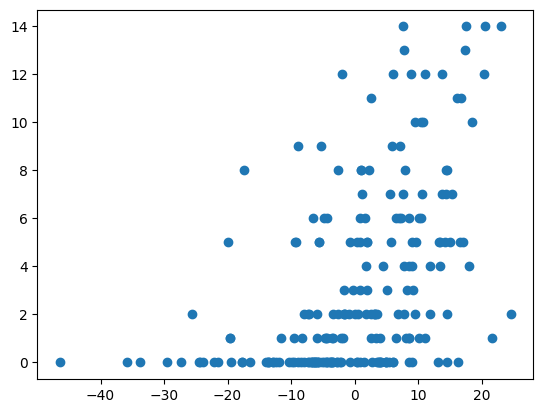

In [118]:
test = data.loc[data['has_cappers'] == 1].copy().reset_index(drop=True)
test['composite_estimate'] = test['composite'] - test.groupby(['date','track','race'])['composite'].transform('mean')
print(test[['composite_estimate','drf_sum']].corr())
plt.scatter(test['composite_estimate'], test['drf_sum'])


In [119]:
# Define custom betting strategies (optional)
custom_strategies = {
    # 'value_15_med_prob': {
    #     'criteria': {
    #         'percentage_edge': {'min': 15},
    #         'projected_win_probability': {'min': 0.07, 'max': 0.25}
    #     },
    #     'description': "Edge ≥ 15% with medium probability (7-25%)"
    # },
    # 'value_15_longshot': {
    #     'criteria': {
    #         'percentage_edge': {'min': 15},
    #         'projected_win_probability': {'min': 0.03, 'max': 0.07}
    #     },
    #     'description': "Edge ≥ 15% with longshot probability (3-7%)"
    # },
    # 'value_15_favorite': {
    #     'criteria': {
    #         'percentage_edge': {'min': 15},
    #         'projected_win_probability': {'min': 0.25}
    #     },
    #     'description': "Edge ≥ 15% with favorite probability (≥ 25%)"
    # },
    # 'high_edge_30': {
    #     'criteria': {
    #         'percentage_edge': {'min': 30},
    #         'projected_win_probability': {'min': 0.05}
    #     },
    #     'description': "Edge ≥ 30% with any reasonable probability (≥ 5%)"
    # },
    'every_race':{
        'criteria': {
            'edge': {'min': 0.01}
        },
        'description': "Expected value ≥ 50%"
    },
    'strat_5': {
        'criteria': {
            'edge': {'min': 0.075},
            'kelly_stake': {'min': 0.0175}
        },
        'description': "Edge ≥ 75% and kelly > (≥ 5%)"
    },
    'strat_10': {
        'criteria': {
            'edge': {'min': 0.075},
            'kelly_stake': {'min': 0.025}
        },
        'description': "Edge ≥ 75% and kelly > (≥ 5%)"
    },
    'edge_10': {
        'criteria': {
            'edge': {'min': 0.1}
        },
        'description': "Expected value ≥ 50%"
    },
    'edge_12.5': {
        'criteria': {
            'edge': {'min': 0.125}
        },
        'description': "Expected value ≥ 50%"
    },
    'edge_15': {
        'criteria': {
            'edge': {'min': 0.15}
        },
        'description': "Expected value ≥ 50%"
    },
    'edge_20': {
        'criteria': {
            'edge': {'min': 0.2}
        },
        'description': "Expected value ≥ 50%"
    },
    'kelly_7.5': {
        'criteria': lambda x: x['kelly_stake'] >= 0.075,
        'description': "Kelly stake ≥ 10%"
    },
    'kelly_10': {
        'criteria': lambda x: x['kelly_stake'] >= 0.1,
        'description': "Kelly stake ≥ 10%"
    },
    'combo_ev_fav': {
        'criteria': lambda x: x['expected_value'] >= 0.05 and x['projected_win_probability'] >= 0.2,
        'description': "Expected value ≥ 5% and probability ≥ 20%"
    },
    'ml_agree':{
        'criteria': lambda x: x['ml_probability_normalized'] * x['projected_win_probability'] >= 0.065,
        'description': "Morning line agrees good horse"
    }
}

In [120]:
data

,date,track,race,horse,form,time,composite,has_cappers,sweep,hersh,...,running,horse_name,sire,trainer,jockey,ml_odds,finish,win_paid,place_paid,show_paid
0,2025-04-18,keeneland,1,1,112.0,89.0,201.0,NaN,NaN,NaN,...,1.0,Tunisian Spring,Violence,Wesley A. Ward,Jose L. Ortiz,4/5,4.0,0,0,0
1,2025-04-18,keeneland,1,2,82.0,64.0,146.0,NaN,NaN,NaN,...,1.0,Bucyk,Speightstown,Jesus Esquivel,Gerardo Corrales,15/1,5.0,0,0,0
2,2025-04-18,keeneland,1,3,101.0,72.0,173.0,NaN,NaN,NaN,...,1.0,Pair of Socks,Vekoma,Dallas Stewart,Luis Saez,6/1,1.0,$17.86,$6.26,$5.26
3,2025-04-18,keeneland,1,4,100.0,72.0,172.0,NaN,NaN,NaN,...,1.0,Frost Mountain,Frosted,Michael Stidham,Ben Curtis,9/2,6.0,0,0,0
4,2025-04-18,keeneland,1,5,88.0,64.0,152.0,NaN,NaN,NaN,...,1.0,Express Line,Union Rags,Grant T. Forster,Corey J. Lanerie,8/1,3.0,0,0,$13.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1483,2025-10-31,del-mar,10,10,80.0,101.0,181.0,0.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1484,2025-10-31,del-mar,10,11,78.0,94.0,172.0,0.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1485,2025-10-31,del-mar,10,12,80.0,103.0,183.0,0.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1486,2025-10-31,del-mar,10,13,82.0,98.0,180.0,0.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [121]:

data['won'] = np.where(data['finish'] == 1, 1, 0)
data['date'] = pd.to_datetime(data['date']) 
data = data.loc[data['date'] <= pd.to_datetime('2025-06-06')].copy().reset_index(drop=True)
data['running'] = data['running'].astype(int)
data['global_race_number'] = data.groupby(['date','track','race']).ngroup() + 1
data = data.loc[data['running'] == 1].copy().reset_index(drop=True)

# data = process_morning_lines(data, ml_odds_col='ml_odds', group_cols=['date', 'track', 'horse'])
# data = calculate_win_probabilities_df_vectorized(data, composite_col='composite', std_dev=4, degrees_of_freedom=1.3, num_simulations=100000)



In [122]:

def calculate_win_probabilities_df_vectorized(df, composite_col='composite', std_dev=4, 
                                             degrees_of_freedom=5, num_simulations=100000):
    """
    Vectorized implementation for calculating winning probabilities.
    """
    # Create a copy of the input DataFrame to avoid modifying the original
    result_df = df.copy()
    
    # Initialize a win_probability column with zeros
    result_df['projected_win_probability'] = 0.0
    
    # Create t-distribution with specified degrees of freedom
    t_dist = stats.t(df=degrees_of_freedom)
    
    # Group by date, track, and race
    for (date, track, race), race_df in result_df.groupby(['date', 'track', 'race']):
        # Get indices for this race
        race_indices = race_df.index
        num_horses = len(race_indices)
        
        # Skip races with only one horse
        if num_horses <= 1:
            continue
            
        # Extract horse composite values for this race
        composite_values = race_df[composite_col].values
        
        # Reshape for broadcasting
        composite_values = composite_values.reshape(num_horses, 1)
        
        # Generate all random effects at once (num_horses x num_simulations)
        random_effects = t_dist.rvs(size=(num_horses, num_simulations)) * std_dev
        
        # Calculate all finish positions at once
        finishes = composite_values + random_effects
        
        # Find winner for each simulation
        winners = np.argmax(finishes, axis=0)
        
        # Count wins for each horse
        win_counts = np.bincount(winners, minlength=num_horses)
        win_probabilities = win_counts / num_simulations
        
        # Assign back to DataFrame
        result_df.loc[race_indices, 'projected_win_probability'] = win_probabilities
    
    return result_df

In [123]:
from sklearn.metrics import log_loss
from scipy.optimize import minimize 

## use thisinstead of the above

def objective_function(params, data=None):
    """
    Objective function to minimize. Calculates log loss with the given parameters.
    
    Args:
        params: array of parameters [std_dev, df]
        data: DataFrame containing the necessary data
    
    Returns:
        log loss value to minimize
    """
    # Extract parameters from the array
    std_dev = params[0]
    degrees_of_freedom = params[1]
    
    result_df = calculate_win_probabilities_df_vectorized(
        data, 
        composite_col='composite', 
        std_dev=std_dev,  # Use the first parameter as std_dev
        degrees_of_freedom=degrees_of_freedom,  # Use the second parameter as df
        num_simulations=10000  # Use more simulations for final model
    )
    
    return log_loss(result_df['won'], result_df['projected_win_probability'])

def optimize_parameters(data, initial_std_dev=4.0, initial_df=1):
    """
    Optimize the std_dev and degrees_of_freedom parameters to minimize log loss.
    
    Args:
        data: DataFrame containing the necessary data
        initial_std_dev: Initial value for standard deviation
        initial_df: Initial value for degrees of freedom
    
    Returns:
        Tuple of optimal (std_dev, degrees_of_freedom)
    """
    # Create initial parameter array
    initial_params = np.array([initial_std_dev, initial_df])
    
    # Define bounds for parameters
    bounds = [(1, 10), (0.1, 2)]  # (std_dev, degrees_of_freedom)
    
    # Use Nelder-Mead optimization (doesn't require gradients)
    result = minimize(
        objective_function,
        initial_params,
        args=(data,),
        method='Nelder-Mead',
        bounds=bounds,
        options={'maxiter': 250, 'disp': True}
    )
    
    
    # Return the optimal parameters
    return result.x[0], result.x[1]  # std_dev, degrees_of_freedom





In [124]:
## run on 06/07
# optimal_std_dev, optimal_df = optimize_parameters(data, initial_std_dev=4.4, initial_df=0.9)
# print(f"Optimal parameters: std_dev={optimal_std_dev:.4f}, degrees_of_freedom={optimal_df:.4f}")

# Optimal parameters: std_dev=4.8354, degrees_of_freedom=0.8108


In [125]:
skip = True
if skip:
    optimal_std_dev = 4.8354
    optimal_df = 0.8108

# Use optimized parameters for final model
data = calculate_win_probabilities_df_vectorized(
    data, 
    composite_col='composite', 
    std_dev=optimal_std_dev, 
    degrees_of_freedom=optimal_df, 
    num_simulations=100000     # Use more simulations for final model
)

print(f"Optimal parameters: std_dev={optimal_std_dev:.4f}, degrees_of_freedom={optimal_df:.4f}")

Optimal parameters: std_dev=4.8354, degrees_of_freedom=0.8108


In [126]:



data['race_3q'] = data.groupby(['global_race_number'])['time'].transform(lambda x: x.quantile(0.75))
data['ahead_of_3q'] = data['time'] - data['race_3q']
data['ahead_of_mean'] = data['form'] - data.groupby(['global_race_number'])['form'].transform('mean') 
data['behind_max'] = data['form'] - data.groupby(['global_race_number'])['form'].transform('max') 
data['num_horses'] = data.groupby(['global_race_number'])['composite'].transform('count') 
data['num_horses'] = data['num_horses'].astype(int)
# data['num_horses_sq'] = data['num_horses'] ** 2
data['place'] = np.where(data['finish'] <= 2, 1, 0)
data['show'] = np.where(data['finish'] <= 3, 1, 0)
data['num_horses_sq'] = data['num_horses'] ** 2


from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict 
from sklearn.metrics import log_loss

X = data[['ahead_of_3q', 'ahead_of_mean','behind_max', 'num_horses', 'num_horses_sq']] 
y = data['won']
win_model = LogisticRegression()
y_pred = cross_val_predict(win_model, X, y, cv=10, method='predict_proba')[:, 1]
log_loss_score = log_loss(y, y_pred)
print(f"Log Loss Score: {log_loss_score:.4f}")

## see coefficients 
win_model.fit(X, y)
coefficients = win_model.coef_[0]
intercept = win_model.intercept_[0]
data['raw_win_prob'] = y_pred
# data = apply_optimal_temperature(data, optimal_temp=1, race_col='global_race_number', raw_prob_col='raw_win_prob', new_col='calibrated_prob')
data['calibrated_prob'] = data['raw_win_prob']/ data.groupby(['global_race_number'])['raw_win_prob'].transform('sum') 
log_loss(data['won'], data['calibrated_prob'])
coefficients, intercept



Log Loss Score: 0.3358


(array([ 0.03314221,  0.09014864,  0.04474816, -0.27150596,  0.0075626 ]),
 -0.06437666446132971)

In [127]:

from scipy.optimize import minimize_scalar

def process_morning_lines(df, ml_odds_col='ml_odds', group_cols=['date', 'track', 'race'], 
                         method='softmax', temperature=1.0):
    """
    Convert morning line odds strings to normalized probabilities using either
    simple division or softmax normalization.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame containing morning line odds
    ml_odds_col : str
        Name of column containing morning line odds as strings (e.g., '9/2', '5/2')
    group_cols : list
        List of columns to group by for defining each race
    method : str
        Normalization method: 'sum' for simple division or 'softmax' for softmax normalization
    temperature : float
        Temperature parameter for softmax (only used if method='softmax')
        Higher values make distribution more uniform, lower values emphasize differences
        
    Returns:
    --------
    pandas DataFrame
        Original DataFrame with new probability columns
    """
    # Create a copy to avoid modifying the original
    result_df = df.copy()
    
    # Function to parse fractional odds and convert to probability
    def odds_to_probability(odds_str):
        try:
            # Handle special cases
            if pd.isna(odds_str) or odds_str == '':
                return np.nan
            
            # Convert string like "9/2" to a probability
            if '/' in str(odds_str):
                numerator, denominator = map(float, str(odds_str).split('/'))
                # Formula: probability = denominator / (numerator + denominator)
                return denominator / (numerator + denominator)
            # Handle decimal odds format (e.g., 2.5)
            elif isinstance(odds_str, (int, float)) or (isinstance(odds_str, str) and 
                                                     odds_str.replace('.', '', 1).isdigit()):
                decimal_odds = float(odds_str)
                return 1 / decimal_odds
            # Handle edge cases like "EVN" (even money, which is 1/1)
            elif isinstance(odds_str, str) and odds_str.upper() in ['EVN', 'EVEN', 'EV']:
                return 0.5
            else:
                return np.nan
        except (ValueError, ZeroDivisionError, AttributeError):
            return np.nan
    
    # Convert odds strings to raw probabilities
    result_df['ml_probability_raw'] = result_df[ml_odds_col].apply(odds_to_probability)
    
    # Initialize normalized probability column
    result_df['ml_probability_normalized'] = np.nan
    
    # Apply the chosen normalization method within each race group
    for group_values, group_df in result_df.groupby(group_cols):
        # Get indices and valid probabilities for this group
        group_indices = group_df.index
        valid_mask = ~group_df['ml_probability_raw'].isna()
        valid_indices = group_indices[valid_mask]
        
        if len(valid_indices) > 0:
            valid_probs = group_df.loc[valid_indices, 'ml_probability_raw'].values
            
            if method.lower() == 'sum':
                # Simple division by sum normalization
                sum_probs = valid_probs.sum()
                if sum_probs > 0:
                    normalized_probs = valid_probs / sum_probs
                    
            elif method.lower() == 'softmax':
                # Softmax normalization
                # First convert probabilities to logits
                logits = np.log(valid_probs)
                
                # Apply temperature scaling
                logits = logits / temperature
                
                # Apply softmax formula: exp(x_i) / sum(exp(x_j))
                exp_logits = np.exp(logits - np.max(logits))  # Subtract max for numerical stability
                softmax_probs = exp_logits / exp_logits.sum()
                normalized_probs = softmax_probs
                
            else:
                raise ValueError(f"Unknown normalization method: {method}")
            
            # Assign normalized probabilities back to DataFrame
            result_df.loc[valid_indices, 'ml_probability_normalized'] = normalized_probs
    
    # Convert to percentages (optional)
    result_df['ml_probability_pct'] = result_df['ml_probability_normalized'] * 100
    
    return result_df

def optimize_softmax_temperature(df, ml_odds_col='ml_odds', won_col='won', 
                                group_cols=['date', 'track', 'race'], 
                                temp_min=0.1, temp_max=5.0, cv_folds=5):
    """
    Optimize the softmax temperature parameter for morning line odds.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame containing morning line odds and race outcomes
    ml_odds_col : str
        Column name containing morning line odds
    won_col : str
        Column name with actual outcomes (1 for win, 0 for loss)
    group_cols : list
        List of columns to group by for defining each race
    temp_min : float
        Minimum temperature value to consider
    temp_max : float
        Maximum temperature value to consider
    cv_folds : int
        Number of cross-validation folds
        
    Returns:
    --------
    dict
        Results dictionary with optimal temperature and performance metrics
    """
    print("Optimizing softmax temperature parameter...")
    
    # Ensure won column exists and is binary
    if won_col not in df.columns:
        raise ValueError(f"Column '{won_col}' not found in DataFrame")
    
    # Verify that won column has binary values
    if not set(df[won_col].dropna().unique()).issubset({0, 1}):
        raise ValueError(f"Column '{won_col}' must contain only 0 and 1 values")
    
    # Generate unique fold IDs for cross-validation
    unique_races = df.groupby(group_cols).size().reset_index()[group_cols]
    unique_races['fold_id'] = np.random.randint(0, cv_folds, size=len(unique_races))
    
    # Merge fold IDs back to original DataFrame
    df_with_folds = df.merge(unique_races, on=group_cols)
    
    # Function to compute log loss for a given temperature
    def compute_loss(temperature, fold=None):
        """
        Compute log loss for a given temperature parameter.
        
        Parameters:
        -----------
        temperature : float
            Softmax temperature parameter
        fold : int or None
            If provided, compute loss only for the specified fold
            If None, compute loss for all data
            
        Returns:
        --------
        float
            Log loss score
        """
        # Select data for the specified fold or all data
        if fold is not None:
            data = df_with_folds[df_with_folds['fold_id'] != fold].copy()  # Use all except current fold
        else:
            data = df.copy()
        
        # Process morning lines with given temperature
        processed_df = process_morning_lines(
            data, 
            ml_odds_col=ml_odds_col, 
            group_cols=group_cols,
            method='softmax', 
            temperature=temperature
        )
        
        # Compute log loss
        valid_mask = (~processed_df[won_col].isna()) & (~processed_df['ml_probability_normalized'].isna())
        
        if valid_mask.sum() == 0:
            return np.inf
        
        y_true = processed_df.loc[valid_mask, won_col].values
        y_pred = processed_df.loc[valid_mask, 'ml_probability_normalized'].values
        
        # Ensure probabilities are in valid range
        epsilon = 1e-15
        y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
        
        # Compute log loss
        loss = log_loss(y_true, y_pred)
        
        return loss
    
    # Function to compute cross-validation loss
    def cv_loss_function(temperature):
        """
        Compute average cross-validation loss for a given temperature.
        
        Parameters:
        -----------
        temperature : float
            Softmax temperature parameter
            
        Returns:
        --------
        float
            Average log loss across all folds
        """
        cv_scores = []
        
        # Compute loss for each fold
        for fold in range(cv_folds):
            fold_loss = compute_loss(temperature, fold=fold)
            cv_scores.append(fold_loss)
        
        # Calculate average loss
        avg_loss = np.mean(cv_scores)
        
        print(f"Temperature: {temperature:.4f}, Avg CV Loss: {avg_loss:.6f}")
        
        return avg_loss
    
    # Run optimization using SciPy's minimize_scalar
    print(f"Running optimization with {cv_folds}-fold cross-validation...")
    result = minimize_scalar(
        cv_loss_function,
        bounds=(temp_min, temp_max),
        method='bounded',
        options={'xatol': 0.01}
    )
    
    # Extract optimal temperature
    optimal_temp = result.x
    best_cv_loss = result.fun
    
    print(f"\nOptimization complete!")
    print(f"Optimal temperature: {optimal_temp:.4f}")
    print(f"Best cross-validation log loss: {best_cv_loss:.6f}")
    
    # Calculate final metrics with optimal temperature
    final_df = process_morning_lines(
        df,
        ml_odds_col=ml_odds_col,
        group_cols=group_cols,
        method='softmax',
        temperature=optimal_temp
    )
    
    # Compute final log loss on full dataset
    valid_mask = (~final_df[won_col].isna()) & (~final_df['ml_probability_normalized'].isna())
    
    if valid_mask.sum() > 0:
        y_true = final_df.loc[valid_mask, won_col].values
        y_pred = final_df.loc[valid_mask, 'ml_probability_normalized'].values
        
        # Ensure probabilities are in valid range
        epsilon = 1e-15
        y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
        
        # Compute log loss
        final_loss = log_loss(y_true, y_pred)
        
        print(f"Final log loss on full dataset: {final_loss:.6f}")
    else:
        final_loss = np.nan
        print("Warning: No valid data for final evaluation")
    
    # Compare with baseline (temperature = 1.0, equivalent to sum normalization)
    baseline_df = process_morning_lines(
        df,
        ml_odds_col=ml_odds_col,
        group_cols=group_cols,
        method='sum'  # Same as softmax with temperature=1.0
    )
    
    # Compute baseline log loss
    valid_mask = (~baseline_df[won_col].isna()) & (~baseline_df['ml_probability_normalized'].isna())
    
    if valid_mask.sum() > 0:
        y_true = baseline_df.loc[valid_mask, won_col].values
        y_pred = baseline_df.loc[valid_mask, 'ml_probability_normalized'].values
        
        # Ensure probabilities are in valid range
        epsilon = 1e-15
        y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
        
        # Compute log loss
        baseline_loss = log_loss(y_true, y_pred)
        
        print(f"Baseline log loss (temperature=1.0): {baseline_loss:.6f}")
        print(f"Improvement: {baseline_loss - final_loss:.6f} ({(baseline_loss - final_loss) / baseline_loss * 100:.2f}%)")
    else:
        baseline_loss = np.nan
        print("Warning: No valid data for baseline evaluation")
    
    # Evaluate different temperature values
    print("\nEvaluating range of temperature values...")
    temp_values = np.linspace(max(0.1, optimal_temp * 0.5), min(5.0, optimal_temp * 1.5), 20)
    loss_values = []
    
    for temp in temp_values:
        loss = compute_loss(temp)
        loss_values.append(loss)
        
    # Plot temperature vs. log loss
    plt.figure(figsize=(10, 6))
    plt.plot(temp_values, loss_values, 'o-')
    plt.axvline(x=optimal_temp, color='r', linestyle='--', label=f'Optimal Temp: {optimal_temp:.4f}')
    plt.axvline(x=1.0, color='g', linestyle='--', label='Temp = 1.0 (Sum Normalization)')
    plt.xlabel('Temperature')
    plt.ylabel('Log Loss')
    plt.title('Temperature vs. Log Loss')
    plt.grid(True)
    plt.legend()
    plt.show()
    
    # Calculate calibration statistics for optimal temperature
    calibration_df = pd.DataFrame({
        'predicted_probability': final_df['ml_probability_normalized'],
        'actual_outcome': final_df[won_col]
    }).dropna()
    
    # Create probability bins
    bins = np.linspace(0, 1, 11)
    bin_labels = [f'{bins[i]:.1f}-{bins[i+1]:.1f}' for i in range(len(bins)-1)]
    calibration_df['prob_bin'] = pd.cut(calibration_df['predicted_probability'], bins, labels=bin_labels)
    
    # Calculate calibration statistics
    calibration_stats = calibration_df.groupby('prob_bin').agg({
        'actual_outcome': ['count', 'mean'],
        'predicted_probability': 'mean'
    })
    
    calibration_stats.columns = ['count', 'actual_win_rate', 'predicted_win_rate']
    calibration_stats = calibration_stats.reset_index()
    
    print("\nCalibration Statistics (Optimal Temperature):")
    print(calibration_stats)
    
    # Plot calibration curve
    plt.figure(figsize=(10, 7))
    plt.plot([0, 1], [0, 1], 'k--', label='Perfect Calibration')
    
    # Plot actual calibration points
    valid_bins = calibration_stats[calibration_stats['count'] >= 10]
    plt.scatter(
        valid_bins['predicted_win_rate'],
        valid_bins['actual_win_rate'],
        s=valid_bins['count'] / valid_bins['count'].max() * 200,
        alpha=0.7
    )
    
    # Add bin labels
    for i, row in valid_bins.iterrows():
        plt.annotate(
            f"{row['prob_bin']}\n(n={row['count']})",
            (row['predicted_win_rate'], row['actual_win_rate']),
            textcoords="offset points",
            xytext=(0, 10),
            ha='center'
        )
    
    plt.xlabel('Predicted Win Probability')
    plt.ylabel('Actual Win Rate')
    plt.title(f'Calibration Curve (Temperature = {optimal_temp:.4f})')
    plt.grid(True)
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.show()
    
    # Return results
    return {
        'optimal_temperature': optimal_temp,
        'best_cv_loss': best_cv_loss,
        'final_loss': final_loss,
        'baseline_loss': baseline_loss,
        'final_df': final_df,
        'temp_values': temp_values,
        'loss_values': loss_values,
        'calibration_stats': calibration_stats
    }

def analyze_temperature_impact(df, ml_odds_col='ml_odds', group_cols=['date', 'track', 'race'], 
                             optimal_temp=None, temp_range=(0.1, 3.0)):
    """
    Analyze the impact of different temperature values on probability distributions.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame containing morning line odds
    ml_odds_col : str
        Column name containing morning line odds
    group_cols : list
        List of columns to group by for defining each race
    optimal_temp : float or None
        Optimal temperature from optimization process
    temp_range : tuple
        Range of temperatures to analyze
        
    Returns:
    --------
    None (produces visualizations)
    """
    print("Analyzing temperature impact on probability distributions...")
    
    # Select a sample race for visualization
    race_groups = list(df.groupby(group_cols))
    
    # Find a race with a reasonable number of horses (5-10)
    sample_race = None
    for group_values, group_df in race_groups:
        if 5 <= len(group_df) <= 10:
            sample_race = (group_values, group_df)
            break
    
    # If no ideal race found, take the first one
    if sample_race is None and race_groups:
        sample_race = race_groups[0]
    
    if sample_race:
        group_values, race_df = sample_race
        race_id = "-".join(str(val) for val in group_values)
        print(f"Visualizing temperature impact for race: {race_id} with {len(race_df)} horses")
        
        # Get raw probabilities
        race_df = race_df.copy()
        
        # Parse odds to probabilities
        def odds_to_probability(odds_str):
            try:
                if pd.isna(odds_str) or odds_str == '':
                    return np.nan
                
                if '/' in str(odds_str):
                    numerator, denominator = map(float, str(odds_str).split('/'))
                    return denominator / (numerator + denominator)
                elif isinstance(odds_str, (int, float)) or (isinstance(odds_str, str) and 
                                                       odds_str.replace('.', '', 1).isdigit()):
                    decimal_odds = float(odds_str)
                    return 1 / decimal_odds
                elif isinstance(odds_str, str) and odds_str.upper() in ['EVN', 'EVEN', 'EV']:
                    return 0.5
                else:
                    return np.nan
            except (ValueError, ZeroDivisionError, AttributeError):
                return np.nan
                
        race_df['raw_prob'] = race_df[ml_odds_col].apply(odds_to_probability)
        
        # Define temperatures to analyze
        if optimal_temp is not None:
            temperatures = [0.25, 0.5, 0.75, 1.0, optimal_temp, 2.0, 3.0]
            temperatures = sorted(list(set(temperatures)))  # Remove duplicates
        else:
            min_temp, max_temp = temp_range
            temperatures = np.linspace(min_temp, max_temp, 7)
        
        # Calculate normalized probabilities for each temperature
        results = []
        
        for temp in temperatures:
            temp_result = process_morning_lines(
                race_df, 
                ml_odds_col=ml_odds_col,
                group_cols=group_cols,
                method='softmax',
                temperature=temp
            )
            
            # Extract horse names/numbers and probabilities
            for _, row in temp_result.iterrows():
                if not pd.isna(row['ml_probability_normalized']):
                    results.append({
                        'temperature': temp,
                        'horse': row.get('horse', f"Horse {_}"),
                        'ml_odds': row[ml_odds_col],
                        'raw_prob': row['ml_probability_raw'],
                        'normalized_prob': row['ml_probability_normalized']
                    })
        
        # Convert to DataFrame for plotting
        viz_df = pd.DataFrame(results)
        
        # Sort horses by raw probability (descending)
        horse_order = race_df.sort_values('raw_prob', ascending=False)['horse'].values
        viz_df['horse'] = pd.Categorical(viz_df['horse'], categories=horse_order, ordered=True)
        
        # Generate colors for horses
        import matplotlib.cm as cm
        colors = cm.rainbow(np.linspace(0, 1, len(horse_order)))
        horse_colors = dict(zip(horse_order, colors))
        
        # Plot how probabilities change with temperature
        plt.figure(figsize=(14, 8))
        
        for horse in horse_order:
            horse_data = viz_df[viz_df['horse'] == horse]
            plt.plot(
                horse_data['temperature'], 
                horse_data['normalized_prob'], 
                'o-', 
                label=f"{horse} ({horse_data['ml_odds'].iloc[0]})",
                color=horse_colors[horse]
            )
        
        # Mark reference lines
        plt.axvline(x=1.0, color='black', linestyle='--', label='Temp = 1.0 (Sum Normalization)')
        
        if optimal_temp is not None:
            plt.axvline(x=optimal_temp, color='red', linestyle='--', label=f'Optimal Temp = {optimal_temp:.2f}')
        
        plt.xlabel('Temperature')
        plt.ylabel('Normalized Probability')
        plt.title('Effect of Temperature on Probability Distribution')
        plt.grid(True)
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()
        
        # Bar chart comparing probabilities at different temperatures
        temperatures_to_show = [0.5, 1.0]
        if optimal_temp is not None and optimal_temp not in temperatures_to_show:
            temperatures_to_show.append(optimal_temp)
        if 2.0 not in temperatures_to_show:
            temperatures_to_show.append(2.0)
        temperatures_to_show = sorted(temperatures_to_show)
        
        # Filter data for selected temperatures
        selected_temps = viz_df[viz_df['temperature'].isin(temperatures_to_show)]
        
        # Plot bar chart
        plt.figure(figsize=(14, 8))
        
        bar_width = 0.8 / len(temperatures_to_show)
        horse_positions = np.arange(len(horse_order))
        
        for i, temp in enumerate(temperatures_to_show):
            temp_data = selected_temps[selected_temps['temperature'] == temp]
            temp_data = temp_data.sort_values('horse', key=lambda x: pd.Categorical(x, categories=horse_order, ordered=True))
            
            plt.bar(
                horse_positions + i * bar_width - (len(temperatures_to_show) - 1) * bar_width / 2, 
                temp_data['normalized_prob'], 
                width=bar_width, 
                label=f'Temp = {temp:.2f}'
            )
        
        plt.xlabel('Horse')
        plt.ylabel('Normalized Probability')
        plt.title('Comparison of Probabilities at Different Temperatures')
        plt.xticks(horse_positions, [f"{horse}\n({race_df[race_df['horse'] == horse][ml_odds_col].iloc[0]})" for horse in horse_order], rotation=45)
        plt.legend()
        plt.grid(True, axis='y')
        plt.tight_layout()
        plt.show()
        
        # Create entropy visualization
        print("\nAnalyzing probability distribution entropy...")
        
        # Generate more temperature points for smooth entropy curve
        temp_values = np.linspace(temp_range[0], temp_range[1], 100)
        entropies = []
        
        for temp in temp_values:
            # Get raw probabilities
            raw_probs = race_df['raw_prob'].dropna().values
            
            # Apply softmax with this temperature
            logits = np.log(raw_probs)
            logits = logits / temp
            exp_logits = np.exp(logits - np.max(logits))
            softmax_probs = exp_logits / exp_logits.sum()
            
            # Calculate entropy: -sum(p * log(p))
            entropy = -np.sum(softmax_probs * np.log2(softmax_probs + 1e-15))
            entropies.append(entropy)
        
        # Plot entropy vs temperature
        plt.figure(figsize=(10, 6))
        plt.plot(temp_values, entropies, 'b-')
        
        # Mark reference points
        plt.axvline(x=1.0, color='black', linestyle='--', label='Temp = 1.0 (Sum Normalization)')
        
        if optimal_temp is not None:
            plt.axvline(x=optimal_temp, color='red', linestyle='--', label=f'Optimal Temp = {optimal_temp:.2f}')
        
        # Calculate maximum entropy for reference (uniform distribution)
        max_entropy = np.log2(len(raw_probs))
        plt.axhline(y=max_entropy, color='green', linestyle='--', label='Max Entropy (Uniform)')
        
        plt.xlabel('Temperature')
        plt.ylabel('Entropy (bits)')
        plt.title('Temperature vs. Probability Distribution Entropy')
        plt.grid(True)
        plt.legend()
        plt.show()
        
        # Print entropy interpretation
        print("\nEntropy Interpretation:")
        print(f"Low temperature (e.g., 0.5): More concentrated on favorites, lower entropy")
        print(f"Temperature = 1.0: Standard sum normalization")
        print(f"High temperature (e.g., 2.0): More uniform distribution, higher entropy")
        if optimal_temp is not None:
            print(f"Optimal Temperature = {optimal_temp:.4f}: Best performing according to log loss")
    else:
        print("No races found in the DataFrame")


Optimizing softmax temperature parameter...
Running optimization with 5-fold cross-validation...
Temperature: 1.9716, Avg CV Loss: 0.341020
Temperature: 3.1284, Avg CV Loss: 0.348668
Temperature: 1.2567, Avg CV Loss: 0.332739
Temperature: 0.8149, Avg CV Loss: 0.327638
Temperature: 0.5418, Avg CV Loss: 0.333067
Temperature: 0.9045, Avg CV Loss: 0.328251
Temperature: 0.7106, Avg CV Loss: 0.327819
Temperature: 0.7824, Avg CV Loss: 0.327561
Temperature: 0.7779, Avg CV Loss: 0.327558
Temperature: 0.7742, Avg CV Loss: 0.327557
Temperature: 0.7708, Avg CV Loss: 0.327558

Optimization complete!
Optimal temperature: 0.7742
Best cross-validation log loss: 0.327557
Final log loss on full dataset: 0.328041
Baseline log loss (temperature=1.0): 0.329693
Improvement: 0.001652 (0.50%)

Evaluating range of temperature values...


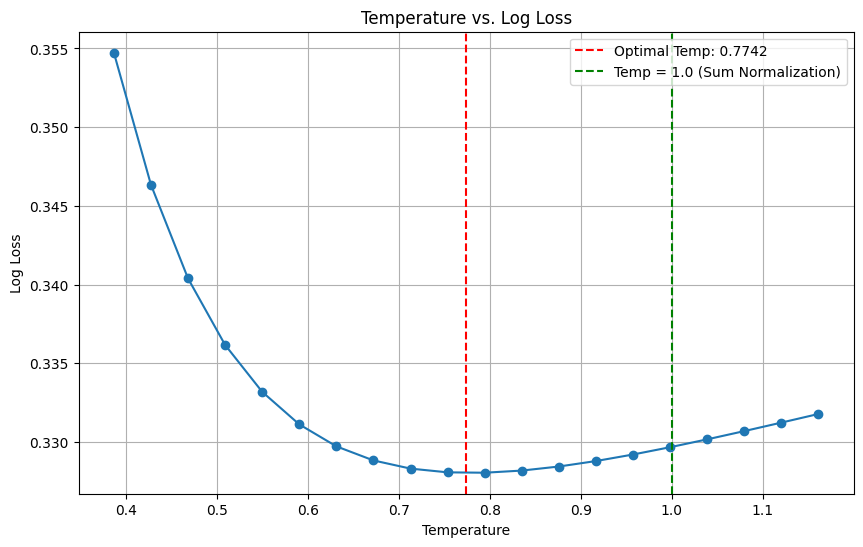


Calibration Statistics (Optimal Temperature):
  prob_bin  count  actual_win_rate  predicted_win_rate
0  0.0-0.1    636         0.051887            0.048755
1  0.1-0.2    340         0.138235            0.145763
2  0.2-0.3    149         0.248322            0.240872
3  0.3-0.4     55         0.309091            0.334454
4  0.4-0.5     16         0.500000            0.427875
5  0.5-0.6      5         0.400000            0.532327
6  0.6-0.7      3         1.000000            0.622376
7  0.7-0.8      1         0.000000            0.772771
8  0.8-0.9      0              NaN                 NaN
9  0.9-1.0      0              NaN                 NaN


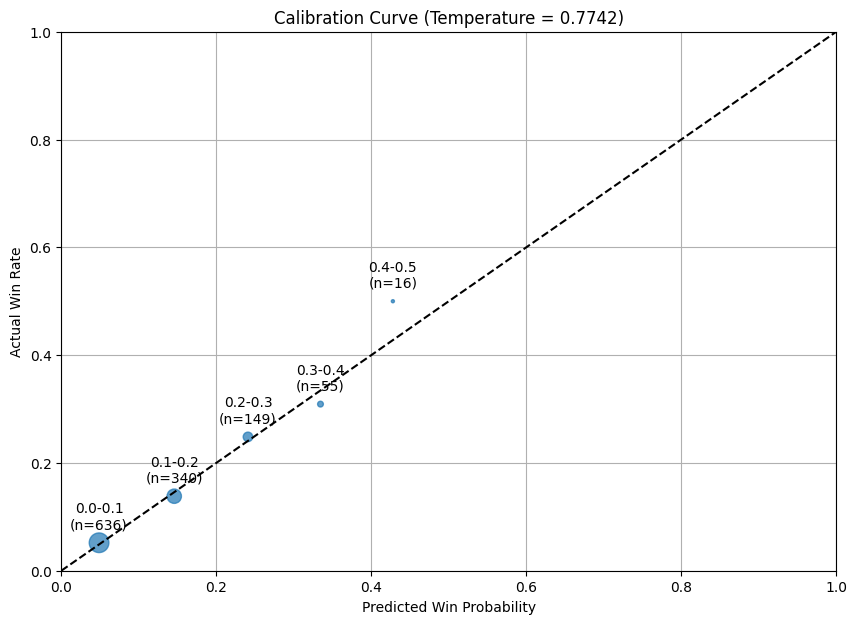

Optimal softmax temperature: 0.7742
Analyzing temperature impact on probability distributions...
Visualizing temperature impact for race: 2025-04-18 00:00:00-keeneland-1 with 6 horses


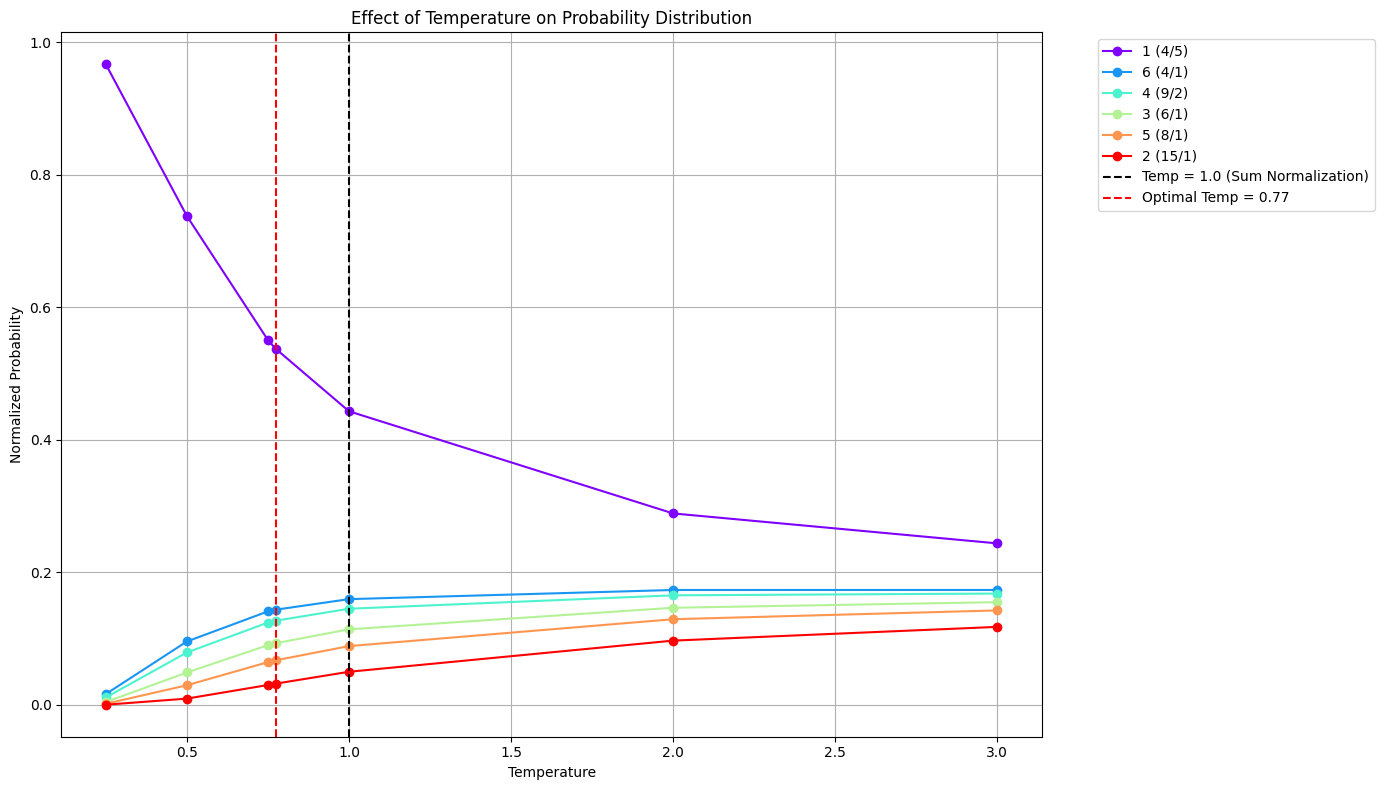

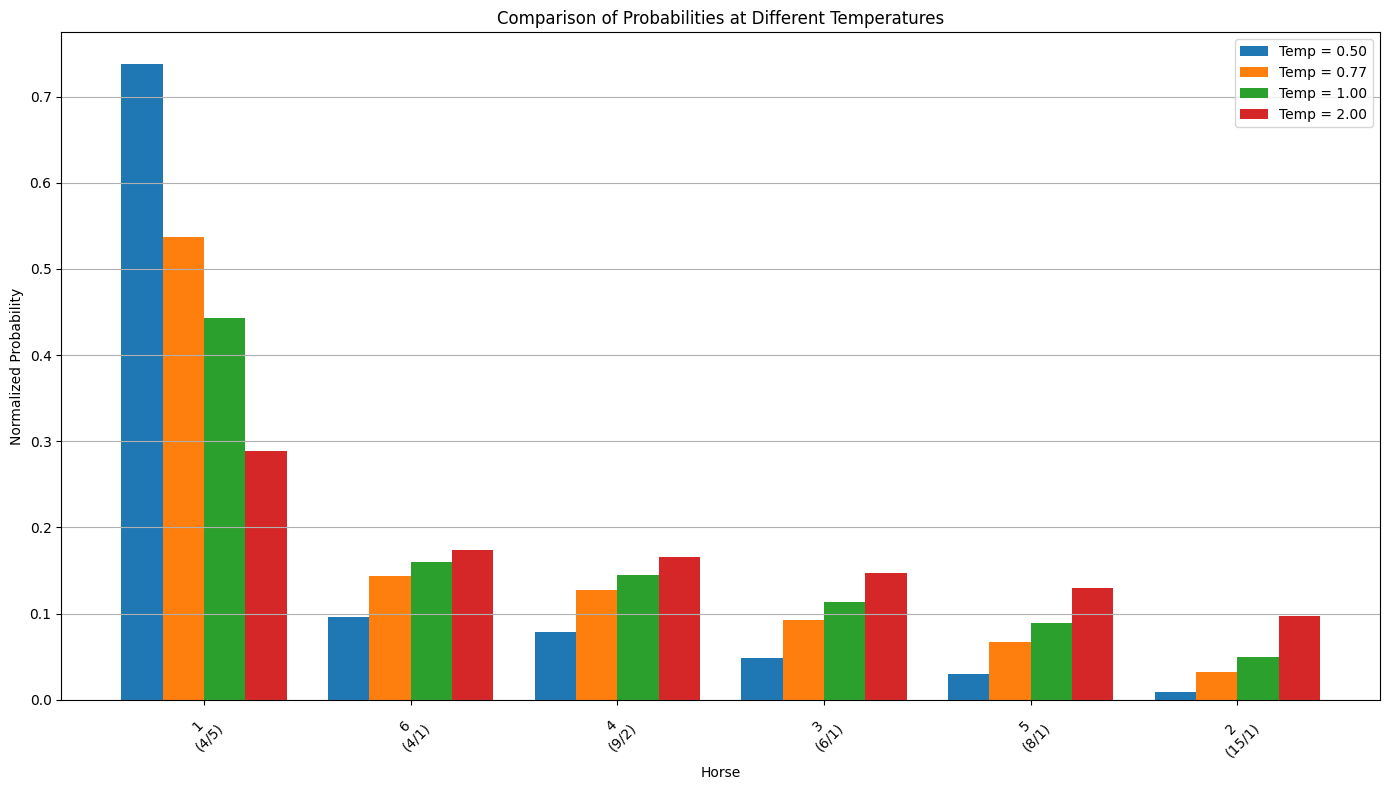


Analyzing probability distribution entropy...


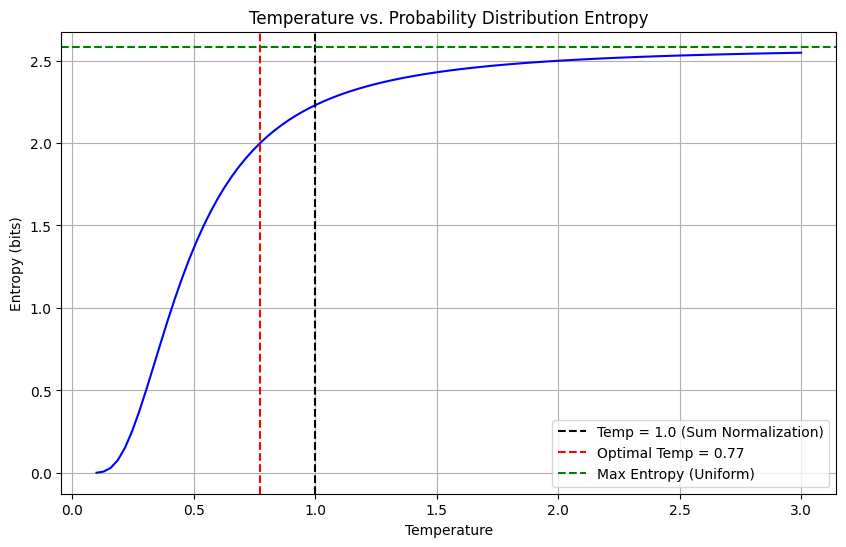


Entropy Interpretation:
Low temperature (e.g., 0.5): More concentrated on favorites, lower entropy
Temperature = 1.0: Standard sum normalization
High temperature (e.g., 2.0): More uniform distribution, higher entropy
Optimal Temperature = 0.7742: Best performing according to log loss


In [128]:
# Optimize softmax temperature
results = optimize_softmax_temperature(
    data,
    ml_odds_col='ml_odds',        # Column with morning line odds
    won_col='won',               # Column with binary outcome (1=win, 0=loss)
    group_cols=['date', 'track', 'race'],  # Columns to define races
    temp_min=0.1,                # Minimum temperature to consider
    temp_max=5.0,                # Maximum temperature to consider
    cv_folds=5                   # Number of cross-validation folds
)

# Get optimal temperature
optimal_temp = results['optimal_temperature']
print(f"Optimal softmax temperature: {optimal_temp:.4f}")

# Analyze how different temperatures affect probabilities
analyze_temperature_impact(
    data, 
    ml_odds_col='ml_odds',
    group_cols=['date', 'track', 'race'],
    optimal_temp=optimal_temp
)

# Optimal temperature: 0.6371

# Apply optimal temperature to get final probabilities
data = process_morning_lines(
    data,
    ml_odds_col='ml_odds',
    group_cols=['date', 'track', 'race'],
    method='softmax',
    temperature=optimal_temp
)

In [129]:

data['pred_final'] = data[['projected_win_probability','calibrated_prob']].mean(axis=1)
## normalize
data['pred_final'] = data['pred_final'] / data.groupby(['global_race_number'])['pred_final'].transform('sum')
data


,date,track,race,horse,form,time,composite,has_cappers,sweep,hersh,...,num_horses,place,show,num_horses_sq,raw_win_prob,calibrated_prob,ml_probability_raw,ml_probability_normalized,ml_probability_pct,pred_final
0,2025-04-18,keeneland,1,1,112.0,89.0,201.0,NaN,NaN,NaN,...,6,0,0,36,0.655374,0.603086,0.555556,0.537330,53.732977,0.641643
1,2025-04-18,keeneland,1,2,82.0,64.0,146.0,NaN,NaN,NaN,...,6,0,0,36,0.009992,0.009195,0.062500,0.031959,3.195949,0.024292
2,2025-04-18,keeneland,1,3,101.0,72.0,173.0,NaN,NaN,NaN,...,6,1,1,36,0.175531,0.161526,0.142857,0.092972,9.297242,0.126563
3,2025-04-18,keeneland,1,4,100.0,72.0,172.0,NaN,NaN,NaN,...,6,0,0,36,0.155388,0.142991,0.181818,0.126953,12.695283,0.114931
4,2025-04-18,keeneland,1,5,88.0,64.0,152.0,NaN,NaN,NaN,...,6,0,1,36,0.023666,0.021778,0.111111,0.067200,6.720019,0.032164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1200,2025-06-06,saratoga,14,9,62.0,81.0,143.0,1.0,NaN,NaN,...,11,0,0,121,0.062621,0.052428,0.047619,0.026887,2.688749,0.050404
1201,2025-06-06,saratoga,14,10,48.0,81.0,129.0,1.0,NaN,NaN,...,11,0,0,121,0.007823,0.006550,0.019608,0.008546,0.854647,0.021570
1202,2025-06-06,saratoga,14,11,44.0,75.0,119.0,1.0,NaN,NaN,...,11,0,0,121,0.003463,0.002900,0.032258,0.016258,1.625797,0.017390
1203,2025-06-06,saratoga,14,13,55.0,86.0,141.0,1.0,NaN,NaN,...,11,0,0,121,0.026585,0.022257,0.047619,0.026887,2.688749,0.033909


In [130]:

data['logit_ml'] = np.log(data['ml_probability_normalized'] / (1 - data['ml_probability_normalized']))
data['logit_pred'] = np.log(data['pred_final'] / (1 - data['pred_final'])) 
comp_model = LogisticRegression() 
comp_model.fit(data[['logit_ml','logit_pred']], data['won']) 
comp_model.coef_, comp_model.intercept_

log_loss(data['won'], comp_model.predict_proba(data[['logit_ml','logit_pred']])[:, 1])

0.3239778770331793

In [131]:

place_model = LogisticRegression() 
place_model.fit(data[['logit_ml','logit_pred']], data['place']) 
place_model.coef_, place_model.intercept_

log_loss(data['place'], place_model.predict_proba(data[['logit_ml','logit_pred']])[:, 1])


0.4915216828246999

In [132]:

show_model = LogisticRegression() 
show_model.fit(data[['logit_ml','logit_pred']], data['show']) 
show_model.coef_, show_model.intercept_

log_loss(data['show'], show_model.predict_proba(data[['logit_ml','logit_pred']])[:,1])


0.5680782356395425

In [133]:
universal_coefs = np.mean([comp_model.coef_[0], place_model.coef_[0], show_model.coef_[0]], axis=0)
print([comp_model.coef_[0], place_model.coef_[0], show_model.coef_[0]])
universal_coefs = universal_coefs / np.sum(np.abs(universal_coefs))
print(universal_coefs)
data['best_win_prob'] = 1/(1+np.exp(-data['logit_ml']*universal_coefs[0] - data['logit_pred']*universal_coefs[1] - comp_model.intercept_[0]))
data['best_place_prob'] = 1/(1+np.exp(-data['logit_ml']*universal_coefs[0] - data['logit_pred']*universal_coefs[1] - place_model.intercept_[0]))
data['best_show_prob'] = 1/(1+np.exp(-data['logit_ml']*universal_coefs[0] - data['logit_pred']*universal_coefs[1] - show_model.intercept_[0]))


[array([0.63292205, 0.51376951]), array([0.50956255, 0.53595672]), array([0.4861755, 0.6637784])]
[0.48730695 0.51269305]


In [134]:
data

,date,track,race,horse,form,time,composite,has_cappers,sweep,hersh,...,calibrated_prob,ml_probability_raw,ml_probability_normalized,ml_probability_pct,pred_final,logit_ml,logit_pred,best_win_prob,best_place_prob,best_show_prob
0,2025-04-18,keeneland,1,1,112.0,89.0,201.0,NaN,NaN,NaN,...,0.603086,0.555556,0.537330,53.732977,0.641643,0.149597,0.582503,0.659871,0.806398,0.910070
1,2025-04-18,keeneland,1,2,82.0,64.0,146.0,NaN,NaN,NaN,...,0.009195,0.062500,0.031959,3.195949,0.024292,-3.410805,-3.692999,0.036816,0.075840,0.166236
2,2025-04-18,keeneland,1,3,101.0,72.0,173.0,NaN,NaN,NaN,...,0.161526,0.142857,0.092972,9.297242,0.126563,-2.277870,-1.931694,0.140733,0.260155,0.460719
3,2025-04-18,keeneland,1,4,100.0,72.0,172.0,NaN,NaN,NaN,...,0.142991,0.181818,0.126953,12.695283,0.114931,-1.928174,-2.041339,0.155117,0.282729,0.489189
4,2025-04-18,keeneland,1,5,88.0,64.0,152.0,NaN,NaN,NaN,...,0.021778,0.111111,0.067200,6.720019,0.032164,-2.630515,-3.404223,0.060881,0.122178,0.252703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1200,2025-06-06,saratoga,14,9,62.0,81.0,143.0,1.0,NaN,NaN,...,0.052428,0.047619,0.026887,2.688749,0.050404,-3.588839,-2.935967,0.049128,0.099850,0.212290
1201,2025-06-06,saratoga,14,10,48.0,81.0,129.0,1.0,NaN,NaN,...,0.006550,0.019608,0.008546,0.854647,0.021570,-4.753654,-3.814650,0.018324,0.038531,0.088726
1202,2025-06-06,saratoga,14,11,44.0,75.0,119.0,1.0,NaN,NaN,...,0.002900,0.032258,0.016258,1.625797,0.017390,-4.102780,-4.034327,0.022390,0.046866,0.106715
1203,2025-06-06,saratoga,14,13,55.0,86.0,141.0,1.0,NaN,NaN,...,0.022257,0.047619,0.026887,2.688749,0.033909,-3.588839,-3.349585,0.040117,0.082342,0.178986


In [135]:
# data['projected_win_probability']

In [136]:
# results = optimize_softmax_temperature(
#     data,
#     ml_odds_col='ml_odds',        # Column with morning line odds
#     won_col='won',               # Column with binary outcome (1=win, 0=loss)
#     group_cols=['date', 'track', 'race'],  # Columns to define races
#     temp_min=0.1,                # Minimum temperature to consider
#     temp_max=5.0,                # Maximum temperature to consider
#     cv_folds=5                   # Number of cross-validation folds
# )

# # Get optimal temperature
# optimal_temp = results['optimal_temperature']
# print(f"Optimal softmax temperature: {optimal_temp:.4f}")

# # Analyze how different temperatures affect probabilities
# analyze_temperature_impact(
#     data, 
#     ml_odds_col='ml_odds',
#     group_cols=['date', 'track', 'race'],
#     optimal_temp=optimal_temp
# )

# # Optimal temperature: 0.6371

# # Apply optimal temperature to get final probabilities
# data = process_morning_lines(
#     data,
#     ml_odds_col='ml_odds',
#     group_cols=['date', 'track', 'race'],
#     method='softmax',
#     temperature=optimal_temp
# )

In [137]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

def calculate_edge(df, win_paid_col='win_paid', projected_prob_col='best_win_prob', 
                  ml_prob_col='ml_probability_normalized', 
                  group_cols=['date', 'track', 'race'],
                  min_edge_pct=0, min_prob=0.01):
    """
    Calculate percentage edge between projected probabilities and morning line probabilities.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame containing both projected and morning line probabilities
    projected_prob_col : str
        Column name with model's projected win probabilities
    ml_prob_col : str
        Column name with normalized morning line probabilities
    group_cols : list
        List of columns to group by for defining each race
    min_edge_pct : float
        Minimum edge percentage to highlight (e.g., 15 for 15% edge)
    min_prob : float
        Minimum probability threshold to consider (filters out very low probability events)
        
    Returns:
    --------
    pandas DataFrame
        Original DataFrame with additional columns:
        - edge: Absolute difference in probabilities
        - percentage_edge: Edge as a percentage of morning line probability
        - edge_category: Categorization of edge (Positive/Negative/Neutral)
        - value_bet: Boolean flag for bets meeting minimum edge criteria
    """
    # Create a copy to avoid modifying the original
    result_df = df.copy()
    
    # Ensure both probability columns exist
    for col in [projected_prob_col, ml_prob_col]:
        if col not in result_df.columns:
            raise ValueError(f"Column '{col}' not found in DataFrame")
    
    # Calculate absolute edge (difference in probabilities)
    result_df['edge'] = result_df[projected_prob_col] - result_df[ml_prob_col]
    
    # Calculate percentage edge
    # Formula: (projected_prob / ml_prob - 1) * 100
    result_df['percentage_edge'] = np.where(
        result_df[ml_prob_col] > 0,  # Avoid division by zero
        ((result_df[projected_prob_col] / result_df[ml_prob_col]) - 1) * 100,
        np.nan
    )
    
    # Categorize edges
    result_df['edge_category'] = pd.cut(
        result_df['percentage_edge'],
        bins=[-float('inf'), -10, 10, float('inf')],
        labels=['Negative', 'Neutral', 'Positive']
    )
    
    # Flag value bets (positive edge exceeding minimum threshold and probability above minimum)
    result_df['value_bet'] = (
        (result_df['percentage_edge'] >= min_edge_pct) & 
        (result_df[projected_prob_col] >= min_prob)
    )
    
    # Calculate expected value of each bet
    # Formula: (projected_prob * (1/ml_prob - 1)) - (1 - projected_prob)
    # Equivalent to: projected_prob / ml_prob - 1
    result_df['expected_value'] = np.where(
        result_df[ml_prob_col] > 0,
        (result_df[projected_prob_col] / result_df[ml_prob_col]) - 1,
        np.nan
    )
    
    result_df['expected_roi'] = np.where(
        result_df['ml_probability_normalized'] > 0,
        (result_df['projected_win_probability'] * (1 / result_df['ml_probability_normalized'])) - 1,
        np.nan
    )

    
    # Calculate Kelly stake
    # Formula: (p * (b + 1) - 1) / b
    # where p = projected probability, b = odds (1/ml_prob - 1)
    result_df['kelly_stake'] = np.where(
        result_df[ml_prob_col] > 0,
        np.clip(
            (result_df[projected_prob_col] * (1/result_df[ml_prob_col]) - 1) / 
            (1/result_df[ml_prob_col] - 1),
            0, 1  # Clip between 0 and 1
        ),
        np.nan
    )
    
    # Calculate fractional Kelly (half Kelly)
    result_df['half_kelly'] = result_df['kelly_stake'] / 2
    
    return result_df

In [138]:



def analyze_edge_distribution(df, edge_col='percentage_edge', prob_col='projected_win_probability',
                            won_col='won', horse_col=None, payout_col='payout_per_dollar'):
    """
    Analyze the distribution of edges and their relationship with outcomes and ROI.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with edge calculations
    edge_col : str
        Column name with percentage edge values
    prob_col : str
        Column name with projected probabilities
    won_col : str
        Column name with actual outcomes (1 for win, 0 for loss)
    horse_col : str or None
        Column name with horse identifiers (if available)
    payout_col : str
        Column name with payout per dollar wagered
        
    Returns:
    --------
    None (produces visualizations)
    """
    print("Analyzing edge distribution...")
    
    # Filter out rows with missing edges or probabilities
    valid_df = df.dropna(subset=[edge_col, prob_col])
    
    if len(valid_df) == 0:
        print("No valid data for analysis")
        return
    
    # Distribution of edges
    plt.figure(figsize=(12, 6))
    sns.histplot(valid_df[edge_col], bins=50, kde=True)
    plt.axvline(x=0, color='r', linestyle='--')
    plt.xlabel('Percentage Edge (%)')
    plt.ylabel('Count')
    plt.title('Distribution of Percentage Edges')
    plt.grid(True)
    plt.xlim(-100, 200)  # Reasonable limits to focus on main distribution
    plt.show()
    
    # Create edge buckets for analysis
    edge_bins = [-float('inf'), -50, -25, -10, 0, 10, 25, 50, 100, float('inf')]
    edge_labels = ['< -50%', '-50% to -25%', '-25% to -10%', '-10% to 0%', 
                  '0% to 10%', '10% to 25%', '25% to 50%', '50% to 100%', '> 100%']
    
    valid_df['edge_bucket'] = pd.cut(valid_df[edge_col], bins=edge_bins, labels=edge_labels)
    
    # Win rate by edge bucket
    if won_col in valid_df.columns:
        win_rates = valid_df.groupby('edge_bucket')[won_col].agg(['mean', 'count', 'sum'])
        win_rates.columns = ['Win Rate', 'Count', 'Wins']
        win_rates = win_rates.reset_index()
        
        plt.figure(figsize=(14, 7))
        
        # Bar chart
        ax = plt.subplot(121)
        bars = plt.bar(win_rates['edge_bucket'], win_rates['Win Rate'], 
                     color=plt.cm.viridis(np.linspace(0, 1, len(win_rates))))
        
        # Add count and win rate labels
        for i, bar in enumerate(bars):
            height = bar.get_height()
            plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                   f"{win_rates['Win Rate'].iloc[i]:.1%}\n(n={win_rates['Count'].iloc[i]})",
                   ha='center', va='bottom', rotation=0, fontsize=9)
        
        plt.xlabel('Edge Bucket')
        plt.ylabel('Win Rate')
        plt.title('Win Rate by Edge Bucket')
        plt.grid(True, axis='y')
        plt.xticks(rotation=45, ha='right')
        
        # Line chart with confidence intervals
        ax = plt.subplot(122)
        
        # Calculate confidence intervals (Wilson score interval)
        def wilson_interval(p, n, z=1.96):
            """Wilson score interval for binomial proportion"""
            if n == 0:
                return 0, 0
            denominator = 1 + z**2/n
            center = (p + z**2/(2*n))/denominator
            spread = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2))/denominator
            return center - spread, center + spread
        
        win_rates['lower_ci'] = 0
        win_rates['upper_ci'] = 0
        
        for i, row in win_rates.iterrows():
            if row['Count'] > 0:
                win_rates.loc[i, 'lower_ci'], win_rates.loc[i, 'upper_ci'] = \
                    wilson_interval(row['Win Rate'], row['Count'])
        
        plt.plot(win_rates['edge_bucket'], win_rates['Win Rate'], 'o-', linewidth=2)
        plt.fill_between(win_rates['edge_bucket'], win_rates['lower_ci'], win_rates['upper_ci'],
                       alpha=0.3)
        
        plt.xlabel('Edge Bucket')
        plt.ylabel('Win Rate with 95% CI')
        plt.title('Win Rate by Edge with Confidence Intervals')
        plt.grid(True)
        plt.xticks(rotation=45, ha='right')
        
        plt.tight_layout()
        plt.show()
        
        # Calculate actual ROI by edge bucket
        if payout_col in valid_df.columns:
            # Group by edge bucket and calculate ROI using actual payouts
            roi_data = valid_df.groupby('edge_bucket').apply(
                lambda x: (x[payout_col] * x[won_col]).sum() / len(x) - 1
            ).reset_index(name='Actual ROI')
            
            # Merge with win rates
            win_rates = win_rates.merge(roi_data, on='edge_bucket', how='left')
            
            # Plot actual ROI by edge bucket
            plt.figure(figsize=(10, 6))
            bars = plt.bar(win_rates['edge_bucket'], win_rates['Actual ROI'] * 100, 
                         color=plt.cm.viridis(np.linspace(0, 1, len(win_rates))))
            
            # Add ROI labels
            for i, bar in enumerate(bars):
                height = bar.get_height()
                if np.isnan(height):
                    continue
                    
                if height >= 0:
                    va = 'bottom'
                    offset = 5
                else:
                    va = 'top'
                    offset = -15
                    
                plt.text(bar.get_x() + bar.get_width()/2., height + offset,
                       f"{win_rates['Actual ROI'].iloc[i]:.1%}",
                       ha='center', va=va, rotation=0)
            
            plt.axhline(y=0, color='r', linestyle='--')
            plt.xlabel('Edge Bucket')
            plt.ylabel('ROI (%)')
            plt.title('Actual Return on Investment by Edge Bucket')
            plt.grid(True, axis='y')
            plt.xticks(rotation=45, ha='right')
            plt.tight_layout()
            plt.show()
    
    # Scatter plot of edge vs. probability
    plt.figure(figsize=(10, 8))
    
    # Color by win/loss if available, otherwise by payout
    if won_col in valid_df.columns:
        scatter_color = valid_df[won_col]
        color_label = 'Won Race'
    elif payout_col in valid_df.columns:
        scatter_color = np.minimum(valid_df[payout_col], 10)  # Cap for better visualization
        color_label = 'Payout ($)'
    else:
        scatter_color = 'blue'
        color_label = None
        
    scatter = plt.scatter(valid_df[prob_col], valid_df[edge_col], 
                        c=scatter_color, alpha=0.6, cmap='coolwarm')
    
    if color_label:
        plt.colorbar(scatter, label=color_label)
    
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel('Projected Win Probability')
    plt.ylabel('Percentage Edge (%)')
    plt.title('Edge vs. Probability')
    plt.grid(True)
    plt.ylim(-100, 200)  # Reasonable limits
    
    # Add a few annotations for interesting points if horse column is available
    if horse_col in valid_df.columns and won_col in valid_df.columns:
        # Find interesting points (high edge winners and high negative edge losers)
        high_edge_winners = valid_df[(valid_df[edge_col] > 50) & 
                                   (valid_df[won_col] == 1)].nlargest(3, edge_col)
        neg_edge_losers = valid_df[(valid_df[edge_col] < -50) & 
                                 (valid_df[won_col] == 0)].nsmallest(2, edge_col)
        
        for _, point in pd.concat([high_edge_winners, neg_edge_losers]).iterrows():
            plt.annotate(
                point[horse_col],
                (point[prob_col], point[edge_col]),
                xytext=(5, 5),
                textcoords='offset points',
                fontsize=8
            )
    
    plt.tight_layout()
    plt.show()
    
    # Value bet analysis with actual ROI
    if 'value_bet' in valid_df.columns and won_col in valid_df.columns and payout_col in valid_df.columns:
        # Group by value_bet flag
        value_stats = valid_df.groupby('value_bet').agg({
            won_col: ['mean', 'count', 'sum'],
            prob_col: 'mean',
            payout_col: lambda x: (x * valid_df.loc[x.index, won_col]).sum() / len(x)
        })
        
        value_stats.columns = ['Win Rate', 'Count', 'Wins', 'Avg Probability', 'Avg Payout']
        value_stats = value_stats.reset_index()
        
        # Calculate actual ROI (average payout minus 1)
        value_stats['Actual ROI'] = value_stats['Avg Payout'] - 1
        
        # Calculate expected ROI based on probabilities
        value_stats['Expected ROI'] = value_stats['Win Rate'] / value_stats['Avg Probability'] - 1
        
        print("\nValue Bet Performance:")
        print(value_stats)
        
        # Plot value bet performance
        if len(value_stats) > 1:  # Only if we have both True and False
            plt.figure(figsize=(15, 5))
            
            # Win rate comparison
            plt.subplot(131)
            plt.bar(['Non-Value Bets', 'Value Bets'], 
                  [value_stats.loc[value_stats['value_bet'] == False, 'Win Rate'].iloc[0],
                   value_stats.loc[value_stats['value_bet'] == True, 'Win Rate'].iloc[0]],
                  color=['lightgray', 'green'])
            
            plt.ylabel('Win Rate')
            plt.title('Win Rate Comparison')
            plt.grid(True, axis='y')
            
            # Expected vs. Actual ROI for value bets
            plt.subplot(132)
            
            if True in value_stats['value_bet'].values:
                value_row = value_stats.loc[value_stats['value_bet'] == True].iloc[0]
                plt.bar(['Expected ROI', 'Actual ROI'], 
                      [value_row['Expected ROI'], value_row['Actual ROI']],
                      color=['blue', 'green'])
                
                # Add ROI labels
                for i, (label, value) in enumerate([('Expected ROI', value_row['Expected ROI']), 
                                                ('Actual ROI', value_row['Actual ROI'])]):
                    plt.text(i, value + (0.02 if value >= 0 else -0.05),
                           f"{value:.1%}",
                           ha='center', va='bottom' if value >= 0 else 'top')
                
                plt.axhline(y=0, color='r', linestyle='--')
                plt.ylabel('ROI')
                plt.title('Value Bets: Expected vs. Actual ROI')
                plt.grid(True, axis='y')
            
            # Actual ROI comparison
            plt.subplot(133)
            plt.bar(['Non-Value Bets', 'Value Bets'], 
                  [value_stats.loc[value_stats['value_bet'] == False, 'Actual ROI'].iloc[0],
                   value_stats.loc[value_stats['value_bet'] == True, 'Actual ROI'].iloc[0]],
                  color=['lightgray', 'green'])
            
            plt.axhline(y=0, color='r', linestyle='--')
            plt.ylabel('Actual ROI')
            plt.title('Actual ROI Comparison')
            plt.grid(True, axis='y')
            
            plt.tight_layout()
            plt.show()

def identify_value_bets(df, min_edge_pct=15, min_prob=0.05, sort_by='expected_value',
                      horse_col=None, race_col=None, ml_odds_col=None, win_paid_col=None):
    """
    Identify and display value bets based on edge criteria.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with edge calculations
    min_edge_pct : float
        Minimum edge percentage to qualify as a value bet
    min_prob : float
        Minimum probability threshold to consider
    sort_by : str
        Column to sort results by ('percentage_edge', 'expected_value', 'kelly_stake')
    horse_col : str or None
        Column name with horse identifiers
    race_col : str or None
        Column name with race identifiers
    ml_odds_col : str or None
        Column name with original morning line odds
    win_paid_col : str or None
        Column name with win payouts
        
    Returns:
    --------
    pandas DataFrame
        DataFrame with filtered value bets
    """
    # Filter value bets
    value_bets = df[(df['percentage_edge'] >= min_edge_pct) & 
                   (df['projected_win_probability'] >= min_prob)].copy()
    
    if len(value_bets) == 0:
        print(f"No value bets found with edge >= {min_edge_pct}% and probability >= {min_prob}")
        return pd.DataFrame()
    
    # Format for display
    display_cols = [
        'projected_win_probability', 'ml_probability_normalized', 
        'edge', 'percentage_edge', 'expected_value', 'kelly_stake', 'half_kelly'
    ]
    
    # Add payout column if available
    if 'payout_per_dollar' in value_bets.columns:
        display_cols.insert(3, 'payout_per_dollar')
    
    # Add win paid column if available
    if win_paid_col and win_paid_col in df.columns:
        display_cols.insert(3, win_paid_col)
    
    # Add optional columns if available
    if horse_col and horse_col in df.columns:
        display_cols = [horse_col] + display_cols
    
    if race_col and race_col in df.columns:
        display_cols = [race_col] + display_cols
        
    if ml_odds_col and ml_odds_col in df.columns:
        display_cols.insert(3, ml_odds_col)
    
    # Filter to relevant columns and sort
    value_bets = value_bets[
        [col for col in display_cols if col in value_bets.columns]
    ].sort_values(by=sort_by, ascending=False)
    
    # Format percentage columns
    for col in ['projected_win_probability', 'ml_probability_normalized', 'expected_value', 
               'kelly_stake', 'half_kelly']:
        if col in value_bets.columns:
            value_bets[col] = value_bets[col].map('{:.1%}'.format)
    
    for col in ['edge']:
        if col in value_bets.columns:
            value_bets[col] = value_bets[col].map('{:.3f}'.format)
            
    for col in ['percentage_edge']:
        if col in value_bets.columns:
            value_bets[col] = value_bets[col].map('{:.1f}%'.format)
            
    for col in ['payout_per_dollar']:
        if col in value_bets.columns:
            value_bets[col] = value_bets[col].map('${:.2f}'.format)
    
    print(f"Found {len(value_bets)} value bets with edge >= {min_edge_pct}% and probability >= {min_prob}")
    
    return value_bets

def simulate_betting_strategy(df, strategy='flat', stake_col=None, bank=1000, stake_pct=5,
                            min_edge_pct=15, min_prob=0.05, won_col='won', 
                            payout_col='payout_per_dollar'):
    """
    Simulate betting returns using different strategies with actual payouts.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with edge calculations and outcomes
    strategy : str
        Betting strategy: 'flat', 'kelly', 'half_kelly', or 'proportional'
    stake_col : str or None
        Column name with calculated stake sizes (used if strategy='custom')
    bank : float
        Starting bankroll amount
    stake_pct : float
        Percentage of bank to bet on each selection if using flat stakes
    min_edge_pct : float
        Minimum edge percentage to qualify as a value bet
    min_prob : float
        Minimum probability threshold to consider
    won_col : str
        Column name with actual outcomes (1 for win, 0 for loss)
    payout_col : str
        Column name with payout per dollar wagered
        
    Returns:
    --------
    pandas DataFrame
        DataFrame with simulation results
    """
    if won_col not in df.columns:
        print(f"Error: Outcome column '{won_col}' not found in DataFrame")
        return None
        
    if payout_col not in df.columns:
        print(f"Error: Payout column '{payout_col}' not found in DataFrame")
        return None
    
    # Filter value bets
    bets = df[(df['percentage_edge'] >= min_edge_pct) & 
             (df['projected_win_probability'] >= min_prob)].copy()
    
    if len(bets) == 0:
        print(f"No bets found with edge >= {min_edge_pct}% and probability >= {min_prob}")
        return None
    
    # Sort bets chronologically if possible
    if 'date' in bets.columns:
        bets = bets.sort_values('date')
    
    # Initialize results
    results = []
    current_bank = bank
    bet_number = 0
    
    for idx, bet in bets.iterrows():
        bet_number += 1
        
        # Get actual payout per dollar wagered
        payout = bet[payout_col]
        
        # Determine stake size based on strategy
        if strategy == 'flat':
            # Flat percentage of current bankroll
            stake = current_bank * stake_pct / 100
        elif strategy == 'kelly':
            # Full Kelly criterion
            stake = current_bank * bet['kelly_stake']
        elif strategy == 'half_kelly':
            # Half Kelly (more conservative)
            stake = current_bank * bet['half_kelly']
        elif strategy == 'proportional':
            # Proportional to edge
            stake = current_bank * stake_pct / 100 * (bet['percentage_edge'] / 100)
        elif strategy == 'custom' and stake_col in bets.columns:
            # Custom stake from specified column
            stake = current_bank * bet[stake_col]
        else:
            # Default to flat betting
            stake = current_bank * stake_pct / 100
        
        # Ensure stake doesn't exceed bankroll
        stake = min(stake, current_bank)
        
        # Calculate returns
        won = bet[won_col] == 1
        returns = stake * payout if won else 0
        profit = returns - stake
        
        # Update bankroll
        new_bank = current_bank + profit
        
        # Record result
        results.append({
            'bet_number': bet_number,
            'starting_bank': current_bank,
            'stake': stake,
            'won': won,
            'payout': payout,
            'returns': returns,
            'profit': profit,
            'ending_bank': new_bank,
            'roi': profit / stake if stake > 0 else 0,
            'cumulative_roi': (new_bank - bank) / bank
        })
        
        # Update current bank for next bet
        current_bank = new_bank
        
        # Stop if bankrupt
        if current_bank <= 0:
            break
    
    # Convert to DataFrame
    results_df = pd.DataFrame(results)
    
    # Plot results
    plt.figure(figsize=(15, 10))
    
    # Bankroll progression
    plt.subplot(221)
    plt.plot(results_df['bet_number'], results_df['ending_bank'])
    plt.axhline(y=bank, color='r', linestyle='--')
    plt.xlabel('Bet Number')
    plt.ylabel('Bankroll')
    plt.title(f'Bankroll Progression - {strategy.capitalize()} Betting')
    plt.grid(True)
    
    # Individual bet results
    plt.subplot(222)
    plt.bar(results_df['bet_number'], results_df['profit'],
          color=results_df['won'].map({True: 'green', False: 'red'}))
    plt.axhline(y=0, color='black', linestyle='-')
    plt.xlabel('Bet Number')
    plt.ylabel('Profit/Loss')
    plt.title('Individual Bet Results')
    plt.grid(True)
    
    # Cumulative ROI
    plt.subplot(223)
    plt.plot(results_df['bet_number'], results_df['cumulative_roi'] * 100)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel('Bet Number')
    plt.ylabel('Cumulative ROI (%)')
    plt.title('Cumulative Return on Investment')
    plt.grid(True)
    
    # Stake sizes
    plt.subplot(224)
    plt.plot(results_df['bet_number'], results_df['stake'])
    plt.xlabel('Bet Number')
    plt.ylabel('Stake Amount')
    plt.title(f'Stake Progression - {strategy.capitalize()} Betting')
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()
    
    # Summary statistics
    total_bets = len(results_df)
    winning_bets = results_df['won'].sum()
    win_rate = winning_bets / total_bets if total_bets > 0 else 0
    total_staked = results_df['stake'].sum()
    total_returns = results_df['returns'].sum()
    profit_loss = total_returns - total_staked
    overall_roi = profit_loss / total_staked if total_staked > 0 else 0
    final_bank = results_df['ending_bank'].iloc[-1] if not results_df.empty else bank
    
    print("\nBetting Simulation Results:")
    print(f"Strategy: {strategy.capitalize()}")
    print(f"Starting Bank: ${bank:.2f}")
    print(f"Final Bank: ${final_bank:.2f}")
    print(f"Profit/Loss: ${final_bank - bank:.2f} ({(final_bank - bank) / bank:.1%})")
    print(f"Total Bets: {total_bets}")
    print(f"Winning Bets: {winning_bets} ({win_rate:.1%})")
    print(f"Total Staked: ${total_staked:.2f}")
    print(f"Total Returns: ${total_returns:.2f}")
    print(f"Overall ROI: {overall_roi:.1%}")
    
    return results_df

def compare_betting_strategies(df, strategies=['flat', 'kelly', 'half_kelly', 'proportional'],
                             bank=1000, stake_pct=5, min_edge_pct=15, min_prob=0.05,
                             won_col='won', payout_col='payout_per_dollar'):
    """
    Compare multiple betting strategies side by side.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with edge calculations and outcomes
    strategies : list
        List of strategies to compare
    bank : float
        Starting bankroll amount
    stake_pct : float
        Percentage of bank to bet for flat strategies
    min_edge_pct : float
        Minimum edge percentage for bets
    min_prob : float
        Minimum probability threshold
    won_col : str
        Column with win/loss outcome
    payout_col : str
        Column with payout per dollar wagered
        
    Returns:
    --------
    dict
        Dictionary with results for each strategy
    """
    print("Comparing betting strategies...")
    
    # Run simulation for each strategy
    results = {}
    
    for strategy in strategies:
        print(f"\nSimulating {strategy.capitalize()} betting strategy...")
        results[strategy] = simulate_betting_strategy(
            df, strategy=strategy, bank=bank, stake_pct=stake_pct,
            min_edge_pct=min_edge_pct, min_prob=min_prob,
            won_col=won_col, payout_col=payout_col
        )
    
    # Compare bankroll progression
    plt.figure(figsize=(12, 8))
    
    for strategy, result in results.items():
        if result is not None and not result.empty:
            plt.plot(result['bet_number'], result['ending_bank'], 
                   label=f"{strategy.capitalize()}", linewidth=2)
    
    plt.axhline(y=bank, color='r', linestyle='--', label='Starting Bank')
    plt.xlabel('Bet Number')
    plt.ylabel('Bankroll ($)')
    plt.title('Bankroll Progression by Strategy')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # Compare final results
    summary = []
    
    for strategy, result in results.items():
        if result is not None and not result.empty:
            final_bank = result['ending_bank'].iloc[-1]
            profit = final_bank - bank
            roi = profit / bank
            win_rate = result['won'].mean()
            max_drawdown = calculate_max_drawdown(result['ending_bank'])
            
            summary.append({
                'Strategy': strategy.capitalize(),
                'Final Bank': final_bank,
                'Profit/Loss': profit,
                'ROI': roi,
                'Win Rate': win_rate,
                'Max Drawdown': max_drawdown,
                'Max Drawdown %': max_drawdown / bank
            })
    
    summary_df = pd.DataFrame(summary)
    
    # Format results
    for col in ['Final Bank', 'Profit/Loss']:
        summary_df[col] = summary_df[col].map('${:.2f}'.format)
        
    for col in ['ROI', 'Win Rate', 'Max Drawdown %']:
        summary_df[col] = summary_df[col].map('{:.1%}'.format)
        
    summary_df['Max Drawdown'] = summary_df['Max Drawdown'].map('${:.2f}'.format)
    
    print("\nStrategy Comparison Summary:")
    print(summary_df)
    
    return results

def calculate_max_drawdown(equity_curve):
    """
    Calculate maximum drawdown from an equity curve.
    
    Parameters:
    -----------
    equity_curve : array-like
        Series of equity values over time
        
    Returns:
    --------
    float
        Maximum drawdown in currency units
    """
    # Convert to numpy array if needed
    equity = np.array(equity_curve)
    
    # Calculate running maximum
    running_max = np.maximum.accumulate(equity)
    
    # Calculate drawdown in currency units
    drawdown = running_max - equity
    
    # Return maximum drawdown
    return drawdown.max()

def analyze_horse_racing_edges(df, projected_prob_col='best_win_prob', 
                             ml_prob_col='ml_probability_normalized', 
                             win_paid_col='win_paid',
                             won_col='won',
                             horse_col='horse',
                             race_col='race',
                             ml_odds_col='ml_odds',
                             group_cols=['date', 'track', 'race'],
                             min_edge_pct=15,
                             min_prob=0.05):
    """
    Comprehensive analysis of edges in horse racing data.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with horse racing data
    projected_prob_col : str
        Column with model's projected win probabilities
    ml_prob_col : str
        Column with normalized morning line probabilities
    win_paid_col : str
        Column with win payouts (e.g., "$17.86" for a $2 bet)
    won_col : str
        Column with binary win/loss outcome
    horse_col : str
        Column with horse identifiers
    race_col : str
        Column with race identifiers
    ml_odds_col : str
        Column with original morning line odds
    group_cols : list
        Columns that define a race
    min_edge_pct : float
        Minimum edge percentage for value bets
    min_prob : float
        Minimum probability threshold
        
    Returns:
    --------
    tuple
        (edge_df, value_bets, simulation_results)
    """
    print("===== HORSE RACING EDGE ANALYSIS =====\n")
    
    # Step 1: Calculate edges
    print("Step 1: Calculating edges and expected values...")
    edge_df = calculate_edge(
        df, 
        projected_prob_col=projected_prob_col,
        ml_prob_col=ml_prob_col,
        # win_paid_col=win_paid_col,
        group_cols=group_cols,
        min_edge_pct=min_edge_pct,
        min_prob=min_prob
    )
    
    # Step 2: Analyze edge distribution
    print("\nStep 2: Analyzing edge distribution...")
    analyze_edge_distribution(
        edge_df,
        edge_col='percentage_edge',
        prob_col=projected_prob_col,
        won_col=won_col,
        horse_col=horse_col,
        payout_col='payout_per_dollar'
    )
    
    # Step 3: Identify value bets
    print("\nStep 3: Identifying value bets...")
    value_bets = identify_value_bets(
        edge_df,
        min_edge_pct=min_edge_pct,
        min_prob=min_prob,
        sort_by='expected_value',
        horse_col=horse_col,
        race_col=race_col,
        ml_odds_col=ml_odds_col,
        win_paid_col=win_paid_col
    )
    
    # Step 4: Compare betting strategies
    print("\nStep 4: Comparing betting strategies...")
    if won_col in edge_df.columns and len(edge_df) > 0:
        simulation_results = compare_betting_strategies(
            edge_df,
            strategies=['flat', 'kelly', 'half_kelly', 'proportional'],
            bank=1000,
            stake_pct=5,
            min_edge_pct=min_edge_pct,
            min_prob=min_prob,
            won_col=won_col,
            payout_col='payout_per_dollar'
        )
    else:
        simulation_results = None
        print("Skipping simulation - no outcome data available")
    
    print("\n===== ANALYSIS COMPLETE =====")
    
    return edge_df, value_bets, simulation_results

In [139]:
# data['is_bet'] = np.where(np.log(data['projected_win_probability']/(1-data['projected_win_probability'])) - np.log(data['ml_probability_normalized']/(1-data['ml_probability_normalized'])) > 0.75, 1, 0)
# data['is_bet'] = np.where(data['projected_win_probability']*data['ml_probability_normalized'] > 0.065, 1, 0)

# print(data['is_bet'].mean())
data['payout_per_dollar'] = data['win_paid'].replace({'\$': '', ',': ''}, regex=True).astype(float)
data['payout_per_dollar'] = data['payout_per_dollar'].apply(lambda x: x / 2 if x > 0 else 0)
# bets = data.loc[data['is_bet'] == 1].copy().reset_index(drop=True)


In [140]:
test = data.groupby(['date','track','race'])['payout_per_dollar'].max()
test[test <= 0]

Series([], Name: payout_per_dollar, dtype: float64)

In [141]:
data['payout_per_dollar'].mean()

0.7412282157676349

In [142]:
# bets['payout_per_dollar'].mean()




In [143]:



# # Run comprehensive edge analysis
# edge_df, value_bets, simulation_results = analyze_horse_racing_edges(
#     data,
#     projected_prob_col='projected_win_probability',
#     ml_prob_col='ml_probability_normalized',
#     win_paid_col='win_paid',
#     won_col='won',
#     horse_col='horse',
#     race_col='race',
#     ml_odds_col='ml_odds',
#     group_cols=['date', 'track', 'race'],
#     min_edge_pct=10,
#     min_prob=0.125
# )

# # Display top value bets
# print("\nTop 10 Value Bets by Expected Value:")
# print(value_bets.head(10))

# # Show expected ROI
# positive_edge_roi = edge_df[edge_df['percentage_edge'] > 0]['expected_value'].mean()
# print(f"\nAverage Expected ROI for Positive Edge Bets: {positive_edge_roi:.1%}")

# # If you have actual results, compare actual vs expected ROI
# if 'won' in edge_df.columns and 'payout_per_dollar' in edge_df.columns:
#     positive_edge_df = edge_df[edge_df['percentage_edge'] > 0]
#     actual_roi = (positive_edge_df['payout_per_dollar'] * positive_edge_df['won']).sum() / len(positive_edge_df) - 1
#     print(f"Actual ROI for Positive Edge Bets: {actual_roi:.1%}")

In [144]:
def analyze_betting_strategies(df, bet_cols=None, won_col='won', payout_col='payout_per_dollar',
                            edge_col='percentage_edge', prob_col='best_win_prob'):
    """
    Analyze and compare the performance of different betting strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with betting flags and outcome data
    bet_cols : list or None
        List of column names with betting flags (1=bet, 0=no bet)
        If None, looks for columns starting with 'is_' and ending with '_bet'
    won_col : str
        Column name with win/loss outcome
    payout_col : str
        Column name with payout per dollar wagered
    edge_col : str
        Column name with percentage edge values
    prob_col : str
        Column name with projected probabilities
        
    Returns:
    --------
    pandas DataFrame
        DataFrame with performance metrics for each strategy
    """
    # Validate input
    if won_col not in df.columns:
        print(f"Error: Outcome column '{won_col}' not found")
        return None
    
    if payout_col not in df.columns:
        print(f"Error: Payout column '{payout_col}' not found")
        return None
    
    # Find betting columns if not specified
    if bet_cols is None:
        bet_cols = [col for col in df.columns if col.startswith('is_') and col.endswith('_bet')]
    
    if not bet_cols:
        print("Error: No betting strategy columns found")
        return None
    
    print(f"Analyzing {len(bet_cols)} betting strategies...")
    
    # Initialize results
    results = []
    
    # Analyze each strategy
    for bet_col in bet_cols:
        # Extract strategy name from column name
        strategy_name = bet_col.replace('is_', '').replace('_bet', '')
        
        # Select bets for this strategy
        strategy_bets = df[df[bet_col] == 1]
        bet_count = len(strategy_bets)
        
        if bet_count == 0:
            print(f"Strategy '{strategy_name}': No bets found")
            continue
        
        # Calculate performance metrics
        wins = strategy_bets[won_col].sum()
        win_rate = wins / bet_count
        roi = (strategy_bets[payout_col] * strategy_bets[won_col]).sum() / bet_count - 1
        avg_edge = strategy_bets[edge_col].mean()
        avg_prob = strategy_bets[prob_col].mean()
        
        # Expected ROI based on model probabilities and actual payouts
        expected_roi = (strategy_bets[prob_col] * strategy_bets[payout_col]).sum() / bet_count - 1
        
        # Calculate confidence interval for win rate
        from scipy import stats
        ci = stats.norm.interval(0.95, loc=win_rate, scale=np.sqrt(win_rate * (1 - win_rate) / bet_count))
        win_rate_ci = (max(0, ci[0]), min(1, ci[1]))
        
        # Store results
        results.append({
            'Strategy': strategy_name,
            'Bets': bet_count,
            'Wins': wins,
            'Win Rate': win_rate,
            'Win Rate 95% CI': win_rate_ci,
            'Actual ROI': roi,
            'Expected ROI': expected_roi,
            'Avg Edge %': avg_edge,
            'Avg Probability': avg_prob,
            'Efficiency': roi / expected_roi if expected_roi > 0 else np.nan
        })
    
    # Convert to DataFrame and sort by ROI
    results_df = pd.DataFrame(results).sort_values('Actual ROI', ascending=False)
    
    return results_df

def visualize_betting_strategies(df, strategy_results, bet_cols=None, 
                              won_col='won', payout_col='payout_per_dollar'):
    """
    Visualize the performance of different betting strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with betting flags and outcome data
    strategy_results : pandas DataFrame
        Results from analyze_betting_strategies function
    bet_cols : list or None
        List of column names with betting flags
        If None, uses strategies from strategy_results
    won_col : str
        Column name with win/loss outcome
    payout_col : str
        Column name with payout per dollar wagered
        
    Returns:
    --------
    None (produces visualizations)
    """
    # Determine bet columns to visualize
    if bet_cols is None:
        strategies = strategy_results['Strategy'].tolist()
        bet_cols = [f'is_{strategy}_bet' for strategy in strategies]
    
    # Validate columns
    valid_cols = [col for col in bet_cols if col in df.columns]
    if not valid_cols:
        print("Error: No valid betting strategy columns found to visualize")
        return
    
    # 1. Plot win rates and ROI for each strategy
    plt.figure(figsize=(14, 6))
    
    # Win rates
    plt.subplot(121)
    strategies = strategy_results['Strategy'].tolist()
    win_rates = strategy_results['Win Rate'].values
    win_rate_cis = strategy_results['Win Rate 95% CI'].tolist()
    
    # Calculate error bars
    yerr = [[win_rates[i] - win_rate_cis[i][0] for i in range(len(win_rates))],
           [win_rate_cis[i][1] - win_rates[i] for i in range(len(win_rates))]]
    
    # Create bars with error bars
    bars = plt.bar(strategies, win_rates, yerr=yerr, capsize=5, 
                 color=plt.cm.viridis(np.linspace(0, 1, len(strategies))))
    
    # Add win rate labels
    for i, bar in enumerate(bars):
        plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
               f"{win_rates[i]:.1%}",
               ha='center', va='bottom', rotation=0)
    
    plt.xlabel('Strategy')
    plt.ylabel('Win Rate')
    plt.title('Win Rate by Strategy')
    plt.grid(True, axis='y')
    plt.xticks(rotation=45, ha='right')
    
    # ROI
    plt.subplot(122)
    actual_roi = strategy_results['Actual ROI'].values
    expected_roi = strategy_results['Expected ROI'].values
    
    # Create grouped bar chart
    x = np.arange(len(strategies))
    width = 0.35
    
    plt.bar(x - width/2, actual_roi, width, label='Actual ROI', color='blue')
    plt.bar(x + width/2, expected_roi, width, label='Expected ROI', color='red')
    
    # Add ROI labels
    for i, roi in enumerate(actual_roi):
        plt.text(i - width/2, roi + (0.02 if roi >= 0 else -0.05),
               f"{roi:.1%}",
               ha='center', va='bottom' if roi >= 0 else 'top')
    
    for i, roi in enumerate(expected_roi):
        plt.text(i + width/2, roi + (0.02 if roi >= 0 else -0.05),
               f"{roi:.1%}",
               ha='center', va='bottom' if roi >= 0 else 'top')
    
    plt.axhline(y=0, color='black', linestyle='--')
    plt.xlabel('Strategy')
    plt.ylabel('ROI')
    plt.title('Actual vs. Expected ROI by Strategy')
    plt.grid(True, axis='y')
    plt.xticks(x, strategies, rotation=45, ha='right')
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    # 2. Plot betting overlap
    plt.figure(figsize=(10, 8))
    
    # Create a matrix to track betting overlap
    n_strategies = len(valid_cols)
    overlap_matrix = np.zeros((n_strategies, n_strategies))
    
    for i, col1 in enumerate(valid_cols):
        for j, col2 in enumerate(valid_cols):
            # Count bets that appear in both strategies
            overlap = ((df[col1] == 1) & (df[col2] == 1)).sum()
            
            # Normalize by minimum of the two strategies
            min_bets = min(df[col1].sum(), df[col2].sum())
            if min_bets > 0:
                overlap_matrix[i, j] = overlap / min_bets
            else:
                overlap_matrix[i, j] = 0
    
    # Convert strategy column names to readable labels
    strategy_labels = [col.replace('is_', '').replace('_bet', '') for col in valid_cols]
    
    # Create heatmap
    plt.imshow(overlap_matrix, cmap='viridis', interpolation='nearest')
    plt.colorbar(label='Overlap Ratio')
    
    # Add text annotations
    for i in range(n_strategies):
        for j in range(n_strategies):
            plt.text(j, i, f"{overlap_matrix[i, j]:.2f}", 
                   ha='center', va='center', 
                   color='white' if overlap_matrix[i, j] > 0.6 else 'black')
    
    plt.xticks(range(n_strategies), strategy_labels, rotation=45, ha='right')
    plt.yticks(range(n_strategies), strategy_labels)
    plt.title('Strategy Overlap Matrix')
    plt.tight_layout()
    plt.show()
    
    # 3. Simulate bankroll progression for each strategy
    plt.figure(figsize=(14, 8))
    
    # Choose top 4 strategies by ROI for visualization
    top_strategies = strategy_results.nlargest(4, 'Actual ROI')['Strategy'].tolist()
    top_bet_cols = [f'is_{strategy}_bet' for strategy in top_strategies]
    top_bet_cols = [col for col in top_bet_cols if col in df.columns]
    
    if not top_bet_cols:
        print("No strategies available for bankroll progression visualization")
        return
    
    # Simulate flat betting for each strategy
    for bet_col in top_bet_cols:
        strategy_name = bet_col.replace('is_', '').replace('_bet', '')
        
        # Get bets for this strategy
        bets = df[df[bet_col] == 1].copy()
        
        if len(bets) == 0:
            continue
            
        # Sort bets chronologically if date is available
        if 'date' in bets.columns:
            bets = bets.sort_values('date')
            
        # Initialize bankroll
        bankroll = 100
        bankroll_history = [bankroll]
        
        # Simulate flat $1 bets
        for _, bet in bets.iterrows():
            # Determine outcome
            won = bet[won_col] == 1
            payout = bet[payout_col]
            
            # Update bankroll
            if won:
                bankroll += payout - 1  # Subtract stake
            else:
                bankroll -= 1
                
            bankroll_history.append(bankroll)
        
        # Plot bankroll progression
        plt.plot(range(len(bankroll_history)), bankroll_history, label=f"{strategy_name} (ROI: {strategy_results[strategy_results['Strategy'] == strategy_name]['Actual ROI'].iloc[0]:.1%})")
    
    plt.axhline(y=100, color='r', linestyle='--', label='Starting Bankroll')
    plt.xlabel('Bet Number')
    plt.ylabel('Bankroll ($)')
    plt.title('Bankroll Progression by Strategy ($1 Flat Bets)')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # 4. Win rate by edge bucket for each strategy
    plt.figure(figsize=(14, 6))
    
    edge_bins = [-float('inf'), 15, 25, 50, 100, float('inf')]
    edge_labels = ['< 15%', '15-25%', '25-50%', '50-100%', '> 100%']
    
    # Choose top 3 strategies for comparison
    top_3_strategies = strategy_results.nlargest(3, 'Actual ROI')['Strategy'].tolist()
    top_3_bet_cols = [f'is_{strategy}_bet' for strategy in top_3_strategies]
    top_3_bet_cols = [col for col in top_3_bet_cols if col in df.columns]
    
    if len(top_3_bet_cols) == 0:
        print("No strategies available for edge bucket analysis")
        return
    
    # Create subplots
    fig, axes = plt.subplots(1, len(top_3_bet_cols), figsize=(5 * len(top_3_bet_cols), 6))
    if len(top_3_bet_cols) == 1:
        axes = [axes]  # Ensure axes is a list for single strategy
    
    for i, bet_col in enumerate(top_3_bet_cols):
        strategy_name = bet_col.replace('is_', '').replace('_bet', '')
        
        # Get bets for this strategy
        bets = df[df[bet_col] == 1].copy()
        
        if len(bets) == 0:
            continue
            
        # Create edge buckets
        bets['edge_bucket'] = pd.cut(bets['percentage_edge'], bins=edge_bins, labels=edge_labels)
        
        # Calculate win rate by edge bucket
        win_rates = bets.groupby('edge_bucket').agg({
            won_col: ['mean', 'count', 'sum']
        })
        
        win_rates.columns = ['Win Rate', 'Count', 'Wins']
        win_rates = win_rates.reset_index()
        
        # Plot win rate by edge bucket
        ax = axes[i]
        bars = ax.bar(win_rates['edge_bucket'], win_rates['Win Rate'], 
                   color=plt.cm.viridis(np.linspace(0, 1, len(win_rates))))
        
        # Add win rate and count labels
        for bar_idx, bar in enumerate(bars):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                   f"{win_rates['Win Rate'].iloc[bar_idx]:.1%}\n(n={win_rates['Count'].iloc[bar_idx]})",
                   ha='center', va='bottom', fontsize=9)
        
        ax.set_xlabel('Edge Bucket')
        ax.set_ylabel('Win Rate')
        ax.set_title(f'{strategy_name} - Win Rate by Edge Bucket')
        ax.grid(True, axis='y')
        ax.set_ylim(0, max(win_rates['Win Rate'].max() * 1.2, 0.05))
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.show()

In [145]:
def create_betting_flags(df, strategies=None, min_edge_pct=15, min_prob=0.05, 
                       edge_col='percentage_edge', prob_col='projected_win_probability',
                       kelly_col='kelly_stake', half_kelly_col='half_kelly', 
                       expected_roi_col='expected_roi'):
    """
    Create betting flags for different betting strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with edge calculations
    strategies : dict or None
        Dictionary of strategy definitions. If None, creates default strategies.
        Format: {'strategy_name': {'criteria': callable or dict, 'description': str}}
    min_edge_pct : float
        Default minimum edge percentage for basic strategies
    min_prob : float
        Default minimum probability threshold for basic strategies
    edge_col : str
        Column name with percentage edge values
    prob_col : str
        Column name with projected probabilities
    kelly_col : str
        Column name with kelly stake values
    half_kelly_col : str
        Column name with half kelly stake values
    expected_roi_col : str
        Column name with expected ROI values
        
    Returns:
    --------
    pandas DataFrame
        Original DataFrame with additional columns for each betting strategy
    """
    # Create a copy to avoid modifying the original
    result_df = df.copy()
    
    # Define default strategies if none provided
    if strategies is None:
        strategies = {
            'basic_value': {
                'criteria': {
                    edge_col: {'min': min_edge_pct},
                    prob_col: {'min': min_prob}
                },
                'description': f"Edge >= {min_edge_pct}% and Probability >= {min_prob}"
            },
            'high_edge': {
                'criteria': {
                    edge_col: {'min': 25},
                    prob_col: {'min': min_prob}
                },
                'description': f"Edge >= 25% and Probability >= {min_prob}"
            },
            'high_prob': {
                'criteria': {
                    edge_col: {'min': min_edge_pct},
                    prob_col: {'min': 0.15}
                },
                'description': f"Edge >= {min_edge_pct}% and Probability >= 0.15"
            },
            'expected_roi': {
                'criteria': {
                    expected_roi_col: {'min': 0.1}
                },
                'description': "Expected ROI >= 10%"
            },
            'kelly_positive': {
                'criteria': lambda x: x[kelly_col] > 0.02,
                'description': "Kelly stake > 2%"
            },
            'half_kelly_positive': {
                'criteria': lambda x: x[half_kelly_col] > 0.02,
                'description': "Half Kelly stake > 2%"
            }
        }
    
    # Apply each strategy to create flag columns
    for strategy_name, strategy_def in strategies.items():
        # Create column name
        col_name = f"is_{strategy_name}_bet"
        
        # Apply criteria
        if callable(strategy_def['criteria']):
            # Function-based criteria
            result_df[col_name] = result_df.apply(strategy_def['criteria'], axis=1).astype(int)
        else:
            # Dictionary-based criteria
            mask = pd.Series(True, index=result_df.index)
            
            for col, constraints in strategy_def['criteria'].items():
                if col not in result_df.columns:
                    print(f"Warning: Column '{col}' not found for strategy '{strategy_name}'")
                    continue
                    
                if 'min' in constraints:
                    mask &= (result_df[col] >= constraints['min'])
                if 'max' in constraints:
                    mask &= (result_df[col] <= constraints['max'])
                if 'equal' in constraints:
                    mask &= (result_df[col] == constraints['equal'])
                    
            result_df[col_name] = mask.astype(int)
        
        # Print summary
        if len(result_df) > 0:
            bet_count = result_df[col_name].sum()
            bet_pct = bet_count / len(result_df) * 100
            print(f"Strategy '{strategy_name}': {bet_count} bets ({bet_pct:.1f}% of {len(result_df)} entries)")
            print(f"  Description: {strategy_def['description']}")
        
    return result_df

def analyze_betting_strategies(df, bet_cols=None, won_col='won', payout_col='payout_per_dollar',
                            edge_col='percentage_edge', prob_col='projected_win_probability'):
    """
    Analyze and compare the performance of different betting strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with betting flags and outcome data
    bet_cols : list or None
        List of column names with betting flags (1=bet, 0=no bet)
        If None, looks for columns starting with 'is_' and ending with '_bet'
    won_col : str
        Column name with win/loss outcome
    payout_col : str
        Column name with payout per dollar wagered
    edge_col : str
        Column name with percentage edge values
    prob_col : str
        Column name with projected probabilities
        
    Returns:
    --------
    pandas DataFrame
        DataFrame with performance metrics for each strategy
    """
    # Validate input
    if won_col not in df.columns:
        print(f"Error: Outcome column '{won_col}' not found")
        return None
    
    if payout_col not in df.columns:
        print(f"Error: Payout column '{payout_col}' not found")
        return None
    
    # Find betting columns if not specified
    if bet_cols is None:
        bet_cols = [col for col in df.columns if col.startswith('is_') and col.endswith('_bet')]
    
    if not bet_cols:
        print("Error: No betting strategy columns found")
        return None
    
    print(f"Analyzing {len(bet_cols)} betting strategies...")
    
    # Initialize results
    results = []
    
    # Analyze each strategy
    for bet_col in bet_cols:
        # Extract strategy name from column name
        strategy_name = bet_col.replace('is_', '').replace('_bet', '')
        
        # Select bets for this strategy
        strategy_bets = df[df[bet_col] == 1]
        bet_count = len(strategy_bets)
        
        if bet_count == 0:
            print(f"Strategy '{strategy_name}': No bets found")
            continue
        
        # Calculate performance metrics
        wins = strategy_bets[won_col].sum()
        win_rate = wins / bet_count
        roi = (strategy_bets[payout_col] * strategy_bets[won_col]).sum() / bet_count - 1
        avg_edge = strategy_bets[edge_col].mean()
        avg_prob = strategy_bets[prob_col].mean()
        
        # Expected ROI based on model probabilities and actual payouts
        expected_roi = (strategy_bets[prob_col] * strategy_bets[payout_col]).sum() / bet_count - 1
        
        # Calculate confidence interval for win rate
        from scipy import stats
        ci = stats.norm.interval(0.95, loc=win_rate, scale=np.sqrt(win_rate * (1 - win_rate) / bet_count))
        win_rate_ci = (max(0, ci[0]), min(1, ci[1]))
        
        # Store results
        results.append({
            'Strategy': strategy_name,
            'Bets': bet_count,
            'Wins': wins,
            'Win Rate': win_rate,
            'Win Rate 95% CI': win_rate_ci,
            'Actual ROI': roi,
            'Expected ROI': expected_roi,
            'Avg Edge %': avg_edge,
            'Avg Probability': avg_prob,
            'Efficiency': roi / expected_roi if expected_roi > 0 else np.nan
        })
    
    # Convert to DataFrame and sort by ROI
    results_df = pd.DataFrame(results).sort_values('Actual ROI', ascending=False)
    
    return results_df

def visualize_betting_strategies(df, strategy_results, bet_cols=None, 
                              won_col='won', payout_col='payout_per_dollar'):
    """
    Visualize the performance of different betting strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with betting flags and outcome data
    strategy_results : pandas DataFrame
        Results from analyze_betting_strategies function
    bet_cols : list or None
        List of column names with betting flags
        If None, uses strategies from strategy_results
    won_col : str
        Column name with win/loss outcome
    payout_col : str
        Column name with payout per dollar wagered
        
    Returns:
    --------
    None (produces visualizations)
    """
    # Determine bet columns to visualize
    if bet_cols is None:
        strategies = strategy_results['Strategy'].tolist()
        bet_cols = [f'is_{strategy}_bet' for strategy in strategies]
    
    # Validate columns
    valid_cols = [col for col in bet_cols if col in df.columns]
    if not valid_cols:
        print("Error: No valid betting strategy columns found to visualize")
        return
    
    # 1. Plot win rates and ROI for each strategy
    plt.figure(figsize=(14, 6))
    
    # Win rates
    plt.subplot(121)
    strategies = strategy_results['Strategy'].tolist()
    win_rates = strategy_results['Win Rate'].values
    win_rate_cis = strategy_results['Win Rate 95% CI'].tolist()
    
    # Calculate error bars
    yerr = [[win_rates[i] - win_rate_cis[i][0] for i in range(len(win_rates))],
           [win_rate_cis[i][1] - win_rates[i] for i in range(len(win_rates))]]
    
    # Create bars with error bars
    bars = plt.bar(strategies, win_rates, yerr=yerr, capsize=5, 
                 color=plt.cm.viridis(np.linspace(0, 1, len(strategies))))
    
    # Add win rate labels
    for i, bar in enumerate(bars):
        plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
               f"{win_rates[i]:.1%}",
               ha='center', va='bottom', rotation=0)
    
    plt.xlabel('Strategy')
    plt.ylabel('Win Rate')
    plt.title('Win Rate by Strategy')
    plt.grid(True, axis='y')
    plt.xticks(rotation=45, ha='right')
    
    # ROI
    plt.subplot(122)
    actual_roi = strategy_results['Actual ROI'].values
    expected_roi = strategy_results['Expected ROI'].values
    
    # Create grouped bar chart
    x = np.arange(len(strategies))
    width = 0.35
    
    plt.bar(x - width/2, actual_roi, width, label='Actual ROI', color='blue')
    plt.bar(x + width/2, expected_roi, width, label='Expected ROI', color='red')
    
    # Add ROI labels
    for i, roi in enumerate(actual_roi):
        plt.text(i - width/2, roi + (0.02 if roi >= 0 else -0.05),
               f"{roi:.1%}",
               ha='center', va='bottom' if roi >= 0 else 'top')
    
    for i, roi in enumerate(expected_roi):
        plt.text(i + width/2, roi + (0.02 if roi >= 0 else -0.05),
               f"{roi:.1%}",
               ha='center', va='bottom' if roi >= 0 else 'top')
    
    plt.axhline(y=0, color='black', linestyle='--')
    plt.xlabel('Strategy')
    plt.ylabel('ROI')
    plt.title('Actual vs. Expected ROI by Strategy')
    plt.grid(True, axis='y')
    plt.xticks(x, strategies, rotation=45, ha='right')
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    # 2. Plot betting overlap
    plt.figure(figsize=(10, 8))
    
    # Create a matrix to track betting overlap
    n_strategies = len(valid_cols)
    overlap_matrix = np.zeros((n_strategies, n_strategies))
    
    for i, col1 in enumerate(valid_cols):
        for j, col2 in enumerate(valid_cols):
            # Count bets that appear in both strategies
            overlap = ((df[col1] == 1) & (df[col2] == 1)).sum()
            
            # Normalize by minimum of the two strategies
            min_bets = min(df[col1].sum(), df[col2].sum())
            if min_bets > 0:
                overlap_matrix[i, j] = overlap / min_bets
            else:
                overlap_matrix[i, j] = 0
    
    # Convert strategy column names to readable labels
    strategy_labels = [col.replace('is_', '').replace('_bet', '') for col in valid_cols]
    
    # Create heatmap
    plt.imshow(overlap_matrix, cmap='viridis', interpolation='nearest')
    plt.colorbar(label='Overlap Ratio')
    
    # Add text annotations
    for i in range(n_strategies):
        for j in range(n_strategies):
            plt.text(j, i, f"{overlap_matrix[i, j]:.2f}", 
                   ha='center', va='center', 
                   color='white' if overlap_matrix[i, j] > 0.6 else 'black')
    
    plt.xticks(range(n_strategies), strategy_labels, rotation=45, ha='right')
    plt.yticks(range(n_strategies), strategy_labels)
    plt.title('Strategy Overlap Matrix')
    plt.tight_layout()
    plt.show()
    
    # 3. Simulate bankroll progression for each strategy
    plt.figure(figsize=(14, 8))
    
    # Choose top 4 strategies by ROI for visualization
    top_strategies = strategy_results.nlargest(4, 'Actual ROI')['Strategy'].tolist()
    top_bet_cols = [f'is_{strategy}_bet' for strategy in top_strategies]
    top_bet_cols = [col for col in top_bet_cols if col in df.columns]
    
    if not top_bet_cols:
        print("No strategies available for bankroll progression visualization")
        return
    
    # Simulate flat betting for each strategy
    for bet_col in top_bet_cols:
        strategy_name = bet_col.replace('is_', '').replace('_bet', '')
        
        # Get bets for this strategy
        bets = df[df[bet_col] == 1].copy()
        
        if len(bets) == 0:
            continue
            
        # Sort bets chronologically if date is available
        if 'date' in bets.columns:
            bets = bets.sort_values('date')
            
        # Initialize bankroll
        bankroll = 100
        bankroll_history = [bankroll]
        
        # Simulate flat $1 bets
        for _, bet in bets.iterrows():
            # Determine outcome
            won = bet[won_col] == 1
            payout = bet[payout_col]
            
            # Update bankroll
            if won:
                bankroll += payout - 1  # Subtract stake
            else:
                bankroll -= 1
                
            bankroll_history.append(bankroll)
        
        # Plot bankroll progression
        plt.plot(range(len(bankroll_history)), bankroll_history, label=f"{strategy_name} (ROI: {strategy_results[strategy_results['Strategy'] == strategy_name]['Actual ROI'].iloc[0]:.1%})")
    
    plt.axhline(y=100, color='r', linestyle='--', label='Starting Bankroll')
    plt.xlabel('Bet Number')
    plt.ylabel('Bankroll ($)')
    plt.title('Bankroll Progression by Strategy ($1 Flat Bets)')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # 4. Win rate by edge bucket for each strategy
    plt.figure(figsize=(14, 6))
    
    edge_bins = [-float('inf'), 15, 25, 50, 100, float('inf')]
    edge_labels = ['< 15%', '15-25%', '25-50%', '50-100%', '> 100%']
    
    # Choose top 3 strategies for comparison
    top_3_strategies = strategy_results.nlargest(3, 'Actual ROI')['Strategy'].tolist()
    top_3_bet_cols = [f'is_{strategy}_bet' for strategy in top_3_strategies]
    top_3_bet_cols = [col for col in top_3_bet_cols if col in df.columns]
    
    if len(top_3_bet_cols) == 0:
        print("No strategies available for edge bucket analysis")
        return
    
    # Create subplots
    fig, axes = plt.subplots(1, len(top_3_bet_cols), figsize=(5 * len(top_3_bet_cols), 6))
    if len(top_3_bet_cols) == 1:
        axes = [axes]  # Ensure axes is a list for single strategy
    
    for i, bet_col in enumerate(top_3_bet_cols):
        strategy_name = bet_col.replace('is_', '').replace('_bet', '')
        
        # Get bets for this strategy
        bets = df[df[bet_col] == 1].copy()
        
        if len(bets) == 0:
            continue
            
        # Create edge buckets
        bets['edge_bucket'] = pd.cut(bets['percentage_edge'], bins=edge_bins, labels=edge_labels)
        
        # Calculate win rate by edge bucket
        win_rates = bets.groupby('edge_bucket').agg({
            won_col: ['mean', 'count', 'sum']
        })
        
        win_rates.columns = ['Win Rate', 'Count', 'Wins']
        win_rates = win_rates.reset_index()
        
        # Plot win rate by edge bucket
        ax = axes[i]
        bars = ax.bar(win_rates['edge_bucket'], win_rates['Win Rate'], 
                   color=plt.cm.viridis(np.linspace(0, 1, len(win_rates))))
        
        # Add win rate and count labels
        for bar_idx, bar in enumerate(bars):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                   f"{win_rates['Win Rate'].iloc[bar_idx]:.1%}\n(n={win_rates['Count'].iloc[bar_idx]})",
                   ha='center', va='bottom', fontsize=9)
        
        ax.set_xlabel('Edge Bucket')
        ax.set_ylabel('Win Rate')
        ax.set_title(f'{strategy_name} - Win Rate by Edge Bucket')
        ax.grid(True, axis='y')
        ax.set_ylim(0, max(win_rates['Win Rate'].max() * 1.2, 0.05))
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.show()

def simulate_betting_strategy_with_flags(df, bet_col, bank=1000, stake_strategy='flat', 
                                       stake_pct=5, kelly_col='kelly_stake', 
                                       half_kelly_col='half_kelly', won_col='won', 
                                       payout_col='payout_per_dollar'):
    """
    Simulate betting returns using a specific betting flag column.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with betting flags and outcome data
    bet_col : str
        Column name with betting flags (1=bet, 0=no bet)
    bank : float
        Starting bankroll amount
    stake_strategy : str
        Betting strategy: 'flat', 'kelly', 'half_kelly', or 'proportional'
    stake_pct : float
        Percentage of bank to bet on each selection if using flat stakes
    kelly_col : str
        Column name with kelly stake sizes
    half_kelly_col : str
        Column name with half kelly stake sizes
    won_col : str
        Column name with actual outcomes (1 for win, 0 for loss)
    payout_col : str
        Column name with payout per dollar wagered
        
    Returns:
    --------
    pandas DataFrame
        DataFrame with simulation results
    """
    # Validate input
    if bet_col not in df.columns:
        print(f"Error: Betting column '{bet_col}' not found")
        return None
        
    if won_col not in df.columns:
        print(f"Error: Outcome column '{won_col}' not found")
        return None
        
    if payout_col not in df.columns:
        print(f"Error: Payout column '{payout_col}' not found")
        return None
    
    # Filter bets
    bets = df[df[bet_col] == 1].copy()
    
    if len(bets) == 0:
        print(f"No bets found for column '{bet_col}'")
        return None
    
    strategy_name = bet_col.replace('is_', '').replace('_bet', '')
    print(f"Simulating {strategy_name} strategy with {stake_strategy} staking...")
    
    # Sort bets chronologically if possible
    if 'date' in bets.columns:
        bets = bets.sort_values('date')
    
    # Initialize results
    results = []
    current_bank = bank
    bet_number = 0
    
    for idx, bet in bets.iterrows():
        bet_number += 1
        
        # Get actual payout per dollar wagered
        payout = bet[payout_col]
        
        # Determine stake size based on staking strategy
        if stake_strategy == 'flat':
            # Flat percentage of current bankroll
            stake = current_bank * stake_pct / 100
        elif stake_strategy == 'kelly' and kelly_col in bets.columns:
            # Full Kelly criterion
            stake = current_bank * bet[kelly_col]
        elif stake_strategy == 'half_kelly' and half_kelly_col in bets.columns:
            # Half Kelly (more conservative)
            stake = current_bank * bet[half_kelly_col]
        elif stake_strategy == 'proportional' and 'percentage_edge' in bets.columns:
            # Proportional to edge
            stake = current_bank * stake_pct / 100 * (bet['percentage_edge'] / 100)
        else:
            # Default to flat betting
            stake = current_bank * stake_pct / 100
        
        # Ensure stake doesn't exceed bankroll
        stake = min(stake, current_bank)
        
        # Calculate returns
        won = bet[won_col] == 1
        returns = stake * payout if won else 0
        profit = returns - stake
        
        # Update bankroll
        new_bank = current_bank + profit
        
        # Record result
        results.append({
            'bet_number': bet_number,
            'date': bet['date'] if 'date' in bet else None,
            'horse': bet['horse'] if 'horse' in bet else None,
            'starting_bank': current_bank,
            'stake': stake,
            'won': won,
            'payout': payout,
            'returns': returns,
            'profit': profit,
            'ending_bank': new_bank,
            'roi': profit / stake if stake > 0 else 0,
            'cumulative_roi': (new_bank - bank) / bank
        })
        
        # Update current bank for next bet
        current_bank = new_bank
        
        # Stop if bankrupt
        if current_bank <= 0:
            print(f"Bankrupt after {bet_number} bets!")
            break
    
    # Convert to DataFrame
    results_df = pd.DataFrame(results)
    
    # Plot results
    plt.figure(figsize=(15, 10))
    
    # Bankroll progression
    plt.subplot(221)
    plt.plot(results_df['bet_number'], results_df['ending_bank'])
    plt.axhline(y=bank, color='r', linestyle='--')
    plt.xlabel('Bet Number')
    plt.ylabel('Bankroll')
    plt.title(f'{strategy_name} - Bankroll Progression with {stake_strategy.capitalize()} Staking')
    plt.grid(True)
    
    # Individual bet results
    plt.subplot(222)
    plt.bar(results_df['bet_number'], results_df['profit'],
          color=results_df['won'].map({True: 'green', False: 'red'}))
    plt.axhline(y=0, color='black', linestyle='-')
    plt.xlabel('Bet Number')
    plt.ylabel('Profit/Loss')
    plt.title('Individual Bet Results')
    plt.grid(True)
    
    # Cumulative ROI
    plt.subplot(223)
    plt.plot(results_df['bet_number'], results_df['cumulative_roi'] * 100)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel('Bet Number')
    plt.ylabel('Cumulative ROI (%)')
    plt.title('Cumulative Return on Investment')
    plt.grid(True)
    
    # Stake sizes
    plt.subplot(224)
    plt.plot(results_df['bet_number'], results_df['stake'])
    plt.xlabel('Bet Number')
    plt.ylabel('Stake Amount')
    plt.title(f'Stake Progression with {stake_strategy.capitalize()} Staking')
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()
    
    # Summary statistics
    total_bets = len(results_df)
    winning_bets = results_df['won'].sum()
    win_rate = winning_bets / total_bets if total_bets > 0 else 0
    total_staked = results_df['stake'].sum()
    total_returns = results_df['returns'].sum()
    profit_loss = total_returns - total_staked
    overall_roi = profit_loss / total_staked if total_staked > 0 else 0
    final_bank = results_df['ending_bank'].iloc[-1] if not results_df.empty else bank
    
    print("\nBetting Simulation Results:")
    print(f"Strategy: {strategy_name} with {stake_strategy.capitalize()} staking")
    print(f"Starting Bank: ${bank:.2f}")
    print(f"Final Bank: ${final_bank:.2f}")
    print(f"Profit/Loss: ${final_bank - bank:.2f} ({(final_bank - bank) / bank:.1%})")
    print(f"Total Bets: {total_bets}")
    print(f"Winning Bets: {winning_bets} ({win_rate:.1%})")
    print(f"Total Staked: ${total_staked:.2f}")
    print(f"Total Returns: ${total_returns:.2f}")
    print(f"Overall ROI: {overall_roi:.1%}")
    
    return results_df



In [146]:
def analyze_betting_strategies(df, bet_cols=None, won_col='won', payout_col='payout_per_dollar',
                            edge_col='percentage_edge', prob_col='projected_win_probability',
                            expected_roi_col='expected_roi'):
    """
    Analyze and compare the performance of different betting strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with betting flags and outcome data
    bet_cols : list or None
        List of column names with betting flags (1=bet, 0=no bet)
        If None, looks for columns starting with 'is_' and ending with '_bet'
    won_col : str
        Column name with win/loss outcome
    payout_col : str
        Column name with payout per dollar wagered
    edge_col : str
        Column name with percentage edge values
    prob_col : str
        Column name with projected probabilities
    expected_roi_col : str
        Column name with expected ROI values
        
    Returns:
    --------
    pandas DataFrame
        DataFrame with performance metrics for each strategy
    """
    # Validate input
    if won_col not in df.columns:
        print(f"Error: Outcome column '{won_col}' not found")
        return None
    
    if payout_col not in df.columns:
        print(f"Error: Payout column '{payout_col}' not found")
        return None
    
    # Find betting columns if not specified
    if bet_cols is None:
        bet_cols = [col for col in df.columns if col.startswith('is_') and col.endswith('_bet')]
    
    if not bet_cols:
        print("Error: No betting strategy columns found")
        return None
    
    print(f"Analyzing {len(bet_cols)} betting strategies...")
    
    # Initialize results
    results = []
    
    # Analyze each strategy
    for bet_col in bet_cols:
        # Extract strategy name from column name
        strategy_name = bet_col.replace('is_', '').replace('_bet', '')
        
        # Select bets for this strategy
        strategy_bets = df[df[bet_col] == 1]
        bet_count = len(strategy_bets)
        
        if bet_count == 0:
            print(f"Strategy '{strategy_name}': No bets found")
            continue
        
        # Calculate performance metrics
        wins = strategy_bets[won_col].sum()
        win_rate = wins / bet_count
        actual_roi = (strategy_bets[payout_col] * strategy_bets[won_col]).sum() / bet_count - 1
        avg_edge = strategy_bets[edge_col].mean()
        avg_prob = strategy_bets[prob_col].mean()
        
        # Expected ROI based on model probabilities and morning line odds
        expected_roi = strategy_bets[expected_roi_col].mean()
        
        # Calculate confidence interval for win rate
        from scipy import stats
        ci = stats.norm.interval(0.95, loc=win_rate, scale=np.sqrt(win_rate * (1 - win_rate) / bet_count))
        win_rate_ci = (max(0, ci[0]), min(1, ci[1]))
        
        # Store results
        results.append({
            'Strategy': strategy_name,
            'Bets': bet_count,
            'Wins': wins,
            'Win Rate': win_rate,
            'Win Rate 95% CI': win_rate_ci,
            'Actual ROI': actual_roi,
            'Expected ROI': expected_roi,
            'Avg Edge %': avg_edge,
            'Avg Probability': avg_prob,
            'Efficiency': actual_roi / expected_roi if expected_roi > 0 else np.nan
        })
    
    # Convert to DataFrame and sort by ROI
    results_df = pd.DataFrame(results).sort_values('Actual ROI', ascending=False)
    
    return results_df

In [147]:
def create_betting_flags(df, strategies=None, min_edge_pct=15, min_prob=0.05, 
                       edge_col='percentage_edge', prob_col='projected_win_probability',
                       kelly_col='kelly_stake', half_kelly_col='half_kelly'):
    """
    Create betting flags for different betting strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with edge calculations
    strategies : dict or None
        Dictionary of strategy definitions. If None, creates default strategies.
        Format: {'strategy_name': {'criteria': callable or dict, 'description': str}}
    min_edge_pct : float
        Default minimum edge percentage for basic strategies
    min_prob : float
        Default minimum probability threshold for basic strategies
    edge_col : str
        Column name with percentage edge values
    prob_col : str
        Column name with projected probabilities
    kelly_col : str
        Column name with kelly stake values
    half_kelly_col : str
        Column name with half kelly stake values
        
    Returns:
    --------
    pandas DataFrame
        Original DataFrame with additional columns for each betting strategy
    """
    # Create a copy to avoid modifying the original
    result_df = df.copy()
    
    # Define default strategies if none provided
    if strategies is None:
        strategies = {
            'basic_value': {
                'criteria': {
                    edge_col: {'min': min_edge_pct},
                    prob_col: {'min': min_prob}
                },
                'description': f"Edge >= {min_edge_pct}% and Probability >= {min_prob}"
            },
            'high_edge': {
                'criteria': {
                    edge_col: {'min': 25},
                    prob_col: {'min': min_prob}
                },
                'description': f"Edge >= 25% and Probability >= {min_prob}"
            },
            'high_prob': {
                'criteria': {
                    edge_col: {'min': min_edge_pct},
                    prob_col: {'min': 0.15}
                },
                'description': f"Edge >= {min_edge_pct}% and Probability >= 0.15"
            },
            'kelly_positive': {
                'criteria': lambda x: x[kelly_col] > 0.02,
                'description': "Kelly stake > 2%"
            },
            'half_kelly_positive': {
                'criteria': lambda x: x[half_kelly_col] > 0.02,
                'description': "Half Kelly stake > 2%"
            }
        }
    
    # Apply each strategy to create flag columns
    for strategy_name, strategy_def in strategies.items():
        # Create column name
        col_name = f"is_{strategy_name}_bet"
        
        # Apply criteria
        if callable(strategy_def['criteria']):
            # Function-based criteria
            result_df[col_name] = result_df.apply(strategy_def['criteria'], axis=1).astype(int)
        else:
            # Dictionary-based criteria
            mask = pd.Series(True, index=result_df.index)
            
            for col, constraints in strategy_def['criteria'].items():
                if col not in result_df.columns:
                    print(f"Warning: Column '{col}' not found for strategy '{strategy_name}'")
                    continue
                    
                if 'min' in constraints:
                    mask &= (result_df[col] >= constraints['min'])
                if 'max' in constraints:
                    mask &= (result_df[col] <= constraints['max'])
                if 'equal' in constraints:
                    mask &= (result_df[col] == constraints['equal'])
                    
            result_df[col_name] = mask.astype(int)
        
        # Print summary
        if len(result_df) > 0:
            bet_count = result_df[col_name].sum()
            bet_pct = bet_count / len(result_df) * 100
            print(f"Strategy '{strategy_name}': {bet_count} bets ({bet_pct:.1f}% of {len(result_df)} entries)")
            print(f"  Description: {strategy_def['description']}")
        
    return result_df

def analyze_betting_strategies(df, bet_cols=None, won_col='won', payout_col='payout_per_dollar',
                            edge_col='percentage_edge', prob_col='projected_win_probability', expected_roi_col='expected_roi'):
    """
    Analyze and compare the performance of different betting strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with betting flags and outcome data
    bet_cols : list or None
        List of column names with betting flags (1=bet, 0=no bet)
        If None, looks for columns starting with 'is_' and ending with '_bet'
    won_col : str
        Column name with win/loss outcome
    payout_col : str
        Column name with payout per dollar wagered
    edge_col : str
        Column name with percentage edge values
    prob_col : str
        Column name with projected probabilities
        
    Returns:
    --------
    pandas DataFrame
        DataFrame with performance metrics for each strategy
    """
    # Validate input
    if won_col not in df.columns:
        print(f"Error: Outcome column '{won_col}' not found")
        return None
    
    if payout_col not in df.columns:
        print(f"Error: Payout column '{payout_col}' not found")
        return None
    
    # Find betting columns if not specified
    if bet_cols is None:
        bet_cols = [col for col in df.columns if col.startswith('is_') and col.endswith('_bet')]
    
    if not bet_cols:
        print("Error: No betting strategy columns found")
        return None
    
    print(f"Analyzing {len(bet_cols)} betting strategies...")
    
    # Initialize results
    results = []
    
    # Analyze each strategy
    for bet_col in bet_cols:
        # Extract strategy name from column name
        strategy_name = bet_col.replace('is_', '').replace('_bet', '')
        
        # Select bets for this strategy
        strategy_bets = df[df[bet_col] == 1]
        bet_count = len(strategy_bets)
        
        if bet_count == 0:
            print(f"Strategy '{strategy_name}': No bets found")
            continue
        
        # Calculate performance metrics
        wins = strategy_bets[won_col].sum()
        win_rate = wins / bet_count
        roi = (strategy_bets[payout_col] * strategy_bets[won_col]).sum() / bet_count - 1
        avg_edge = strategy_bets[edge_col].mean()
        avg_prob = strategy_bets[prob_col].mean()
        
        # Expected ROI based on model probabilities and actual payouts
        
    #     result_df['expected_value'] = np.where(
    #     result_df[ml_prob_col] > 0,
    #     (result_df[projected_prob_col] / result_df[ml_prob_col]) - 1,
    #     np.nan
    # )
    #     expected_roi = (strategy_bets[prob_col] * strategy_bets[payout_col]).sum() / bet_count - 1
        expected_roi = strategy_bets[expected_roi_col].mean() if expected_roi_col in strategy_bets.columns else np.nan

        
        # Calculate confidence interval for win rate
        from scipy import stats
        ci = stats.norm.interval(0.95, loc=win_rate, scale=np.sqrt(win_rate * (1 - win_rate) / bet_count))
        win_rate_ci = (max(0, ci[0]), min(1, ci[1]))
        
        # Store results
        results.append({
            'Strategy': strategy_name,
            'Bets': bet_count,
            'Wins': wins,
            'Win Rate': win_rate,
            'Win Rate 95% CI': win_rate_ci,
            'Actual ROI': roi,
            'Expected ROI': expected_roi,
            'Avg Edge %': avg_edge,
            'Avg Probability': avg_prob,
            'Efficiency': roi / expected_roi if expected_roi > 0 else np.nan
        })
    
    # Convert to DataFrame and sort by ROI
    results_df = pd.DataFrame(results).sort_values('Actual ROI', ascending=False)
    
    return results_df

def visualize_betting_strategies(df, strategy_results, bet_cols=None, 
                              won_col='won', payout_col='payout_per_dollar'):
    """
    Visualize the performance of different betting strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with betting flags and outcome data
    strategy_results : pandas DataFrame
        Results from analyze_betting_strategies function
    bet_cols : list or None
        List of column names with betting flags
        If None, uses strategies from strategy_results
    won_col : str
        Column name with win/loss outcome
    payout_col : str
        Column name with payout per dollar wagered
        
    Returns:
    --------
    None (produces visualizations)
    """
    # Determine bet columns to visualize
    if bet_cols is None:
        strategies = strategy_results['Strategy'].tolist()
        bet_cols = [f'is_{strategy}_bet' for strategy in strategies]
    
    # Validate columns
    valid_cols = [col for col in bet_cols if col in df.columns]
    if not valid_cols:
        print("Error: No valid betting strategy columns found to visualize")
        return
    
    # 1. Plot win rates and ROI for each strategy
    plt.figure(figsize=(14, 6))
    
    # Win rates
    plt.subplot(121)
    strategies = strategy_results['Strategy'].tolist()
    win_rates = strategy_results['Win Rate'].values
    win_rate_cis = strategy_results['Win Rate 95% CI'].tolist()
    
    # Calculate error bars
    yerr = [[win_rates[i] - win_rate_cis[i][0] for i in range(len(win_rates))],
           [win_rate_cis[i][1] - win_rates[i] for i in range(len(win_rates))]]
    
    # Create bars with error bars
    bars = plt.bar(strategies, win_rates, yerr=yerr, capsize=5, 
                 color=plt.cm.viridis(np.linspace(0, 1, len(strategies))))
    
    # Add win rate labels
    for i, bar in enumerate(bars):
        plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
               f"{win_rates[i]:.1%}",
               ha='center', va='bottom', rotation=0)
    
    plt.xlabel('Strategy')
    plt.ylabel('Win Rate')
    plt.title('Win Rate by Strategy')
    plt.grid(True, axis='y')
    plt.xticks(rotation=45, ha='right')
    
    # ROI
    plt.subplot(122)
    actual_roi = strategy_results['Actual ROI'].values
    expected_roi = strategy_results['Expected ROI'].values
    
    # Create grouped bar chart
    x = np.arange(len(strategies))
    width = 0.35
    
    plt.bar(x - width/2, actual_roi, width, label='Actual ROI', color='blue')
    plt.bar(x + width/2, expected_roi, width, label='Expected ROI', color='red')
    
    # Add ROI labels
    for i, roi in enumerate(actual_roi):
        plt.text(i - width/2, roi + (0.02 if roi >= 0 else -0.05),
               f"{roi:.1%}",
               ha='center', va='bottom' if roi >= 0 else 'top')
    
    for i, roi in enumerate(expected_roi):
        plt.text(i + width/2, roi + (0.02 if roi >= 0 else -0.05),
               f"{roi:.1%}",
               ha='center', va='bottom' if roi >= 0 else 'top')
    
    plt.axhline(y=0, color='black', linestyle='--')
    plt.xlabel('Strategy')
    plt.ylabel('ROI')
    plt.title('Actual vs. Expected ROI by Strategy')
    plt.grid(True, axis='y')
    plt.xticks(x, strategies, rotation=45, ha='right')
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    # 2. Plot betting overlap
    plt.figure(figsize=(10, 8))
    
    # Create a matrix to track betting overlap
    n_strategies = len(valid_cols)
    overlap_matrix = np.zeros((n_strategies, n_strategies))
    
    for i, col1 in enumerate(valid_cols):
        for j, col2 in enumerate(valid_cols):
            # Count bets that appear in both strategies
            overlap = ((df[col1] == 1) & (df[col2] == 1)).sum()
            
            # Normalize by minimum of the two strategies
            min_bets = min(df[col1].sum(), df[col2].sum())
            if min_bets > 0:
                overlap_matrix[i, j] = overlap / min_bets
            else:
                overlap_matrix[i, j] = 0
    
    # Convert strategy column names to readable labels
    strategy_labels = [col.replace('is_', '').replace('_bet', '') for col in valid_cols]
    
    # Create heatmap
    plt.imshow(overlap_matrix, cmap='viridis', interpolation='nearest')
    plt.colorbar(label='Overlap Ratio')
    
    # Add text annotations
    for i in range(n_strategies):
        for j in range(n_strategies):
            plt.text(j, i, f"{overlap_matrix[i, j]:.2f}", 
                   ha='center', va='center', 
                   color='white' if overlap_matrix[i, j] > 0.6 else 'black')
    
    plt.xticks(range(n_strategies), strategy_labels, rotation=45, ha='right')
    plt.yticks(range(n_strategies), strategy_labels)
    plt.title('Strategy Overlap Matrix')
    plt.tight_layout()
    plt.show()
    
    # 3. Simulate bankroll progression for each strategy
    plt.figure(figsize=(14, 8))
    
    # Choose top 4 strategies by ROI for visualization
    top_strategies = strategy_results.nlargest(4, 'Actual ROI')['Strategy'].tolist()
    top_bet_cols = [f'is_{strategy}_bet' for strategy in top_strategies]
    top_bet_cols = [col for col in top_bet_cols if col in df.columns]
    
    if not top_bet_cols:
        print("No strategies available for bankroll progression visualization")
        return
    
    # Simulate flat betting for each strategy
    for bet_col in top_bet_cols:
        strategy_name = bet_col.replace('is_', '').replace('_bet', '')
        
        # Get bets for this strategy
        bets = df[df[bet_col] == 1].copy()
        
        if len(bets) == 0:
            continue
            
        # Sort bets chronologically if date is available
        if 'date' in bets.columns:
            bets = bets.sort_values('date')
            
        # Initialize bankroll
        bankroll = 100
        bankroll_history = [bankroll]
        
        # Simulate flat $1 bets
        for _, bet in bets.iterrows():
            # Determine outcome
            won = bet[won_col] == 1
            payout = bet[payout_col]
            
            # Update bankroll
            if won:
                bankroll += payout - 1  # Subtract stake
            else:
                bankroll -= 1
                
            bankroll_history.append(bankroll)
        
        # Plot bankroll progression
        plt.plot(range(len(bankroll_history)), bankroll_history, label=f"{strategy_name} (ROI: {strategy_results[strategy_results['Strategy'] == strategy_name]['Actual ROI'].iloc[0]:.1%})")
    
    plt.axhline(y=100, color='r', linestyle='--', label='Starting Bankroll')
    plt.xlabel('Bet Number')
    plt.ylabel('Bankroll ($)')
    plt.title('Bankroll Progression by Strategy ($1 Flat Bets)')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # 4. Win rate by edge bucket for each strategy
    plt.figure(figsize=(14, 6))
    
    edge_bins = [-float('inf'), 15, 25, 50, 100, float('inf')]
    edge_labels = ['< 15%', '15-25%', '25-50%', '50-100%', '> 100%']
    
    # Choose top 3 strategies for comparison
    top_3_strategies = strategy_results.nlargest(3, 'Actual ROI')['Strategy'].tolist()
    top_3_bet_cols = [f'is_{strategy}_bet' for strategy in top_3_strategies]
    top_3_bet_cols = [col for col in top_3_bet_cols if col in df.columns]
    
    if len(top_3_bet_cols) == 0:
        print("No strategies available for edge bucket analysis")
        return
    
    # Create subplots
    fig, axes = plt.subplots(1, len(top_3_bet_cols), figsize=(5 * len(top_3_bet_cols), 6))
    if len(top_3_bet_cols) == 1:
        axes = [axes]  # Ensure axes is a list for single strategy
    
    for i, bet_col in enumerate(top_3_bet_cols):
        strategy_name = bet_col.replace('is_', '').replace('_bet', '')
        
        # Get bets for this strategy
        bets = df[df[bet_col] == 1].copy()
        
        if len(bets) == 0:
            continue
            
        # Create edge buckets
        bets['edge_bucket'] = pd.cut(bets['percentage_edge'], bins=edge_bins, labels=edge_labels)
        
        # Calculate win rate by edge bucket
        win_rates = bets.groupby('edge_bucket').agg({
            won_col: ['mean', 'count', 'sum']
        })
        
        win_rates.columns = ['Win Rate', 'Count', 'Wins']
        win_rates = win_rates.reset_index()
        
        # Plot win rate by edge bucket
        ax = axes[i]
        bars = ax.bar(win_rates['edge_bucket'], win_rates['Win Rate'], 
                   color=plt.cm.viridis(np.linspace(0, 1, len(win_rates))))
        
        # Add win rate and count labels
        for bar_idx, bar in enumerate(bars):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                   f"{win_rates['Win Rate'].iloc[bar_idx]:.1%}\n(n={win_rates['Count'].iloc[bar_idx]})",
                   ha='center', va='bottom', fontsize=9)
        
        ax.set_xlabel('Edge Bucket')
        ax.set_ylabel('Win Rate')
        ax.set_title(f'{strategy_name} - Win Rate by Edge Bucket')
        ax.grid(True, axis='y')
        ax.set_ylim(0, max(win_rates['Win Rate'].max() * 1.2, 0.05))
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.show()

def simulate_betting_strategy_with_flags(df, bet_col, bank=1000, stake_strategy='flat', 
                                       stake_pct=5, kelly_col='kelly_stake', 
                                       half_kelly_col='half_kelly', won_col='won', 
                                       payout_col='payout_per_dollar'):
    """
    Simulate betting returns using a specific betting flag column.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with betting flags and outcome data
    bet_col : str
        Column name with betting flags (1=bet, 0=no bet)
    bank : float
        Starting bankroll amount
    stake_strategy : str
        Betting strategy: 'flat', 'kelly', 'half_kelly', or 'proportional'
    stake_pct : float
        Percentage of bank to bet on each selection if using flat stakes
    kelly_col : str
        Column name with kelly stake sizes
    half_kelly_col : str
        Column name with half kelly stake sizes
    won_col : str
        Column name with actual outcomes (1 for win, 0 for loss)
    payout_col : str
        Column name with payout per dollar wagered
        
    Returns:
    --------
    pandas DataFrame
        DataFrame with simulation results
    """
    # Validate input
    if bet_col not in df.columns:
        print(f"Error: Betting column '{bet_col}' not found")
        return None
        
    if won_col not in df.columns:
        print(f"Error: Outcome column '{won_col}' not found")
        return None
        
    if payout_col not in df.columns:
        print(f"Error: Payout column '{payout_col}' not found")
        return None
    
    # Filter bets
    bets = df[df[bet_col] == 1].copy()
    
    if len(bets) == 0:
        print(f"No bets found for column '{bet_col}'")
        return None
    
    strategy_name = bet_col.replace('is_', '').replace('_bet', '')
    print(f"Simulating {strategy_name} strategy with {stake_strategy} staking...")
    
    # Sort bets chronologically if possible
    if 'date' in bets.columns:
        bets = bets.sort_values('date')
    
    # Initialize results
    results = []
    current_bank = bank
    bet_number = 0
    
    for idx, bet in bets.iterrows():
        bet_number += 1
        
        # Get actual payout per dollar wagered
        payout = bet[payout_col]
        
        # Determine stake size based on staking strategy
        if stake_strategy == 'flat':
            # Flat percentage of current bankroll
            stake = current_bank * stake_pct / 100
        elif stake_strategy == 'kelly' and kelly_col in bets.columns:
            # Full Kelly criterion
            stake = current_bank * bet[kelly_col]
        elif stake_strategy == 'half_kelly' and half_kelly_col in bets.columns:
            # Half Kelly (more conservative)
            stake = current_bank * bet[half_kelly_col]
        elif stake_strategy == 'proportional' and 'percentage_edge' in bets.columns:
            # Proportional to edge
            stake = current_bank * stake_pct / 100 * (bet['percentage_edge'] / 100)
        else:
            # Default to flat betting
            stake = current_bank * stake_pct / 100
        
        # Ensure stake doesn't exceed bankroll
        stake = min(stake, current_bank)
        
        # Calculate returns
        won = bet[won_col] == 1
        returns = stake * payout if won else 0
        profit = returns - stake
        
        # Update bankroll
        new_bank = current_bank + profit
        
        # Record result
        results.append({
            'bet_number': bet_number,
            'date': bet['date'] if 'date' in bet else None,
            'horse': bet['horse'] if 'horse' in bet else None,
            'starting_bank': current_bank,
            'stake': stake,
            'won': won,
            'payout': payout,
            'returns': returns,
            'profit': profit,
            'ending_bank': new_bank,
            'roi': profit / stake if stake > 0 else 0,
            'cumulative_roi': (new_bank - bank) / bank
        })
        
        # Update current bank for next bet
        current_bank = new_bank
        
        # Stop if bankrupt
        if current_bank <= 0:
            print(f"Bankrupt after {bet_number} bets!")
            break
    
    # Convert to DataFrame
    results_df = pd.DataFrame(results)
    
    # Plot results
    plt.figure(figsize=(15, 10))
    
    # Bankroll progression
    plt.subplot(221)
    plt.plot(results_df['bet_number'], results_df['ending_bank'])
    plt.axhline(y=bank, color='r', linestyle='--')
    plt.xlabel('Bet Number')
    plt.ylabel('Bankroll')
    plt.title(f'{strategy_name} - Bankroll Progression with {stake_strategy.capitalize()} Staking')
    plt.grid(True)
    
    # Individual bet results
    plt.subplot(222)
    plt.bar(results_df['bet_number'], results_df['profit'],
          color=results_df['won'].map({True: 'green', False: 'red'}))
    plt.axhline(y=0, color='black', linestyle='-')
    plt.xlabel('Bet Number')
    plt.ylabel('Profit/Loss')
    plt.title('Individual Bet Results')
    plt.grid(True)
    
    # Cumulative ROI
    plt.subplot(223)
    plt.plot(results_df['bet_number'], results_df['cumulative_roi'] * 100)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel('Bet Number')
    plt.ylabel('Cumulative ROI (%)')
    plt.title('Cumulative Return on Investment')
    plt.grid(True)
    
    # Stake sizes
    plt.subplot(224)
    plt.plot(results_df['bet_number'], results_df['stake'])
    plt.xlabel('Bet Number')
    plt.ylabel('Stake Amount')
    plt.title(f'Stake Progression with {stake_strategy.capitalize()} Staking')
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()
    
    # Summary statistics
    total_bets = len(results_df)
    winning_bets = results_df['won'].sum()
    win_rate = winning_bets / total_bets if total_bets > 0 else 0
    total_staked = results_df['stake'].sum()
    total_returns = results_df['returns'].sum()
    profit_loss = total_returns - total_staked
    overall_roi = profit_loss / total_staked if total_staked > 0 else 0
    final_bank = results_df['ending_bank'].iloc[-1] if not results_df.empty else bank
    
    print("\nBetting Simulation Results:")
    print(f"Strategy: {strategy_name} with {stake_strategy.capitalize()} staking")
    print(f"Starting Bank: ${bank:.2f}")
    print(f"Final Bank: ${final_bank:.2f}")
    print(f"Profit/Loss: ${final_bank - bank:.2f} ({(final_bank - bank) / bank:.1%})")
    print(f"Total Bets: {total_bets}")
    print(f"Winning Bets: {winning_bets} ({win_rate:.1%})")
    print(f"Total Staked: ${total_staked:.2f}")
    print(f"Total Returns: ${total_returns:.2f}")
    print(f"Overall ROI: {overall_roi:.1%}")
    
    return results_df

def analyze_all_betting_strategies(df, edge_col='percentage_edge', 
                                prob_col='projected_win_probability',
                                won_col='won', payout_col='payout_per_dollar',
                                custom_strategies=None, min_edge_pct=15, min_prob=0.05):
    """
    Comprehensive analysis of multiple betting strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with edge calculations and outcome data
    edge_col : str
        Column name with percentage edge values
    prob_col : str
        Column name with projected probabilities
    won_col : str
        Column name with win/loss outcomes
    payout_col : str
        Column name with payouts per dollar
    custom_strategies : dict or None
        Dictionary of custom betting strategies
    min_edge_pct : float
        Minimum edge percentage for basic strategies
    min_prob : float
        Minimum probability threshold for basic strategies
        
    Returns:
    --------
    tuple
        (df_with_flags, strategy_results)
    """
    print("===== BETTING STRATEGY ANALYSIS =====\n")
    
    # Step 1: Create betting flags
    print("Step 1: Creating betting strategy flags...")
    df_with_flags = create_betting_flags(
        df,
        strategies=custom_strategies,
        min_edge_pct=min_edge_pct,
        min_prob=min_prob,
        edge_col=edge_col,
        prob_col=prob_col
    )
    
    # Step 2: Analyze strategy performance
    print("\nStep 2: Analyzing strategy performance...")
    strategy_results = analyze_betting_strategies(
        df_with_flags,
        won_col=won_col,
        payout_col=payout_col,
        edge_col=edge_col,
        prob_col=prob_col
    )
    
    # Step 3: Visualize strategy comparisons
    print("\nStep 3: Visualizing strategy comparisons...")
    if strategy_results is not None and len(strategy_results) > 0:
        visualize_betting_strategies(
            df_with_flags,
            strategy_results,
            won_col=won_col,
            payout_col=payout_col
        )
    
    # Step 4: Simulate top strategy
    if strategy_results is not None and len(strategy_results) > 0:
        print("\nStep 4: Simulating top performing strategy...")
        top_strategy = strategy_results.iloc[0]['Strategy']
        top_bet_col = f'is_{top_strategy}_bet'
        
        if top_bet_col in df_with_flags.columns:
            simulation_results = simulate_betting_strategy_with_flags(
                df_with_flags,
                bet_col=top_bet_col,
                stake_strategy='half_kelly',
                bank=1000,
                stake_pct=5,
                won_col=won_col,
                payout_col=payout_col
            )
    
    print("\n===== ANALYSIS COMPLETE =====")
    
    return df_with_flags, strategy_results

In [148]:
def analyze_strategy_over_time(df, bet_col, date_col='date', won_col='won', 
                             payout_col='payout_per_dollar', period='month'):
    """
    Analyze a betting strategy's performance over time.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with betting flags and outcome data
    bet_col : str
        Column name with betting flags (1=bet, 0=no bet)
    date_col : str
        Column name with dates
    won_col : str
        Column name with win/loss outcomes
    payout_col : str
        Column name with payouts per dollar
    period : str
        Time period for grouping ('month', 'quarter', 'year')
        
    Returns:
    --------
    pandas DataFrame
        DataFrame with performance metrics by time period
    """
    # Validate input
    if bet_col not in df.columns:
        print(f"Error: Betting column '{bet_col}' not found")
        return None
        
    if date_col not in df.columns:
        print(f"Error: Date column '{date_col}' not found")
        return None
    
    # Ensure date column is datetime
    df = df.copy()
    if not pd.api.types.is_datetime64_any_dtype(df[date_col]):
        df[date_col] = pd.to_datetime(df[date_col])
    
    # Filter bets for this strategy
    bets = df[df[bet_col] == 1].copy()
    
    if len(bets) == 0:
        print(f"No bets found for column '{bet_col}'")
        return None
    
    # Create time period column
    if period == 'month':
        bets['period'] = bets[date_col].dt.to_period('M')
    elif period == 'quarter':
        bets['period'] = bets[date_col].dt.to_period('Q')
    elif period == 'year':
        bets['period'] = bets[date_col].dt.to_period('Y')
    else:
        print(f"Invalid period: {period}. Using 'month' instead.")
        bets['period'] = bets[date_col].dt.to_period('M')
    
    # Analyze performance by period
    period_results = bets.groupby('period').agg({
        won_col: ['count', 'mean', 'sum'],
        payout_col: lambda x: (x * bets.loc[x.index, won_col]).sum() / len(x)
    })
    
    period_results.columns = ['Bets', 'Win Rate', 'Wins', 'Avg Payout']
    period_results = period_results.reset_index()
    
    # Calculate ROI
    period_results['ROI'] = period_results['Avg Payout'] - 1
    
    # Calculate cumulative metrics
    period_results['Cumulative Bets'] = period_results['Bets'].cumsum()
    period_results['Cumulative Wins'] = period_results['Wins'].cumsum()
    period_results['Cumulative Win Rate'] = period_results['Cumulative Wins'] / period_results['Cumulative Bets']
    
    total_staked = period_results['Bets'].sum()
    total_returns = (period_results['Bets'] * period_results['Avg Payout']).sum()
    period_results['Cumulative ROI'] = (period_results['Bets'].cumsum() * period_results['Avg Payout']).cumsum() / period_results['Cumulative Bets'] - 1
    
    # Plot results
    plt.figure(figsize=(15, 10))
    
    # Win rate by period
    plt.subplot(221)
    plt.bar(period_results['period'].astype(str), period_results['Win Rate'], 
          color=plt.cm.viridis(np.linspace(0, 1, len(period_results))))
    plt.axhline(y=period_results['Win Rate'].mean(), color='r', linestyle='--', 
              label=f'Average: {period_results["Win Rate"].mean():.1%}')
    plt.xlabel('Period')
    plt.ylabel('Win Rate')
    plt.title('Win Rate by Period')
    plt.grid(True, axis='y')
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    
    # ROI by period
    plt.subplot(222)
    plt.bar(period_results['period'].astype(str), period_results['ROI'], 
          color=plt.cm.viridis(np.linspace(0, 1, len(period_results))))
    plt.axhline(y=0, color='black', linestyle='-')
    plt.axhline(y=period_results['ROI'].mean(), color='r', linestyle='--',
              label=f'Average: {period_results["ROI"].mean():.1%}')
    plt.xlabel('Period')
    plt.ylabel('ROI')
    plt.title('ROI by Period')
    plt.grid(True, axis='y')
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    
    # Cumulative win rate
    plt.subplot(223)
    plt.plot(period_results['period'].astype(str), period_results['Cumulative Win Rate'], 'o-')
    plt.axhline(y=period_results['Cumulative Win Rate'].iloc[-1], color='r', linestyle='--',
              label=f'Final: {period_results["Cumulative Win Rate"].iloc[-1]:.1%}')
    plt.xlabel('Period')
    plt.ylabel('Cumulative Win Rate')
    plt.title('Cumulative Win Rate Over Time')
    plt.grid(True)
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    
    # Cumulative ROI
    plt.subplot(224)
    plt.plot(period_results['period'].astype(str), period_results['Cumulative ROI'], 'o-')
    plt.axhline(y=0, color='black', linestyle='-')
    plt.axhline(y=period_results['Cumulative ROI'].iloc[-1], color='r', linestyle='--',
              label=f'Final: {period_results["Cumulative ROI"].iloc[-1]:.1%}')
    plt.xlabel('Period')
    plt.ylabel('Cumulative ROI')
    plt.title('Cumulative ROI Over Time')
    plt.grid(True)
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    # Print summary
    strategy_name = bet_col.replace('is_', '').replace('_bet', '')
    print(f"\nTime Analysis Summary for {strategy_name} Strategy:")
    print(f"Total periods analyzed: {len(period_results)}")
    print(f"Profitable periods: {(period_results['ROI'] > 0).sum()} ({(period_results['ROI'] > 0).mean():.1%})")
    print(f"Average ROI per period: {period_results['ROI'].mean():.1%}")
    print(f"Most profitable period: {period_results.loc[period_results['ROI'].idxmax(), 'period']} (ROI: {period_results['ROI'].max():.1%})")
    print(f"Least profitable period: {period_results.loc[period_results['ROI'].idxmin(), 'period']} (ROI: {period_results['ROI'].min():.1%})")
    
    return period_results

In [149]:
def complete_horse_racing_analysis(df, 
                                 projected_prob_col='best_win_prob',
                                 ml_prob_col='ml_probability_normalized',
                                 win_paid_col='win_paid',
                                 won_col='won',
                                 horse_col='horse',
                                 edge_threshold=15,
                                 prob_threshold=0.05):
    """
    Complete end-to-end analysis of horse racing data with modular betting strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with preprocessed horse racing data
    projected_prob_col : str
        Column with model's projected win probabilities
    ml_prob_col : str
        Column with normalized morning line probabilities
    win_paid_col : str
        Column with win payouts
    won_col : str
        Column with binary win/loss outcome
    horse_col : str
        Column with horse identifiers
    edge_threshold : float
        Default edge threshold for basic strategies
    prob_threshold : float
        Default probability threshold for basic strategies
        
    Returns:
    --------
    tuple
        (edge_df, strategy_df, results_df)
    """
    print("\n==== COMPLETE HORSE RACING ANALYSIS ====\n")
    
    # Step 1: Calculate edges with corrected expected ROI
    print("Step 1: Calculating betting edges...")
    edge_df = calculate_edge(
        df, 
        projected_prob_col=projected_prob_col,
        ml_prob_col=ml_prob_col,
        win_paid_col=win_paid_col,
        min_edge_pct=edge_threshold,
        min_prob=prob_threshold
    )
    
    # Step 2: Create and analyze betting strategies
    print("\nStep 2: Creating and analyzing betting strategies...")
    

    strategy_df, results_df = analyze_all_betting_strategies(
        edge_df,
        edge_col='percentage_edge',
        prob_col=projected_prob_col,
        won_col=won_col,
        payout_col='payout_per_dollar',
        custom_strategies=custom_strategies,
        min_edge_pct=edge_threshold,
        min_prob=prob_threshold
    )
    
    # Rest of function remains the same...
    # Step 3: Optimize Kelly fraction for best strategy
    print("\nStep 3: Optimizing Kelly fraction for best strategy...")
    if results_df is not None and len(results_df) > 0:
        top_strategy = results_df.iloc[0]['Strategy']
        top_bet_col = f'is_{top_strategy}_bet'
        
        # if top_bet_col in strategy_df.columns:
        #     kelly_results = optimize_kelly_fraction(
        #         strategy_df,
        #         bet_col=top_bet_col,
        #         won_col=won_col,
        #         payout_col='payout_per_dollar',
        #         kelly_col='kelly_stake',
        #         fractions=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
        #         bank=1000
        #     )
    
    # Step 4: Analyze strategy performance over time
    print("\nStep 4: Analyzing performance over time...")
    if results_df is not None and len(results_df) > 0 and 'date' in strategy_df.columns:
        time_results = analyze_strategy_over_time(
            strategy_df,
            bet_col=top_bet_col,
            date_col='date',
            won_col=won_col,
            payout_col='payout_per_dollar',
            period='month'
        )
    
    print("\n==== ANALYSIS COMPLETE ====")
    
    return edge_df, strategy_df, results_df

In [150]:
def limit_to_one_bet_per_race(df, bet_col='is_basic_value_bet', 
                            selection_col='percentage_edge', 
                            group_cols=['date', 'track', 'race'], 
                            higher_is_better=True):
    """
    Limits betting to one selection per race based on a selection column.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with betting flags and edge calculations
    bet_col : str
        Column name with betting flags (1=bet, 0=no bet)
    selection_col : str
        Column name to use for selecting the best bet in each race
        (e.g., 'percentage_edge', 'expected_roi', 'projected_win_probability')
    group_cols : list
        List of columns that define a unique race
    higher_is_better : bool
        If True, selects the maximum value of selection_col
        If False, selects the minimum value of selection_col
        
    Returns:
    --------
    pandas DataFrame
        Original DataFrame with a new bet column that has only one bet per race
    """
    # Create a copy to avoid modifying the original
    result_df = df.copy()
    
    # Create a new column name for the limited bets
    limited_bet_col = f"{bet_col}_top_per_race"
    
    # Initialize the new column with zeros
    result_df[limited_bet_col] = 0
    
    # Get existing bets
    existing_bets = result_df[result_df[bet_col] == 1]
    
    if len(existing_bets) == 0:
        print(f"No bets found for column '{bet_col}'")
        return result_df
    
    # Group by race and find the best bet in each race
    for group_values, race_df in existing_bets.groupby(group_cols):
        if len(race_df) == 0:
            continue
        
        # Find the best bet in this race
        if higher_is_better:
            best_idx = race_df[selection_col].idxmax()
        else:
            best_idx = race_df[selection_col].idxmin()
        
        # Set the flag for the best bet
        result_df.loc[best_idx, limited_bet_col] = 1
    
    # Count bets
    total_bets = result_df[limited_bet_col].sum()
    original_bets = result_df[bet_col].sum()
    
    # Summary
    print(f"Limited '{bet_col}' to one bet per race based on {selection_col}.")
    print(f"Original bets: {original_bets}")
    print(f"Limited bets: {total_bets}")
    print(f"Races with bets: {total_bets}")
    
    return result_df

def limit_all_strategies_to_one_bet_per_race(df, selection_col='percentage_edge', 
                                          group_cols=['date', 'track', 'race'], 
                                          higher_is_better=True):
    """
    Apply one-bet-per-race limitation to all betting strategies in the DataFrame.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with betting flags and edge calculations
    selection_col : str
        Column name to use for selecting the best bet in each race
    group_cols : list
        List of columns that define a unique race
    higher_is_better : bool
        If True, selects the maximum value of selection_col
        If False, selects the minimum value of selection_col
        
    Returns:
    --------
    pandas DataFrame
        DataFrame with new columns for limited versions of all strategies
    """
    # Create a copy to avoid modifying the original
    result_df = df.copy()
    
    # Find all betting strategy columns
    bet_cols = [col for col in df.columns if col.startswith('is_') and col.endswith('_bet')]
    
    if not bet_cols:
        print("No betting strategy columns found")
        return result_df
    
    # Apply limitation to each strategy
    for bet_col in bet_cols:
        result_df = limit_to_one_bet_per_race(
            result_df, 
            bet_col=bet_col, 
            selection_col=selection_col, 
            group_cols=group_cols, 
            higher_is_better=higher_is_better
        )
    
    return result_df
def compare_limited_vs_all_bets(df, strategy_results, limited_bet_suffix='_top_per_race',
                              won_col='won', payout_col='payout_per_dollar',
                              edge_col='percentage_edge', prob_col='projected_win_probability',
                              expected_roi_col='expected_roi'):
    """
    Compare the performance of limited (one bet per race) vs. all bets strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with both original and limited betting flags
    strategy_results : pandas DataFrame
        Results from analyze_betting_strategies for original strategies
    limited_bet_suffix : str
        Suffix added to limited bet columns
    won_col : str
        Column name with win/loss outcome
    payout_col : str
        Column name with payout per dollar wagered
    edge_col : str
        Column name with percentage edge values
    prob_col : str
        Column name with projected probabilities
    expected_roi_col : str
        Column name with expected ROI values
        
    Returns:
    --------
    pandas DataFrame
        DataFrame with performance comparison for all strategies
    """
    # Find limited bet columns
    limited_bet_cols = [col for col in df.columns if col.endswith(limited_bet_suffix)]
    
    if not limited_bet_cols:
        print("No limited bet columns found")
        return None
    
    # Analyze limited bet strategies
    limited_results = analyze_betting_strategies(
        df,
        bet_cols=limited_bet_cols,
        won_col=won_col,
        payout_col=payout_col,
        edge_col=edge_col,
        prob_col=prob_col,
        expected_roi_col=expected_roi_col
    )
    
    if limited_results is None:
        return None
    
    # Rename strategies for clear comparison
    limited_results['Strategy'] = limited_results['Strategy'].apply(
        lambda x: x.replace('_top_per_race', '') + ' (1 per race)'
    )
    
    # Combine results
    combined_results = pd.concat([strategy_results, limited_results])
    
    # Create a mapping between original and limited strategies
    original_strategies = strategy_results['Strategy'].tolist()
    limited_strategies = limited_results['Strategy'].tolist()
    
    strategy_pairs = []
    for orig in original_strategies:
        limited = f"{orig} (1 per race)"
        if limited in limited_strategies:
            strategy_pairs.append((orig, limited))
    
    # Visualize comparison
    if strategy_pairs:
        # Win rate comparison
        plt.figure(figsize=(15, 10))
        
        # Set up data
        strategies = []
        win_rates = []
        roi_values = []
        colors = []
        
        for i, (orig, limited) in enumerate(strategy_pairs):
            # Add original strategy
            strategies.append(orig)
            win_rates.append(strategy_results.loc[strategy_results['Strategy'] == orig, 'Win Rate'].iloc[0])
            roi_values.append(strategy_results.loc[strategy_results['Strategy'] == orig, 'Actual ROI'].iloc[0])
            colors.append('blue')
            
            # Add limited strategy
            strategies.append(limited)
            win_rates.append(limited_results.loc[limited_results['Strategy'] == limited, 'Win Rate'].iloc[0])
            roi_values.append(limited_results.loc[limited_results['Strategy'] == limited, 'Actual ROI'].iloc[0])
            colors.append('green')
        
        # Plot win rates
        plt.subplot(211)
        bars = plt.bar(strategies, win_rates, color=colors)
        
        # Add win rate labels
        for i, bar in enumerate(bars):
            height = bar.get_height()
            plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                   f"{win_rates[i]:.1%}",
                   ha='center', va='bottom', rotation=0)
        
        plt.xlabel('Strategy')
        plt.ylabel('Win Rate')
        plt.title('Win Rate: All Bets vs. One Bet Per Race')
        plt.grid(True, axis='y')
        plt.xticks(rotation=45, ha='right')
        
        # Plot ROI
        plt.subplot(212)
        bars = plt.bar(strategies, roi_values, color=colors)
        
        # Add ROI labels
        for i, bar in enumerate(bars):
            height = bar.get_height()
            plt.text(bar.get_x() + bar.get_width()/2., height + (0.02 if height >= 0 else -0.05),
                   f"{roi_values[i]:.1%}",
                   ha='center', va='bottom' if height >= 0 else 'top', rotation=0)
        
        plt.axhline(y=0, color='r', linestyle='--')
        plt.xlabel('Strategy')
        plt.ylabel('ROI')
        plt.title('ROI: All Bets vs. One Bet Per Race')
        plt.grid(True, axis='y')
        plt.xticks(rotation=45, ha='right')
        
        plt.tight_layout()
        plt.show()
    
    # Create comparison table
    if strategy_pairs:
        comparison_data = []
        
        for orig, limited in strategy_pairs:
            orig_row = strategy_results[strategy_results['Strategy'] == orig].iloc[0]
            limited_row = limited_results[limited_results['Strategy'] == limited].iloc[0]
            
            comparison_data.append({
                'Strategy': orig,
                'Original Bets': orig_row['Bets'],
                'Limited Bets': limited_row['Bets'],
                'Reduction %': (1 - limited_row['Bets'] / orig_row['Bets']) * 100,
                'Original Win Rate': orig_row['Win Rate'],
                'Limited Win Rate': limited_row['Win Rate'],
                'Win Rate Diff': limited_row['Win Rate'] - orig_row['Win Rate'],
                'Original ROI': orig_row['Actual ROI'],
                'Limited ROI': limited_row['Actual ROI'],
                'ROI Diff': limited_row['Actual ROI'] - orig_row['Actual ROI']
            })
        
        comparison_df = pd.DataFrame(comparison_data)
        comparison_df = comparison_df.sort_values('ROI Diff', ascending=False)
        
        # Format for display
        for col in ['Original Win Rate', 'Limited Win Rate', 'Win Rate Diff',
                   'Original ROI', 'Limited ROI', 'ROI Diff']:
            comparison_df[col] = comparison_df[col].map('{:.1%}'.format)
            
        comparison_df['Reduction %'] = comparison_df['Reduction %'].map('{:.1f}%'.format)
        
        print("\nComparison: All Bets vs. One Bet Per Race")
        print(comparison_df)
        
        return comparison_df
    
    return None

In [151]:
def complete_horse_racing_analysis(df, 
                                 projected_prob_col='best_win_prob',
                                 ml_prob_col='ml_probability_normalized',
                                 win_paid_col='win_paid',
                                 won_col='won',
                                 horse_col='horse',
                                 edge_threshold=15,
                                 prob_threshold=0.05,
                                 limit_one_per_race=True):
    """
    Complete end-to-end analysis of horse racing data with modular betting strategies.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with preprocessed horse racing data
    projected_prob_col : str
        Column with model's projected win probabilities
    ml_prob_col : str
        Column with normalized morning line probabilities
    win_paid_col : str
        Column with win payouts
    won_col : str
        Column with binary win/loss outcome
    horse_col : str
        Column with horse identifiers
    edge_threshold : float
        Default edge threshold for basic strategies
    prob_threshold : float
        Default probability threshold for basic strategies
    limit_one_per_race : bool
        Whether to create limited versions with one bet per race
        
    Returns:
    --------
    tuple
        (edge_df, strategy_df, results_df, comparison_df)
    """
    print("\n==== COMPLETE HORSE RACING ANALYSIS ====\n")
    
    # Step 1: Calculate edges with corrected expected ROI
    print("Step 1: Calculating betting edges...")
    edge_df = calculate_edge(
        df, 
        projected_prob_col=projected_prob_col,
        ml_prob_col=ml_prob_col,
        win_paid_col=win_paid_col,
        min_edge_pct=edge_threshold,
        min_prob=prob_threshold
    )
    
    # Step 2: Create and analyze betting strategies
    print("\nStep 2: Creating and analyzing betting strategies...")
    
    
    strategy_df, results_df = analyze_all_betting_strategies(
        edge_df,
        edge_col='percentage_edge',
        prob_col=projected_prob_col,
        won_col=won_col,
        payout_col='payout_per_dollar',
        custom_strategies=custom_strategies,
        min_edge_pct=edge_threshold,
        min_prob=prob_threshold
    )
    
    # Step 3: Create limited versions with one bet per race if requested
    comparison_df = None
    if limit_one_per_race:
        print("\nStep 3: Creating limited versions with one bet per race...")
        group_cols = ['date', 'track', 'race']
        valid_group_cols = [col for col in group_cols if col in strategy_df.columns]
        
        if len(valid_group_cols) < 2:
            print("Warning: Not enough columns to identify races. Skipping one-bet-per-race limitation.")
        else:
            # Create limited versions based on highest edge
            strategy_df = limit_all_strategies_to_one_bet_per_race(
                strategy_df,
                selection_col='kelly_stake',  # Use percentage edge to select best bet
                group_cols=valid_group_cols,
                higher_is_better=True
            )
            
            # Compare original vs. limited strategies
            comparison_df = compare_limited_vs_all_bets(
                strategy_df,
                results_df,
                limited_bet_suffix='_top_per_race',
                won_col=won_col,
                payout_col='payout_per_dollar',
                edge_col='edge',
                prob_col=projected_prob_col,
                expected_roi_col='expected_roi'
            )
    
    # Step 4: Optimize Kelly fraction for best strategy (use limited version if available)
    print("\nStep 4: Optimizing Kelly fraction for best strategy...")
    if results_df is not None and len(results_df) > 0:
        # Determine which strategy to optimize
        if comparison_df is not None:
            # Find the best limited strategy
            best_limited = comparison_df.iloc[0]['Strategy'] + ' (1 per race)'
            best_limited_raw = best_limited.replace(' (1 per race)', '')
            top_bet_col = f"is_{best_limited_raw}_bet_top_per_race"
        else:
            # Use the best original strategy
            top_strategy = results_df.iloc[0]['Strategy']
            top_bet_col = f'is_{top_strategy}_bet'
        
        # if top_bet_col in strategy_df.columns:
        #     kelly_results = optimize_kelly_fraction(
        #         strategy_df,
        #         bet_col=top_bet_col,
        #         won_col=won_col,
        #         payout_col='payout_per_dollar',
        #         kelly_col='kelly_stake',
        #         fractions=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
        #         bank=1000
        #     )
    
    # Step 5: Analyze strategy performance over time
    print("\nStep 5: Analyzing performance over time...")
    if results_df is not None and len(results_df) > 0 and 'date' in strategy_df.columns:
        time_results = analyze_strategy_over_time(
            strategy_df,
            bet_col=top_bet_col,
            date_col='date',
            won_col=won_col,
            payout_col='payout_per_dollar',
            period='month'
        )
    
    print("\n==== ANALYSIS COMPLETE ====")
    
    return edge_df, strategy_df, results_df, comparison_df

===== BETTING STRATEGY ANALYSIS =====

Step 1: Creating betting strategy flags...
Strategy 'every_race': 883 bets (73.3% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'strat_5': 120 bets (10.0% of 1205 entries)
  Description: Edge ≥ 75% and kelly > (≥ 5%)
Strategy 'strat_10': 120 bets (10.0% of 1205 entries)
  Description: Edge ≥ 75% and kelly > (≥ 5%)
Strategy 'edge_10': 47 bets (3.9% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'edge_12.5': 16 bets (1.3% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'edge_15': 8 bets (0.7% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'edge_20': 0 bets (0.0% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'kelly_7.5': 172 bets (14.3% of 1205 entries)
  Description: Kelly stake ≥ 10%
Strategy 'kelly_10': 97 bets (8.0% of 1205 entries)
  Description: Kelly stake ≥ 10%
Strategy 'combo_ev_fav': 166 bets (13.8% of 1205 entries)
  Description: Expected value ≥ 5% and probability

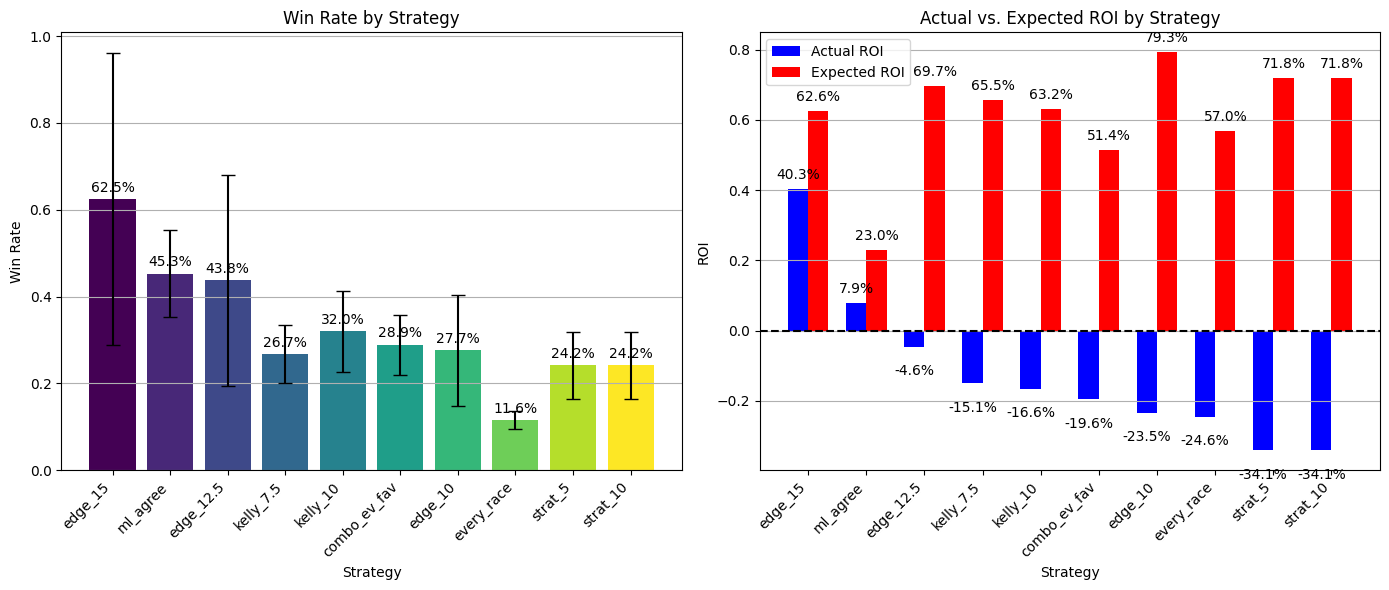

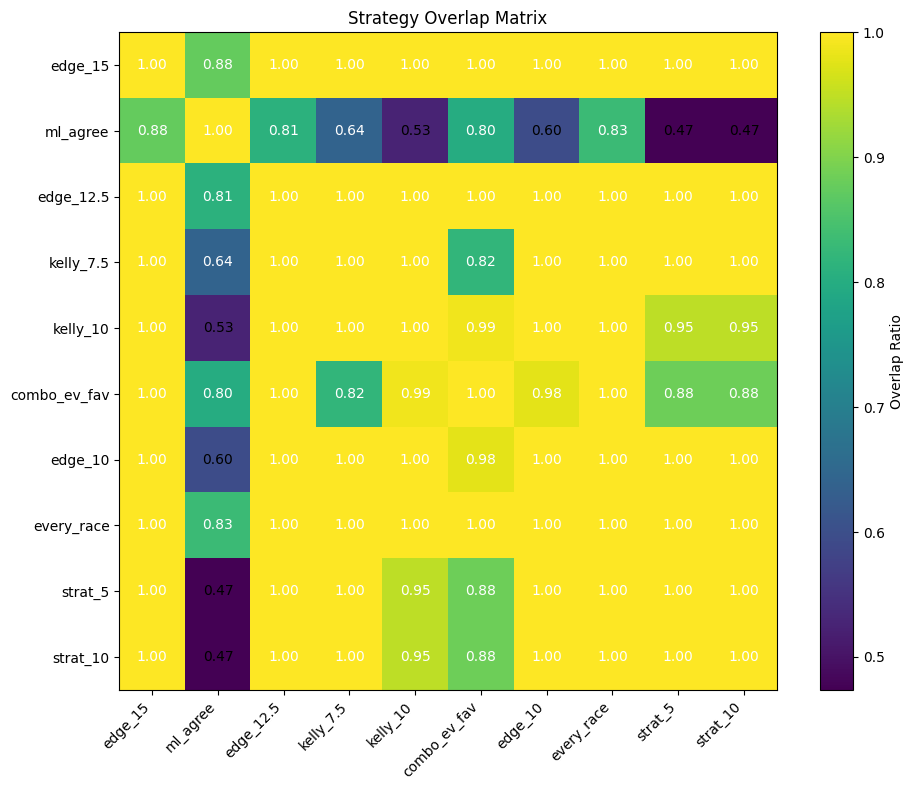

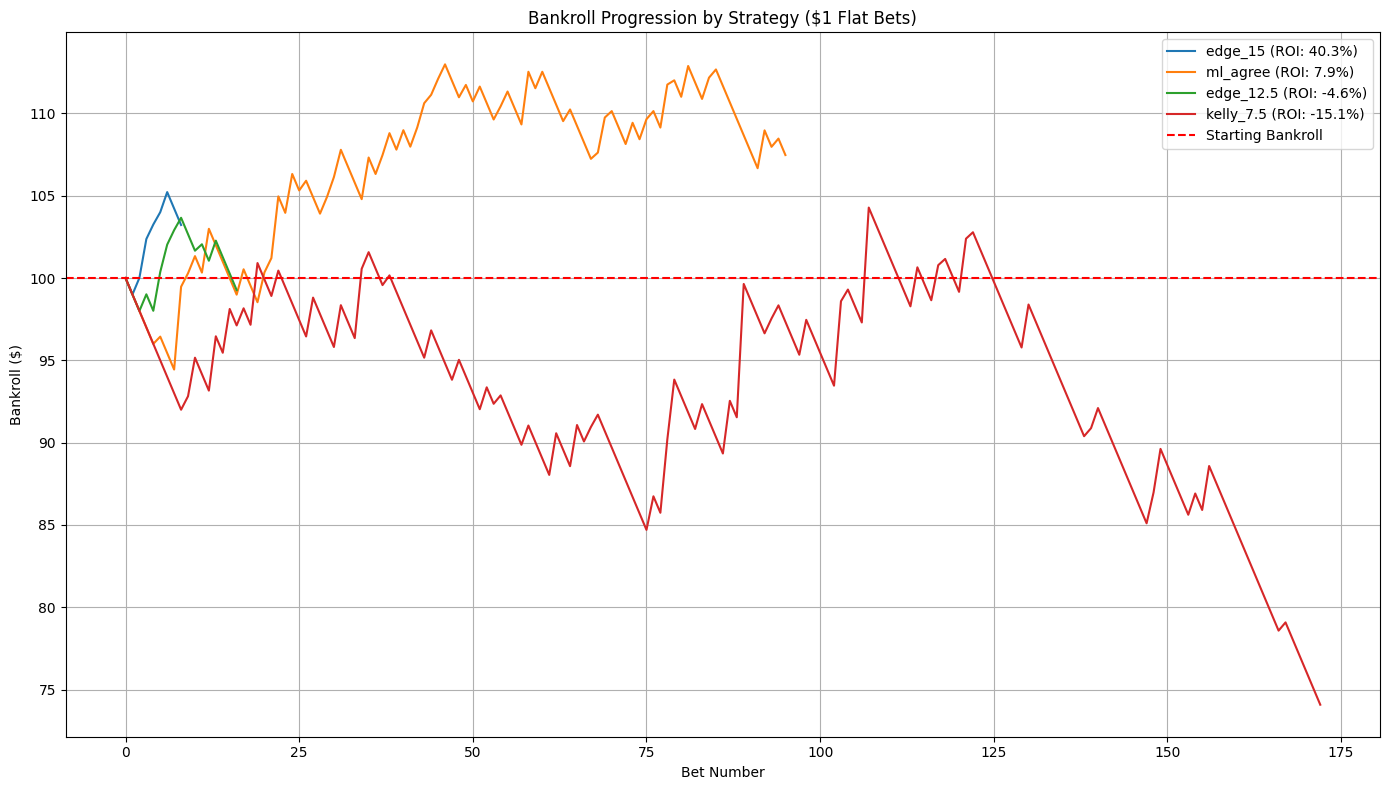

<Figure size 1400x600 with 0 Axes>

posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


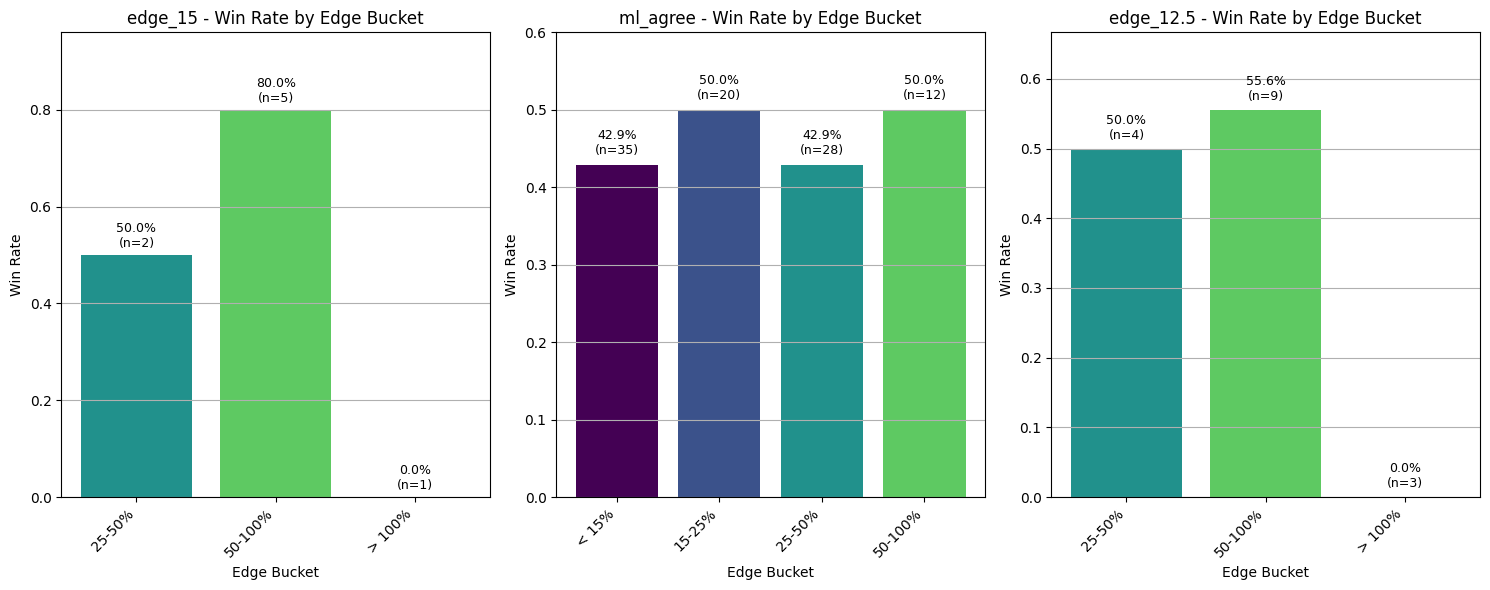


Step 4: Simulating top performing strategy...
Simulating edge_15 strategy with half_kelly staking...


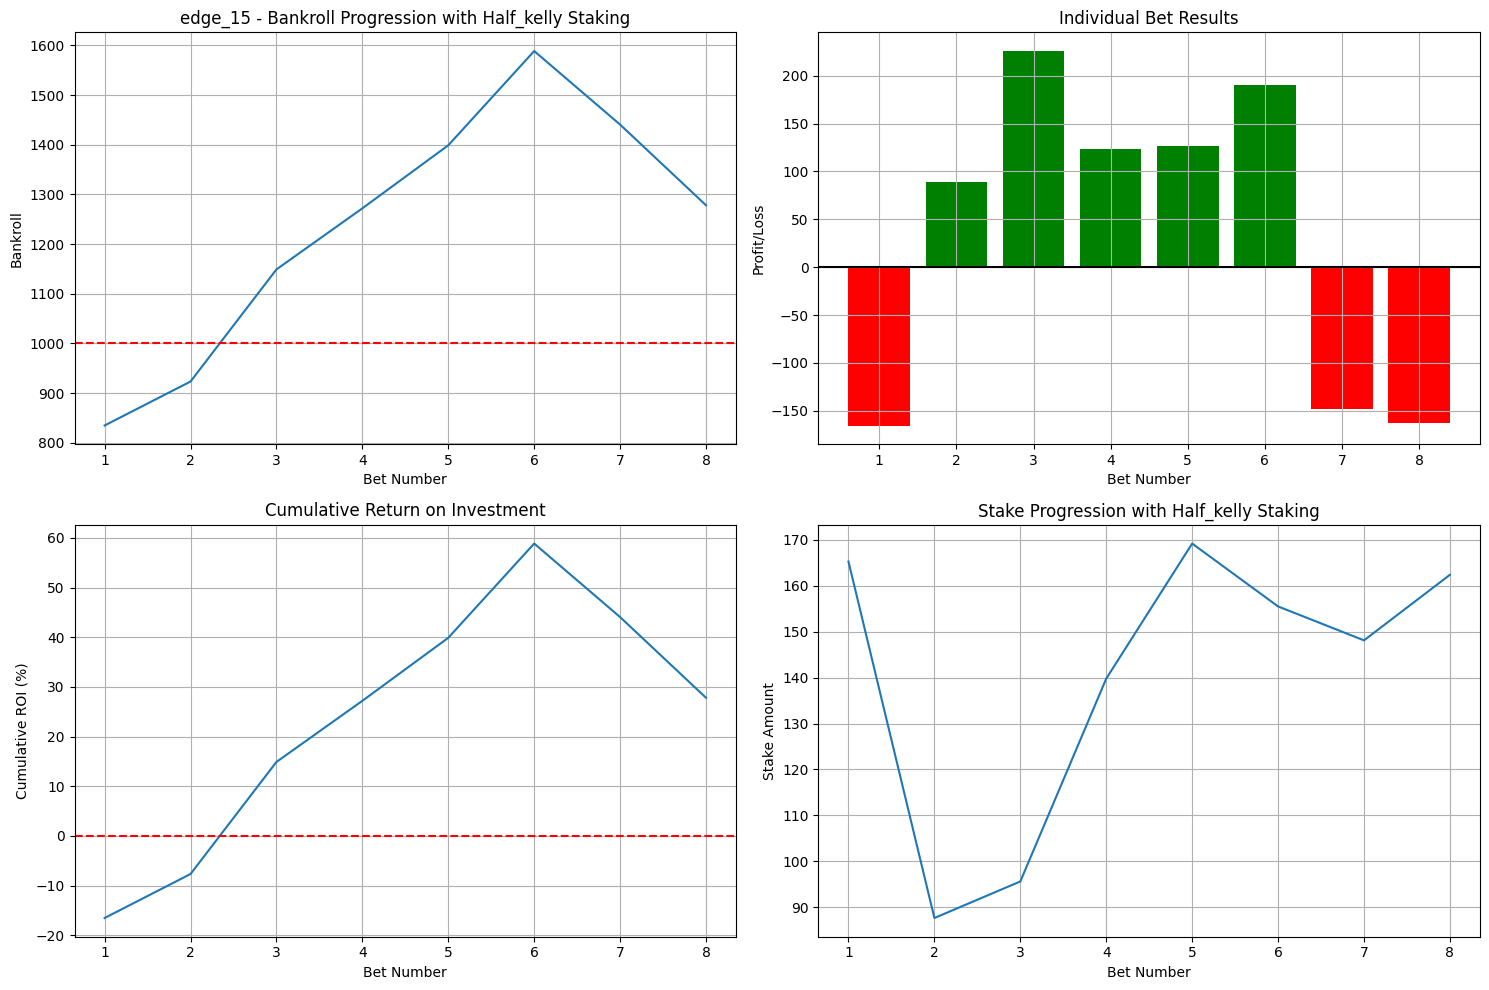


Betting Simulation Results:
Strategy: edge_15 with Half_kelly staking
Starting Bank: $1000.00
Final Bank: $1278.02
Profit/Loss: $278.02 (27.8%)
Total Bets: 8
Winning Bets: 5 (62.5%)
Total Staked: $1123.50
Total Returns: $1401.53
Overall ROI: 24.7%

===== ANALYSIS COMPLETE =====


In [152]:
# Calculate edges between model and market probabilities
df_with_edge = calculate_edge(
    data,
    projected_prob_col='best_win_prob',
    ml_prob_col='ml_probability_normalized',
    # win_paid_col='win_paid',
    group_cols=['date', 'track', 'race'],
    min_edge_pct=15,
    min_prob=0.05
)


df_with_edge['expected_roi'] = np.where(
    df_with_edge['ml_probability_normalized'] > 0,
    (df_with_edge['best_win_prob'] * (1 / df_with_edge['ml_probability_normalized'])) - 1,
    np.nan
)

# Run complete betting strategy analysis
df_with_flags, strategy_results = analyze_all_betting_strategies(
    df_with_edge,
    edge_col='percentage_edge',
    prob_col='best_win_prob',
    won_col='won',
    payout_col='payout_per_dollar',
    custom_strategies=custom_strategies,
    min_edge_pct=15,
    min_prob=0.05
)


==== COMPLETE HORSE RACING ANALYSIS ====

Step 1: Calculating betting edges...

Step 2: Creating and analyzing betting strategies...
===== BETTING STRATEGY ANALYSIS =====

Step 1: Creating betting strategy flags...
Strategy 'every_race': 883 bets (73.3% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'strat_5': 120 bets (10.0% of 1205 entries)
  Description: Edge ≥ 75% and kelly > (≥ 5%)
Strategy 'strat_10': 120 bets (10.0% of 1205 entries)
  Description: Edge ≥ 75% and kelly > (≥ 5%)
Strategy 'edge_10': 47 bets (3.9% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'edge_12.5': 16 bets (1.3% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'edge_15': 8 bets (0.7% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'edge_20': 0 bets (0.0% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'kelly_7.5': 172 bets (14.3% of 1205 entries)
  Description: Kelly stake ≥ 10%
Strategy 'kelly_10': 97 bets (8.0% of 1205 entries)
  Descr

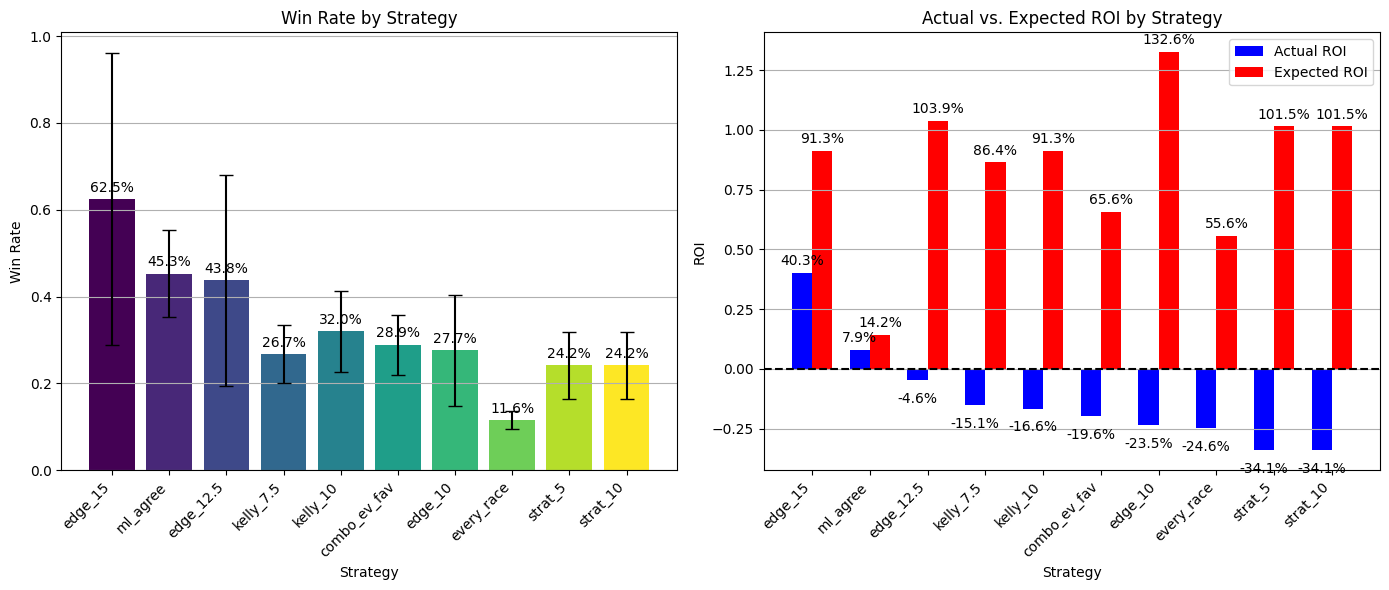

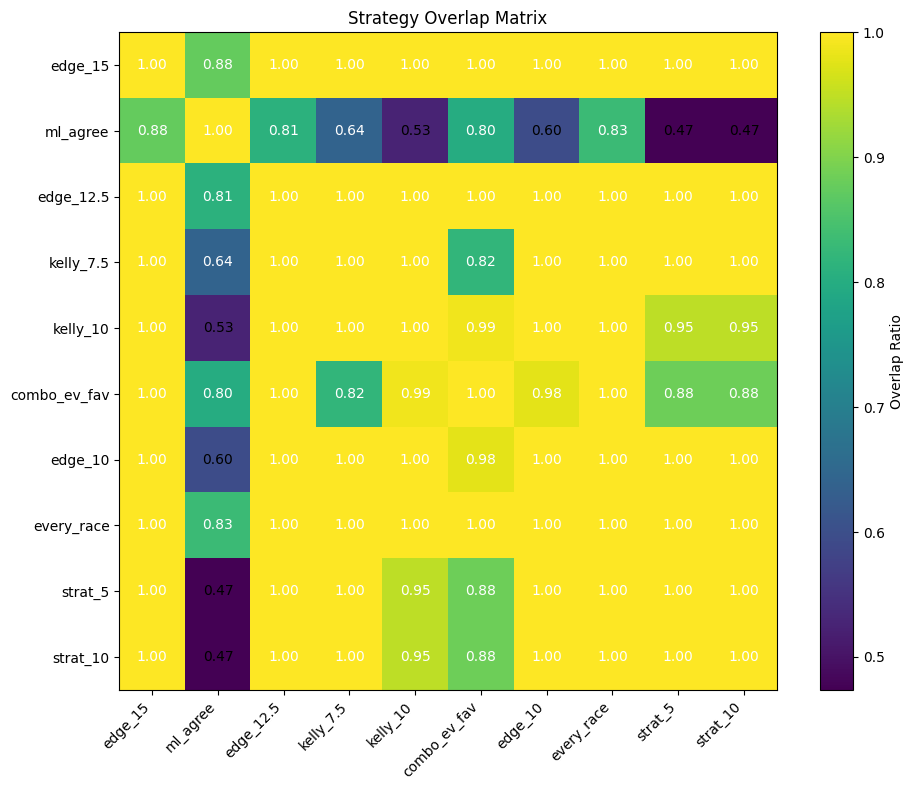

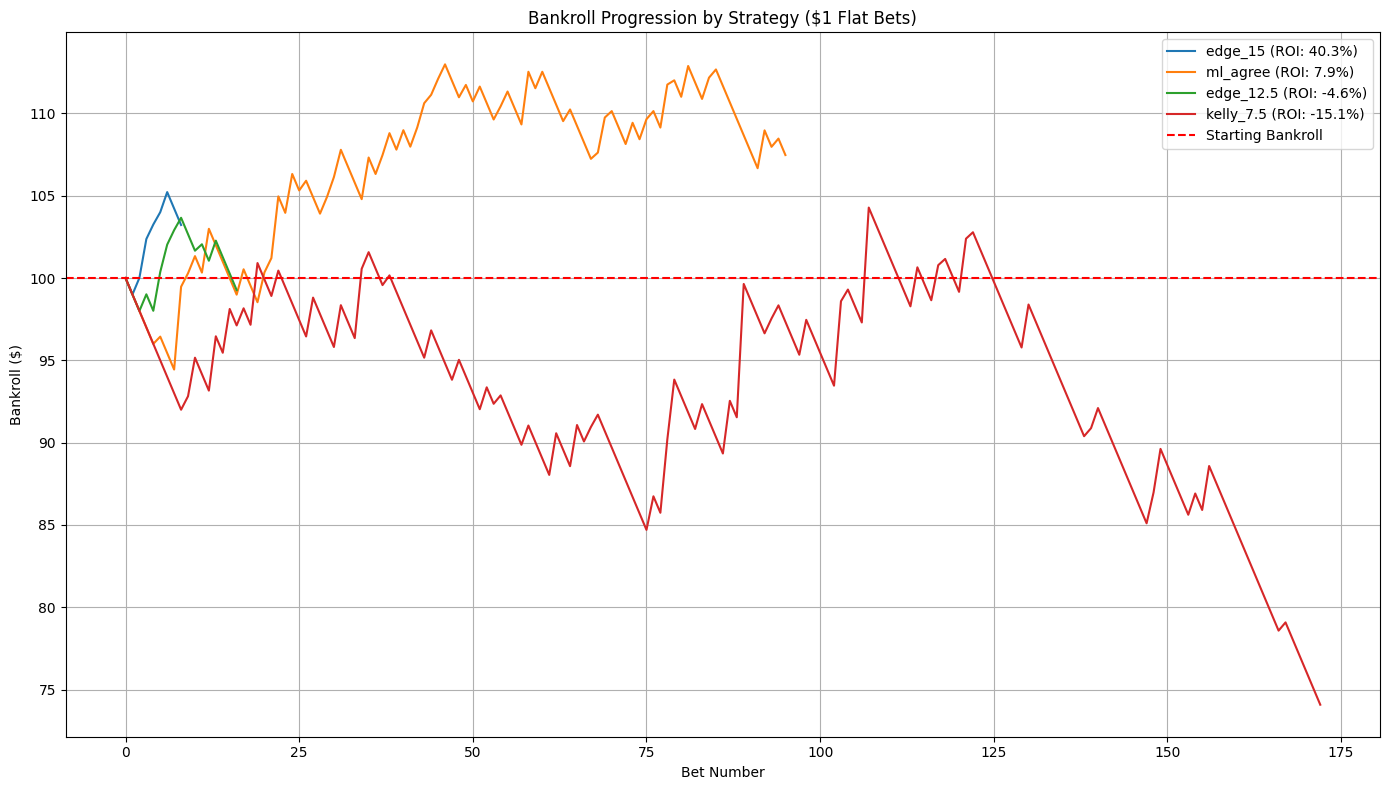

<Figure size 1400x600 with 0 Axes>

posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


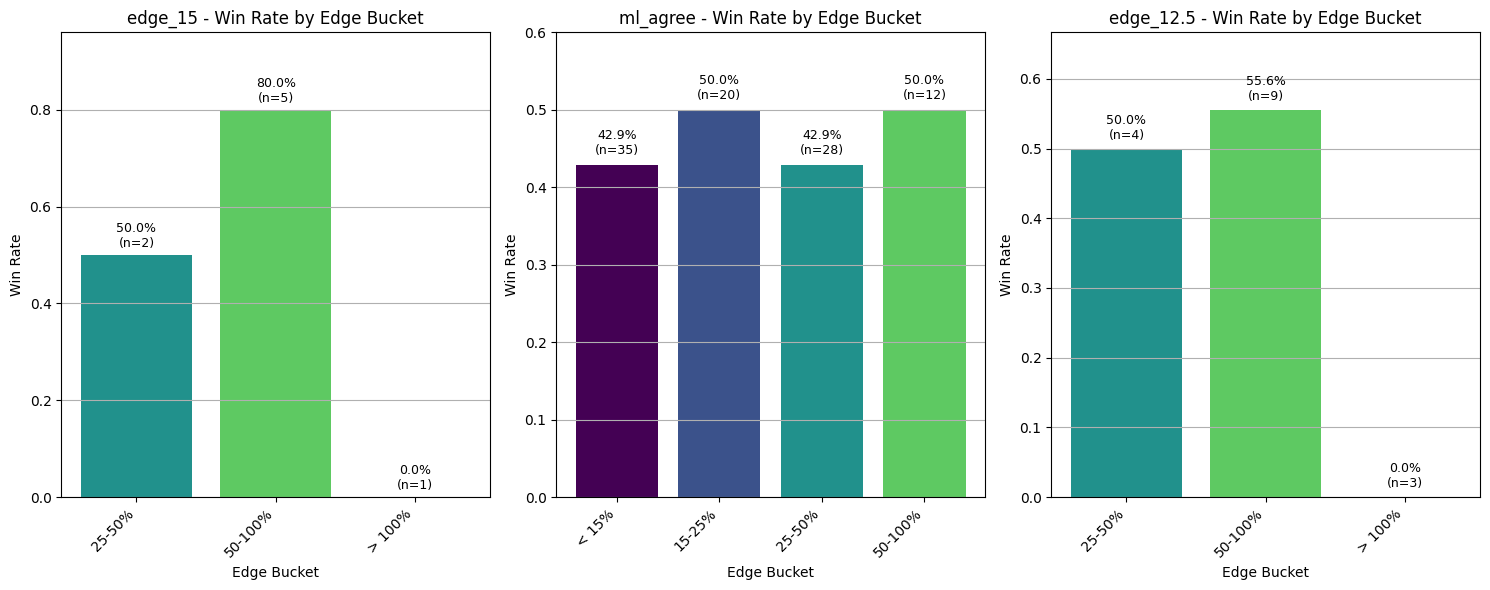


Step 4: Simulating top performing strategy...
Simulating edge_15 strategy with half_kelly staking...


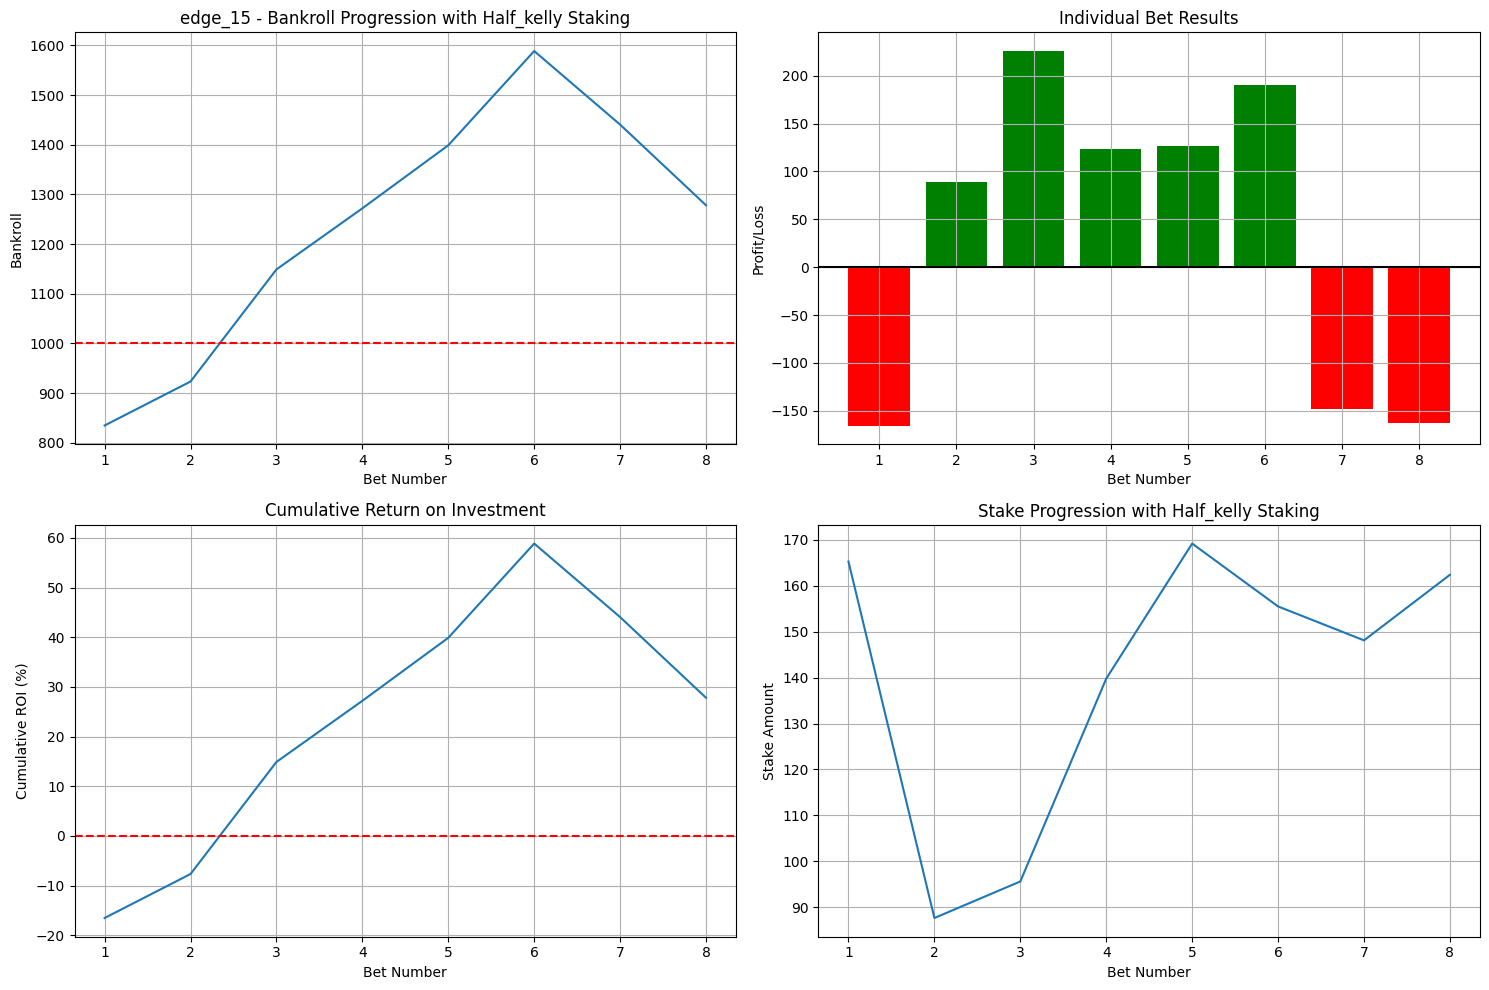


Betting Simulation Results:
Strategy: edge_15 with Half_kelly staking
Starting Bank: $1000.00
Final Bank: $1278.02
Profit/Loss: $278.02 (27.8%)
Total Bets: 8
Winning Bets: 5 (62.5%)
Total Staked: $1123.50
Total Returns: $1401.53
Overall ROI: 24.7%

===== ANALYSIS COMPLETE =====

Step 3: Creating limited versions with one bet per race...
Limited 'is_every_race_bet' to one bet per race based on kelly_stake.
Original bets: 883
Limited bets: 147
Races with bets: 147
Limited 'is_strat_5_bet' to one bet per race based on kelly_stake.
Original bets: 120
Limited bets: 97
Races with bets: 97
Limited 'is_strat_10_bet' to one bet per race based on kelly_stake.
Original bets: 120
Limited bets: 97
Races with bets: 97
Limited 'is_edge_10_bet' to one bet per race based on kelly_stake.
Original bets: 47
Limited bets: 47
Races with bets: 47
Limited 'is_edge_12.5_bet' to one bet per race based on kelly_stake.
Original bets: 16
Limited bets: 16
Races with bets: 16
Limited 'is_edge_15_bet' to one bet per

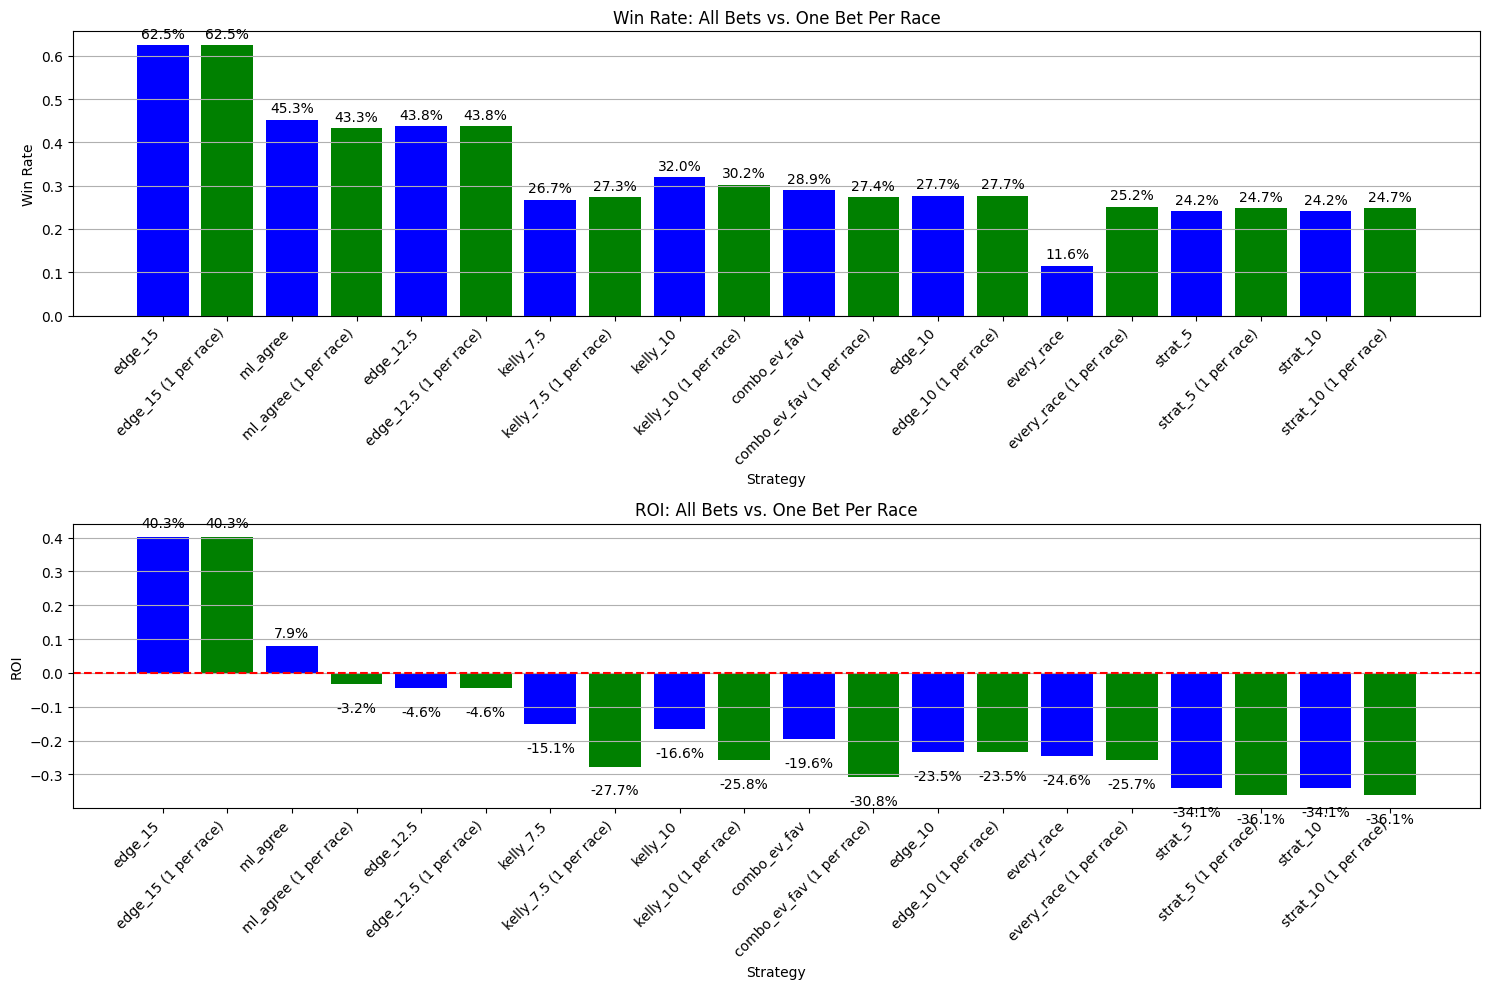


Comparison: All Bets vs. One Bet Per Race
       Strategy  Original Bets  Limited Bets Reduction % Original Win Rate  \
0       edge_15              8             8        0.0%             62.5%   
2     edge_12.5             16            16        0.0%             43.8%   
6       edge_10             47            47        0.0%             27.7%   
7    every_race            883           147       83.4%             11.6%   
8       strat_5            120            97       19.2%             24.2%   
9      strat_10            120            97       19.2%             24.2%   
4      kelly_10             97            86       11.3%             32.0%   
1      ml_agree             95            90        5.3%             45.3%   
5  combo_ev_fav            166           124       25.3%             28.9%   
3     kelly_7.5            172           121       29.7%             26.7%   

  Limited Win Rate Win Rate Diff Original ROI Limited ROI ROI Diff  
0            62.5%          0

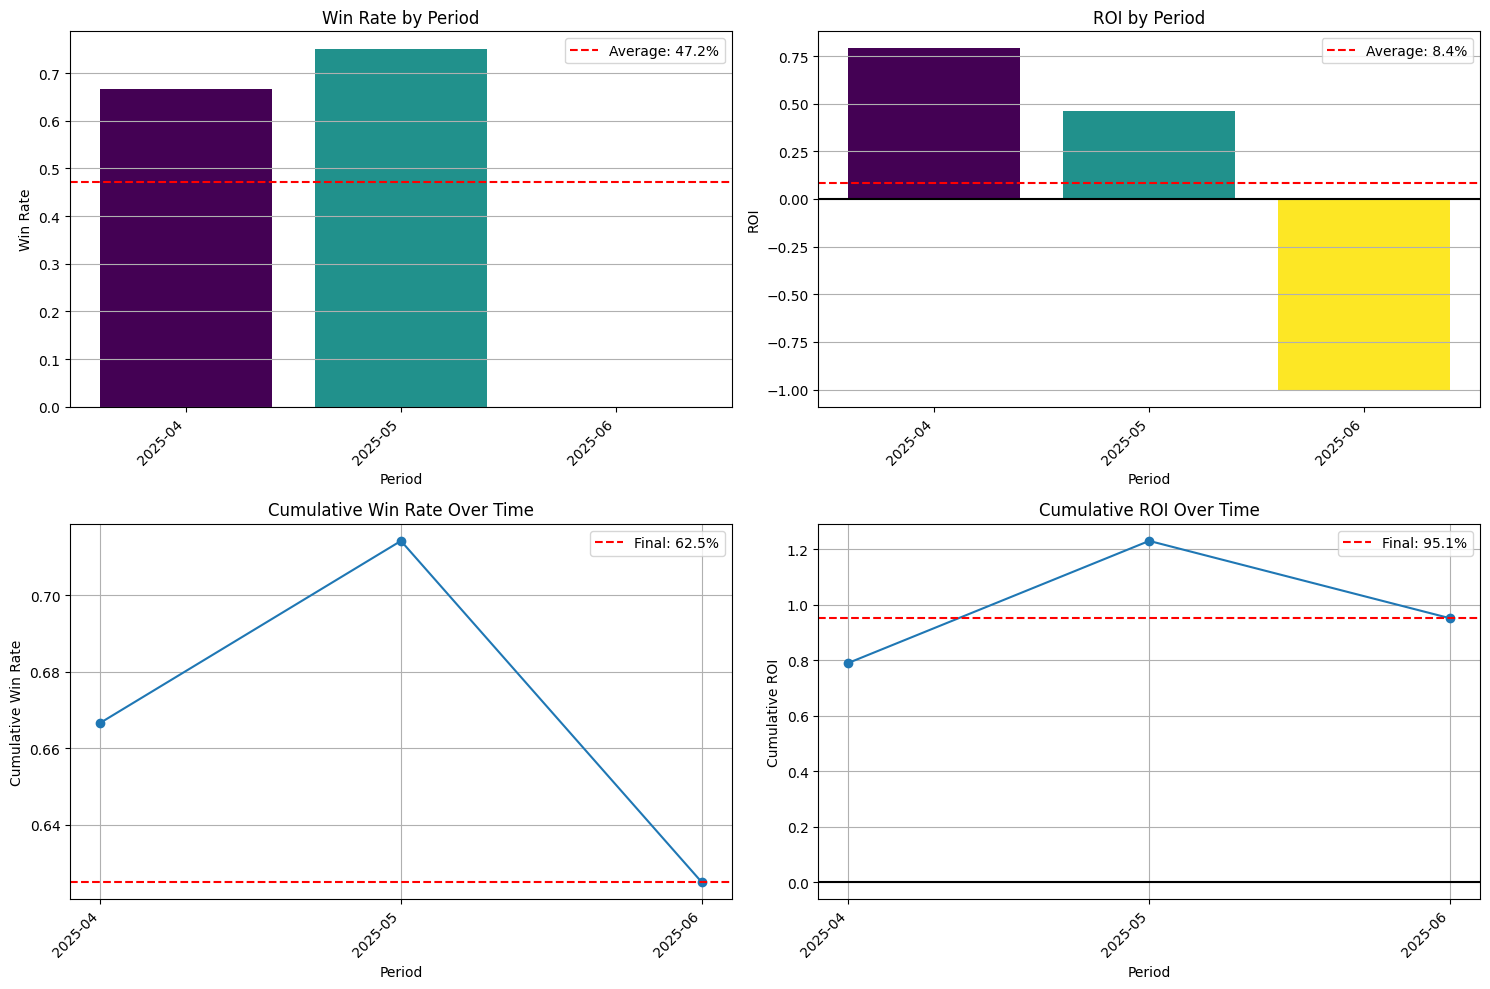


Time Analysis Summary for edge_15_top_per_race Strategy:
Total periods analyzed: 3
Profitable periods: 2 (66.7%)
Average ROI per period: 8.4%
Most profitable period: 2025-04 (ROI: 79.0%)
Least profitable period: 2025-06 (ROI: -100.0%)

==== ANALYSIS COMPLETE ====

No value bets found for upcoming races

==== COMPLETE HORSE RACING ANALYSIS ====

Step 1: Calculating betting edges...

Step 2: Creating and analyzing betting strategies...
===== BETTING STRATEGY ANALYSIS =====

Step 1: Creating betting strategy flags...
Strategy 'every_race': 883 bets (73.3% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'strat_5': 120 bets (10.0% of 1205 entries)
  Description: Edge ≥ 75% and kelly > (≥ 5%)
Strategy 'strat_10': 120 bets (10.0% of 1205 entries)
  Description: Edge ≥ 75% and kelly > (≥ 5%)
Strategy 'edge_10': 47 bets (3.9% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'edge_12.5': 16 bets (1.3% of 1205 entries)
  Description: Expected value ≥ 50%
Strategy 'edge

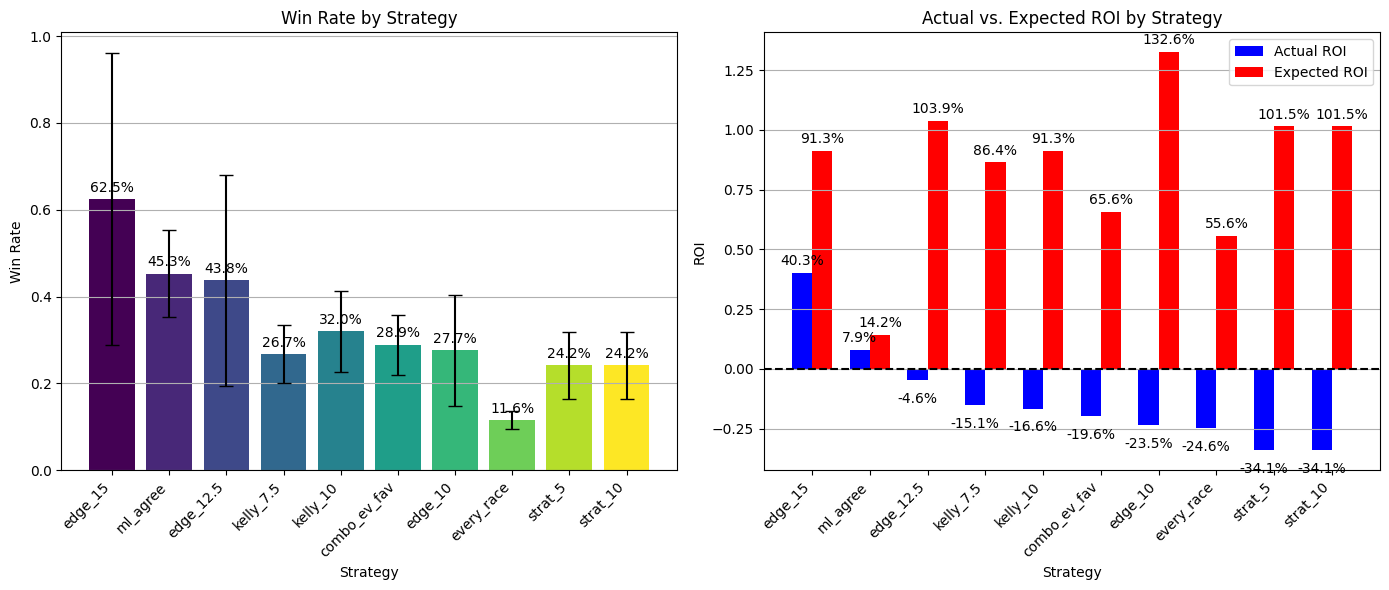

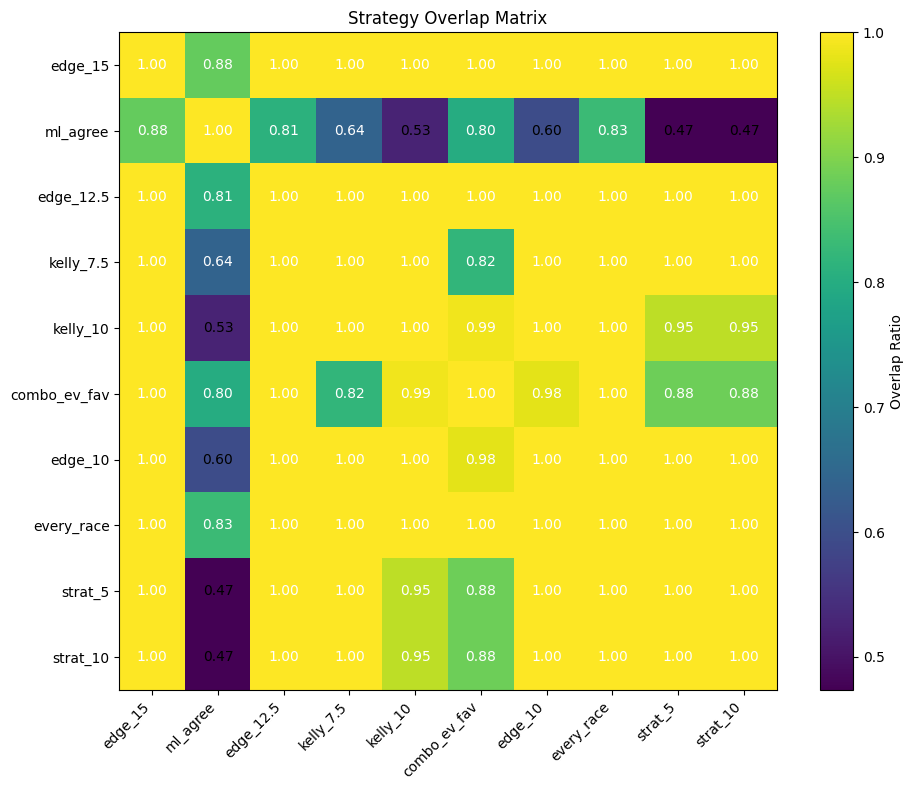

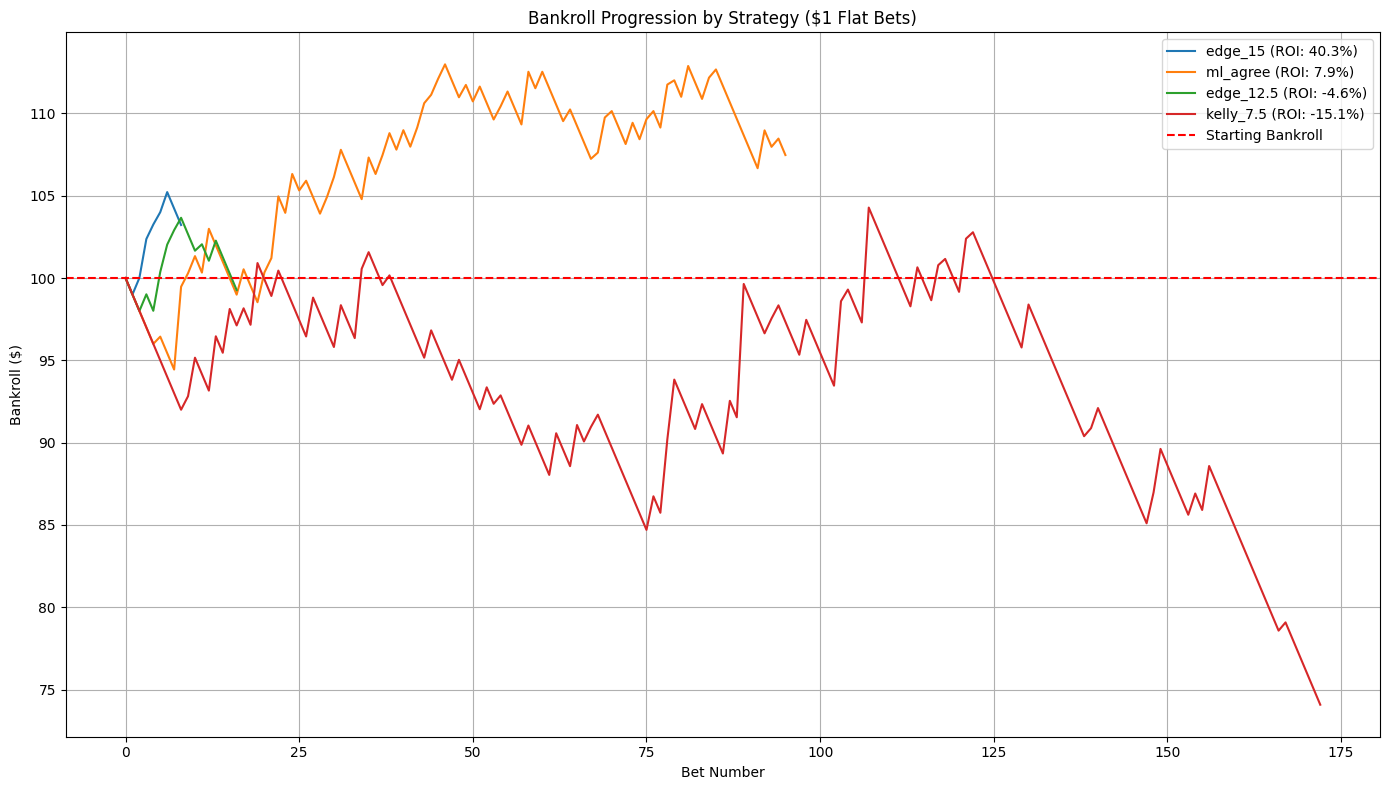

<Figure size 1400x600 with 0 Axes>

posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


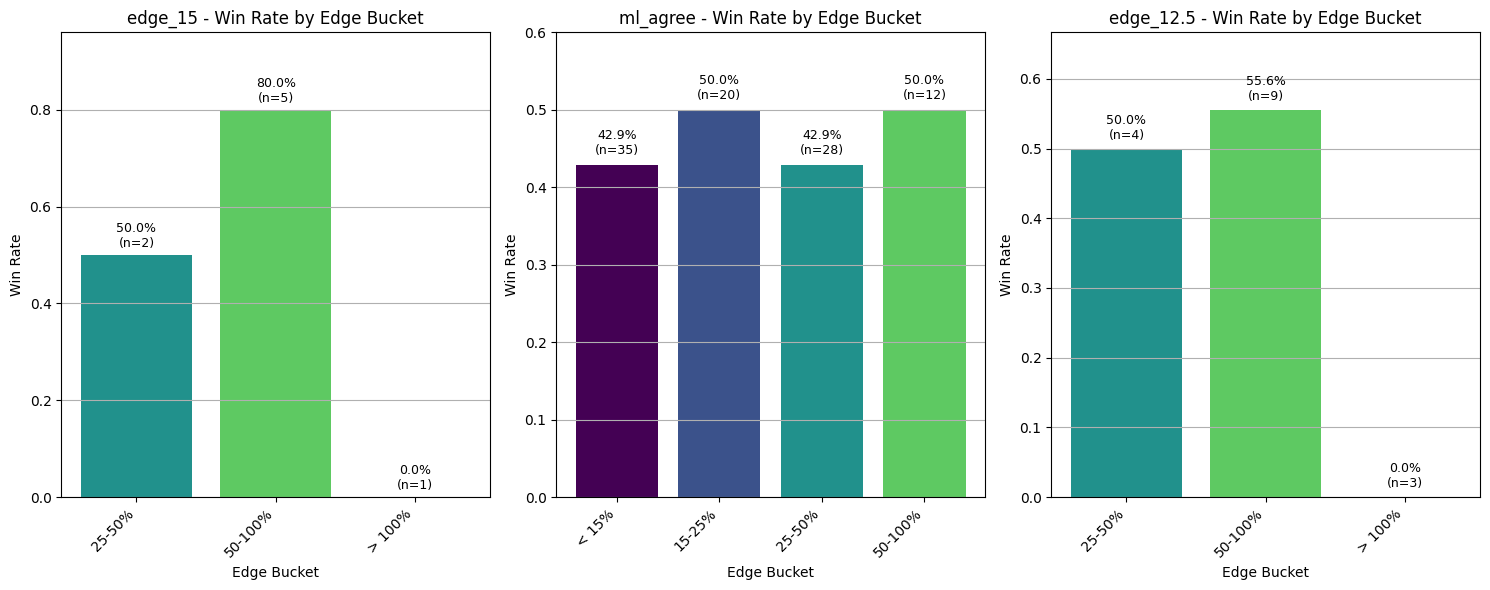


Step 4: Simulating top performing strategy...
Simulating edge_15 strategy with half_kelly staking...


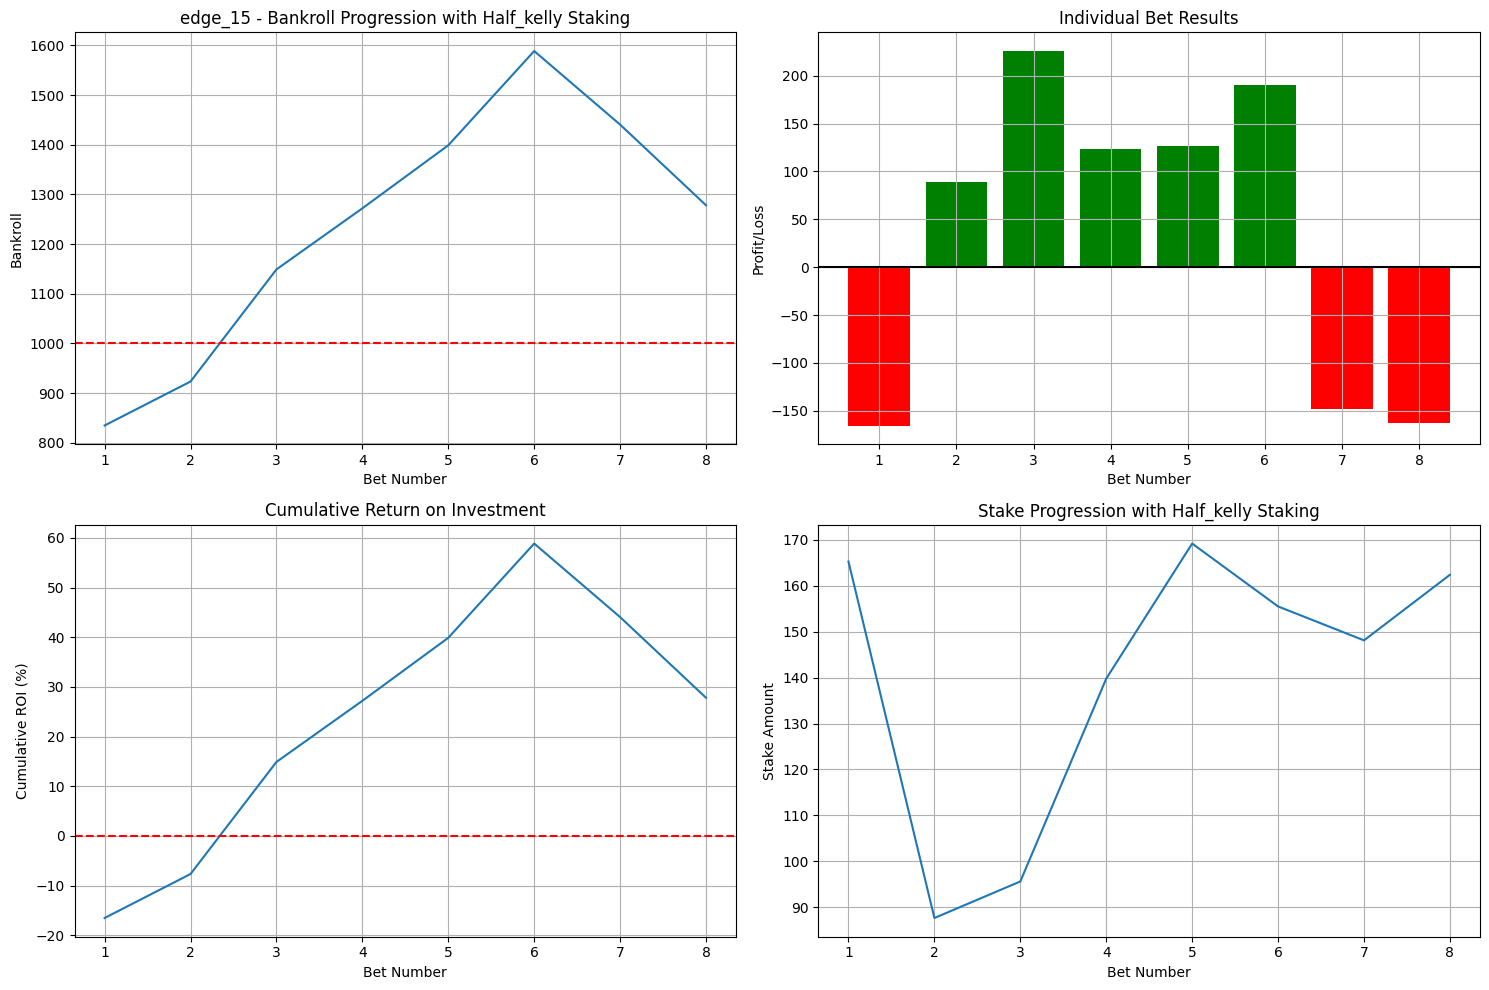


Betting Simulation Results:
Strategy: edge_15 with Half_kelly staking
Starting Bank: $1000.00
Final Bank: $1278.02
Profit/Loss: $278.02 (27.8%)
Total Bets: 8
Winning Bets: 5 (62.5%)
Total Staked: $1123.50
Total Returns: $1401.53
Overall ROI: 24.7%

===== ANALYSIS COMPLETE =====

Step 3: Creating limited versions with one bet per race...
Limited 'is_every_race_bet' to one bet per race based on kelly_stake.
Original bets: 883
Limited bets: 147
Races with bets: 147
Limited 'is_strat_5_bet' to one bet per race based on kelly_stake.
Original bets: 120
Limited bets: 97
Races with bets: 97
Limited 'is_strat_10_bet' to one bet per race based on kelly_stake.
Original bets: 120
Limited bets: 97
Races with bets: 97
Limited 'is_edge_10_bet' to one bet per race based on kelly_stake.
Original bets: 47
Limited bets: 47
Races with bets: 47
Limited 'is_edge_12.5_bet' to one bet per race based on kelly_stake.
Original bets: 16
Limited bets: 16
Races with bets: 16
Limited 'is_edge_15_bet' to one bet per

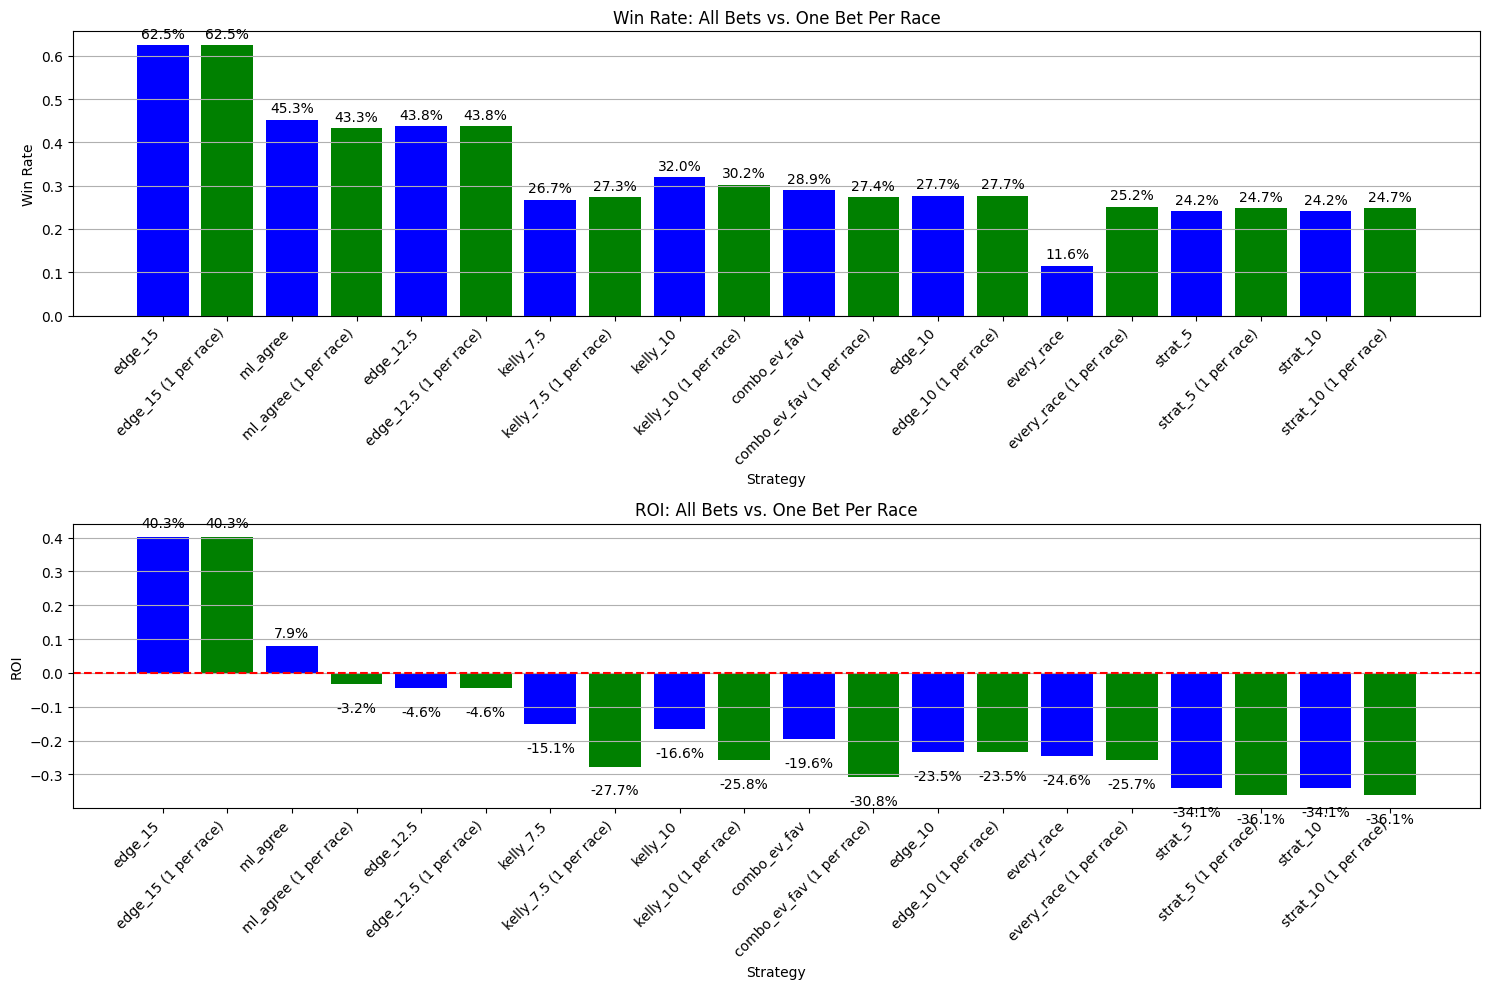


Comparison: All Bets vs. One Bet Per Race
       Strategy  Original Bets  Limited Bets Reduction % Original Win Rate  \
0       edge_15              8             8        0.0%             62.5%   
2     edge_12.5             16            16        0.0%             43.8%   
6       edge_10             47            47        0.0%             27.7%   
7    every_race            883           147       83.4%             11.6%   
8       strat_5            120            97       19.2%             24.2%   
9      strat_10            120            97       19.2%             24.2%   
4      kelly_10             97            86       11.3%             32.0%   
1      ml_agree             95            90        5.3%             45.3%   
5  combo_ev_fav            166           124       25.3%             28.9%   
3     kelly_7.5            172           121       29.7%             26.7%   

  Limited Win Rate Win Rate Diff Original ROI Limited ROI ROI Diff  
0            62.5%          0

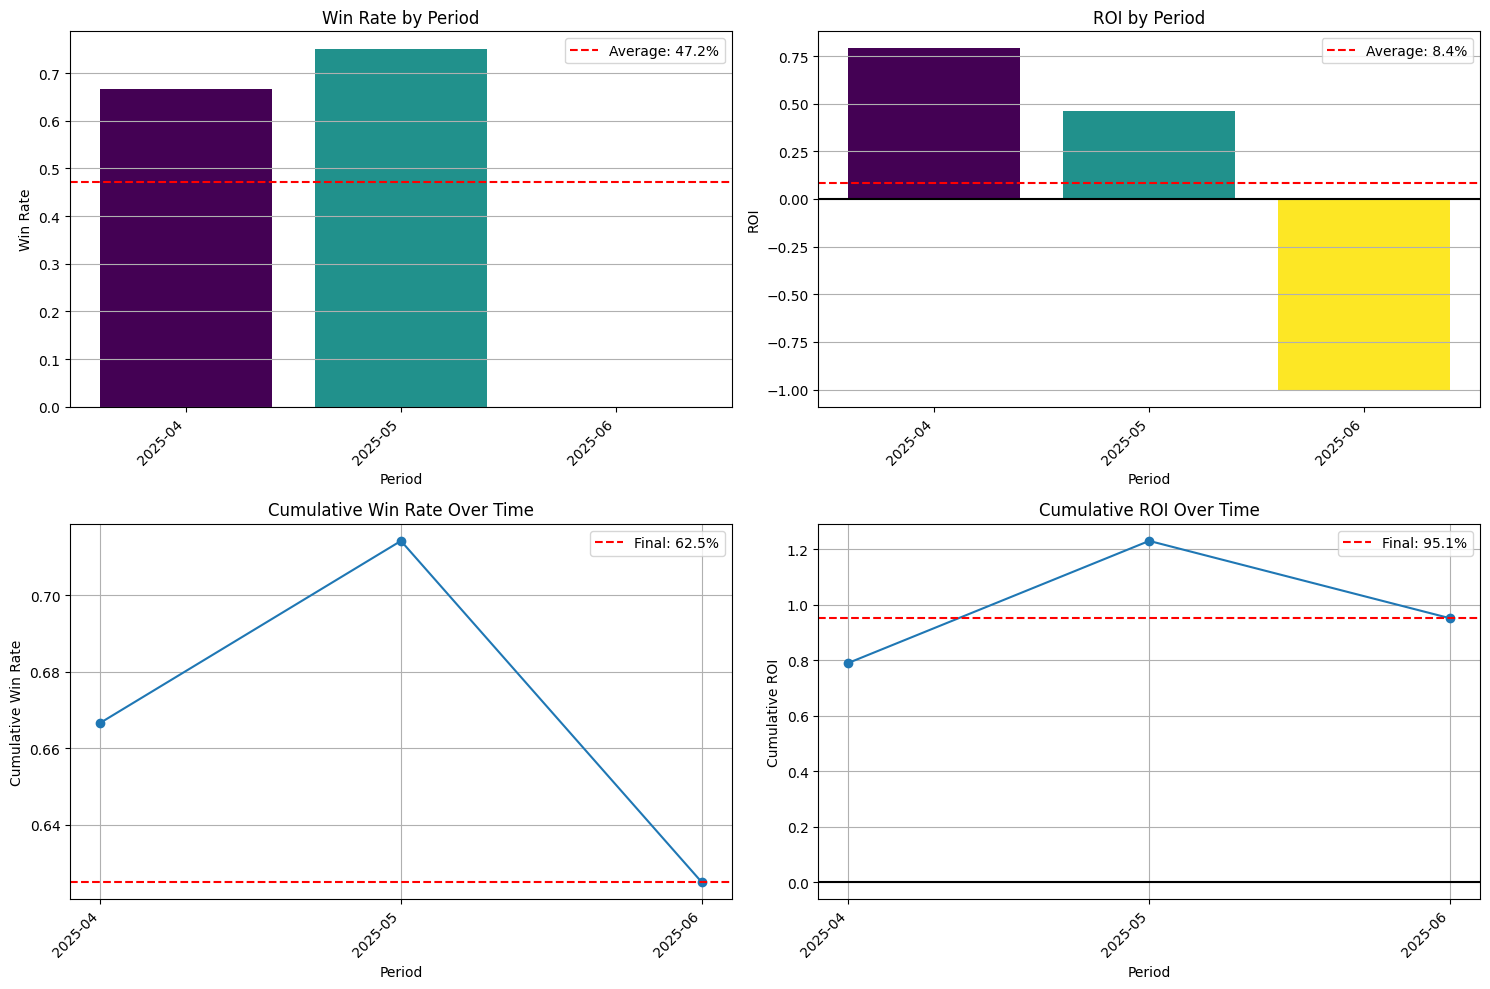


Time Analysis Summary for edge_15_top_per_race Strategy:
Total periods analyzed: 3
Profitable periods: 2 (66.7%)
Average ROI per period: 8.4%
Most profitable period: 2025-04 (ROI: 79.0%)
Least profitable period: 2025-06 (ROI: -100.0%)

==== ANALYSIS COMPLETE ====

No value bets found for upcoming races


In [153]:
# Run the complete analysis with one-bet-per-race limitation
edge_df, strategy_df, results_df, comparison_df = complete_horse_racing_analysis(
    data,  # Your preprocessed DataFrame
    projected_prob_col='best_win_prob',
    ml_prob_col='ml_probability_normalized',
    win_paid_col='win_paid',
    won_col='won',
    horse_col='horse',
    edge_threshold=15,
    prob_threshold=0.05,
    limit_one_per_race=True  # Enable one-bet-per-race limitation
)

# Get top value bets for next racing day - one bet per race
if 'date' in strategy_df.columns:
    today = pd.Timestamp.today().normalize()
    upcoming_races = strategy_df[strategy_df['date'] >= today]
    
    # Find the best limited strategy
    if comparison_df is not None:
        best_limited = comparison_df.iloc[0]['Strategy'] + ' (1 per race)'
        best_limited_raw = best_limited.replace(' (1 per race)', '')
        top_bet_col = f"is_{best_limited_raw}_bet_top_per_race"
        
        if top_bet_col in strategy_df.columns:
            top_bets = upcoming_races[upcoming_races[top_bet_col] == 1].sort_values('date')
            
            if len(top_bets) > 0:
                print("\nTop Value Bets for Upcoming Races (One Per Race):")
                display_cols = ['date', 'track', 'race', 'horse', 'ml_odds', 
                              'projected_win_probability', 'percentage_edge', 'expected_roi']
                display_cols = [col for col in display_cols if col in top_bets.columns]
                print(top_bets[display_cols])
            else:
                print("\nNo value bets found for upcoming races")# Run the complete analysis with one-bet-per-race limitation
edge_df, strategy_df, results_df, comparison_df = complete_horse_racing_analysis(
    data,  # Your preprocessed DataFrame
    projected_prob_col='best_win_prob',
    ml_prob_col='ml_probability_normalized',
    won_col='won',
    horse_col='horse',
    edge_threshold=15,
    prob_threshold=0.05,
    limit_one_per_race=True  # Enable one-bet-per-race limitation
)

# Get top value bets for next racing day - one bet per race
if 'date' in strategy_df.columns:
    today = pd.Timestamp.today().normalize()
    upcoming_races = strategy_df[strategy_df['date'] >= today]
    
    # Find the best limited strategy
    if comparison_df is not None:
        best_limited = comparison_df.iloc[0]['Strategy'] + ' (1 per race)'
        best_limited_raw = best_limited.replace(' (1 per race)', '')
        top_bet_col = f"is_{best_limited_raw}_bet_top_per_race"
        
        if top_bet_col in strategy_df.columns:
            top_bets = upcoming_races[upcoming_races[top_bet_col] == 1].sort_values('date')
            
            if len(top_bets) > 0:
                print("\nTop Value Bets for Upcoming Races (One Per Race):")
                display_cols = ['date', 'track', 'race', 'horse', 'ml_odds', 
                              'projected_win_probability', 'percentage_edge', 'expected_roi']
                display_cols = [col for col in display_cols if col in top_bets.columns]
                print(top_bets[display_cols])
            else:
                print("\nNo value bets found for upcoming races")

In [154]:

df_with_edge[['edge','kelly_stake']].corr()


,edge,kelly_stake
edge,1.000000,0.903663
kelly_stake,0.903663,1.000000



Top 0% of horses with highest kelly*edge:
147
0.6748299319727891 0.785578231292517 0.922721088435374

Top 10% of horses with highest kelly*edge:
132
0.6712121212121211 0.6931818181818182 0.878939393939394

Top 20% of horses with highest kelly*edge:
117
0.6531623931623932 0.6188034188034187 0.8364102564102562

Top 30% of horses with highest kelly*edge:
103
0.6205825242718446 0.6020388349514564 0.8333009708737863

Top 40% of horses with highest kelly*edge:
88
0.5795454545454546 0.5740909090909091 0.7978409090909092

Top 50% of horses with highest kelly*edge:
74
0.668918918918919 0.6678378378378379 0.8121621621621621

Top 55% of horses with highest kelly*edge:
66
0.6268181818181818 0.6201515151515151 0.7913636363636363

Top 60% of horses with highest kelly*edge:
59
0.6689830508474576 0.6349152542372881 0.7561016949152543

Top 65% of horses with highest kelly*edge:
52
0.6917307692307693 0.6848076923076925 0.8307692307692307

Top 70% of horses with highest kelly*edge:
44
0.8175 0.707954545

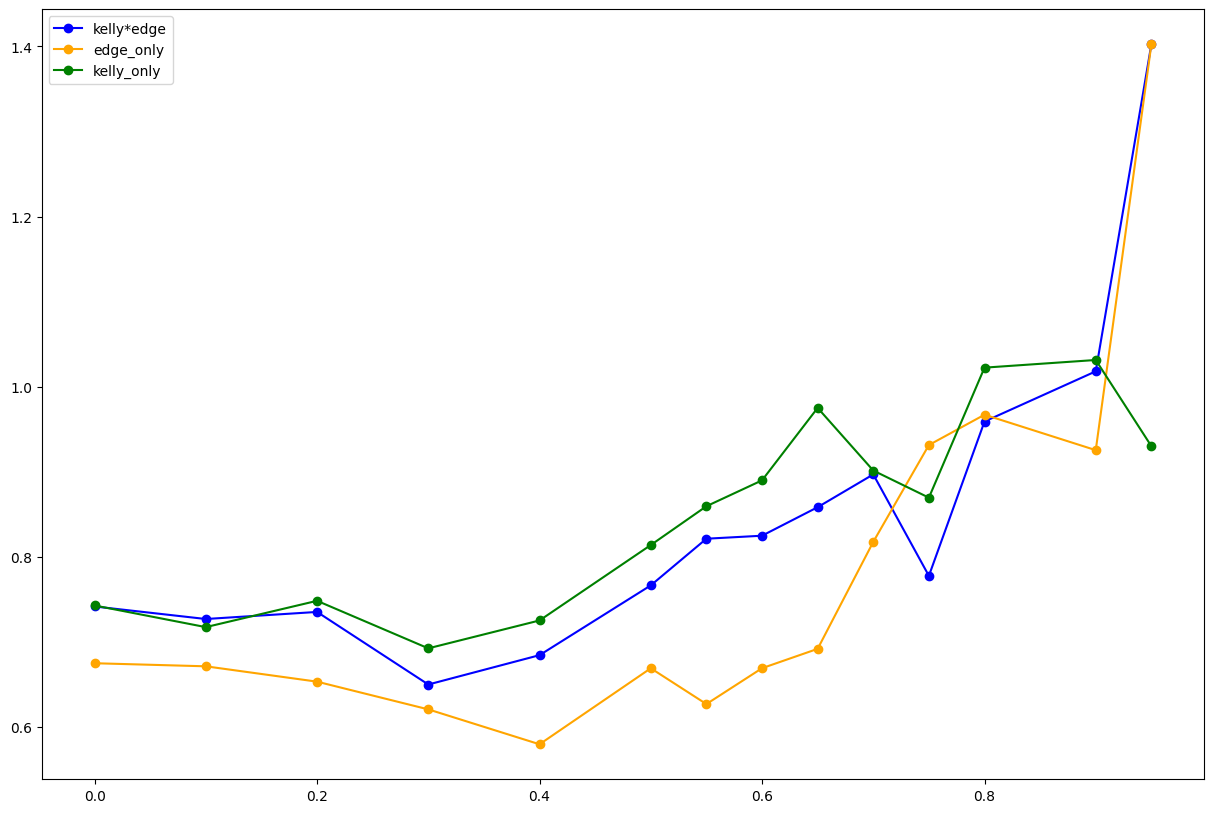

In [155]:

# data['payout_per_dollar'] = data['win_paid'].replace({'\$': '', ',': ''}, regex=True).astype(float)
# data['payout_per_dollar'] = data['payout_per_dollar'].apply(lambda x: x / 2 if x > 0 else 0)
df_with_edge['place_payout'] = df_with_edge['place_paid'].replace({'\$': '', ',': ''}, regex=True).astype(float)
df_with_edge['place_payout'] = df_with_edge['place_payout'].apply(lambda x: x / 2 if x > 0 else 0)

df_with_edge['show_payout'] = df_with_edge['show_paid'].replace({'\$': '', ',': ''}, regex=True).astype(float)
df_with_edge['show_payout'] = df_with_edge['show_payout'].apply(lambda x: x / 2 if x > 0 else 0)
df_with_edge['kelly*edge'] = df_with_edge['kelly_stake'] * df_with_edge['edge'] 
    
edge_return_data = []
for threshold in [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9, 0.95]:
    df_with_edge['top_horse'] = df_with_edge.groupby(['date', 'track', 'race'])['edge'].transform(lambda x: x == x.max()).astype(int) 
    df_with_edge['second_horse'] = df_with_edge.groupby(['date', 'track', 'race'])['edge'].transform(lambda x: x == x.nlargest(2).iloc[-1]).astype(int)
    df_with_edge['third_horse'] = df_with_edge.groupby(['date', 'track', 'race'])['edge'].transform(lambda x: x == x.nlargest(3).iloc[-1]).astype(int)

    top_horses = df_with_edge[df_with_edge['top_horse'] == 1].copy().reset_index(drop=True)
    quantile = top_horses['edge'].quantile(threshold)
    selective_return = top_horses[top_horses['edge'] >= quantile]
    print(f"\nTop {threshold*100:.0f}% of horses with highest kelly*edge:")
    print(len(selective_return))
    print(selective_return['payout_per_dollar'].mean(), selective_return['place_payout'].mean(), selective_return['show_payout'].mean())
    edge_return_data.append({
        'threshold': threshold,
        'mean_payout_per_dollar': selective_return['payout_per_dollar'].mean(),
        'mean_place_payout': selective_return['place_payout'].mean(),
        'mean_show_payout': selective_return['show_payout'].mean()
    })
    
kelly_return_data = []
for threshold in [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9, 0.95]:
    df_with_edge['top_horse'] = df_with_edge.groupby(['date', 'track', 'race'])['kelly_stake'].transform(lambda x: x == x.max()).astype(int) 
    df_with_edge['second_horse'] = df_with_edge.groupby(['date', 'track', 'race'])['kelly_stake'].transform(lambda x: x == x.nlargest(2).iloc[-1]).astype(int)
    df_with_edge['third_horse'] = df_with_edge.groupby(['date', 'track', 'race'])['kelly_stake'].transform(lambda x: x == x.nlargest(3).iloc[-1]).astype(int)

    top_horses = df_with_edge[df_with_edge['top_horse'] == 1].copy().reset_index(drop=True)
    quantile = top_horses['kelly_stake'].quantile(threshold)
    selective_return = top_horses[top_horses['kelly_stake'] >= quantile]
    # print(f"\nTop {threshold*100:.0f}% of horses with highest kelly*edge:")
    # print(len(selective_return))
    # print(selective_return['payout_per_dollar'].mean(), selective_return['place_payout'].mean(), selective_return['show_payout'].mean())
    kelly_return_data.append({
        'threshold': threshold,
        'mean_payout_per_dollar': selective_return['payout_per_dollar'].mean(),
        'mean_place_payout': selective_return['place_payout'].mean(),
        'mean_show_payout': selective_return['show_payout'].mean()
    })
    
kelly_edge_return_data = []
for threshold in [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9, 0.95]:
    
    
    df_with_edge['top_horse'] = df_with_edge.groupby(['date', 'track', 'race'])['kelly*edge'].transform(lambda x: x == x.max()).astype(int) 
    df_with_edge['second_horse'] = df_with_edge.groupby(['date', 'track', 'race'])['kelly*edge'].transform(lambda x: x == x.nlargest(2).iloc[-1]).astype(int)
    df_with_edge['third_horse'] = df_with_edge.groupby(['date', 'track', 'race'])['kelly*edge'].transform(lambda x: x == x.nlargest(3).iloc[-1]).astype(int)

    top_horses = df_with_edge[df_with_edge['top_horse'] == 1].copy().reset_index(drop=True)
    quantile = top_horses['kelly*edge'].quantile(threshold)
    selective_return = top_horses[top_horses['kelly*edge'] >= quantile]
    print(f"\nTop {threshold*100:.0f}% of horses with highest kelly*edge:")
    print(len(selective_return))
    print(selective_return['payout_per_dollar'].mean(), selective_return['place_payout'].mean(), selective_return['show_payout'].mean())
    kelly_edge_return_data.append({
        'threshold': threshold,
        'mean_payout_per_dollar': selective_return['payout_per_dollar'].mean(),
        'mean_place_payout': selective_return['place_payout'].mean(),
        'mean_show_payout': selective_return['show_payout'].mean()
    })
    
kelly_edge_return_data = pd.DataFrame(kelly_edge_return_data)
edge_return_data = pd.DataFrame(edge_return_data)
kelly_return_data = pd.DataFrame(kelly_return_data)

plt.figure(figsize=(15, 10))
plt.plot(kelly_edge_return_data['threshold'], kelly_edge_return_data['mean_payout_per_dollar'], marker='o', color='blue', label='kelly*edge')
plt.plot(edge_return_data['threshold'], edge_return_data['mean_payout_per_dollar'], marker='o', color='orange', label='edge_only')
plt.plot(kelly_return_data['threshold'], kelly_return_data['mean_payout_per_dollar'], marker='o', color='green', label='kelly_only')

plt.legend()



In [156]:
print(top_horses['kelly*edge'].quantile(0.65))

0.011688183485291548


<Axes: xlabel='payout_per_dollar', ylabel='Count'>

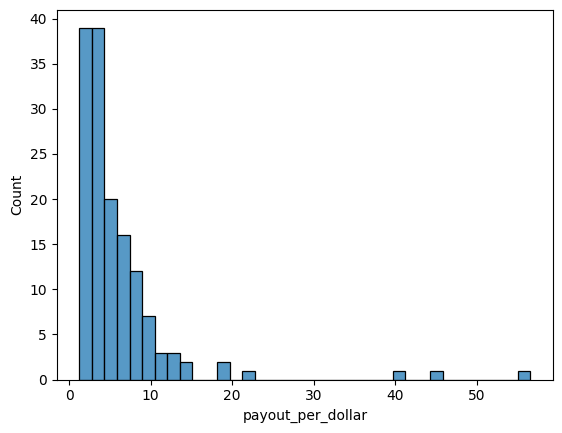

In [157]:
sns.histplot(df_with_edge.groupby(['global_race_number'])['payout_per_dollar'].max())

In [158]:
top_horses

,date,track,race,horse,form,time,composite,has_cappers,sweep,hersh,...,expected_value,expected_roi,kelly_stake,half_kelly,place_payout,show_payout,kelly*edge,top_horse,second_horse,third_horse
0,2025-04-18,keeneland,1,1,112.0,89.0,201.00,NaN,NaN,NaN,...,0.228057,0.228057,0.264857,0.132429,0.00,0.00,0.032456,1,0,0
1,2025-04-18,keeneland,6,3,74.0,103.0,177.00,NaN,NaN,NaN,...,0.174826,0.174826,0.219358,0.109679,0.00,0.00,0.021341,1,0,0
2,2025-04-18,keeneland,7,2,64.0,99.0,163.00,NaN,NaN,NaN,...,1.036029,1.036029,0.094860,0.047430,0.00,0.00,0.008244,1,0,0
3,2025-04-18,keeneland,8,8,97.0,114.0,211.00,NaN,NaN,NaN,...,0.734533,0.734533,0.063235,0.031617,0.00,0.00,0.003682,1,0,0
4,2025-04-18,keeneland,9,7,94.0,124.0,218.00,NaN,NaN,NaN,...,0.655302,0.655302,0.138541,0.069270,0.00,0.00,0.015844,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
142,2025-06-06,saratoga,10,11,94.0,120.0,214.27,1.0,NaN,NaN,...,0.905787,0.905787,0.118363,0.059182,2.85,2.30,0.012391,1,0,0
143,2025-06-06,saratoga,11,5,86.5,115.0,201.90,1.0,NaN,NaN,...,1.231201,1.231201,0.077096,0.038548,0.00,0.00,0.005594,1,0,0
144,2025-06-06,saratoga,12,6,97.0,121.0,218.67,1.0,NaN,NaN,...,1.136262,1.136262,0.081281,0.040641,0.00,1.60,0.006166,1,0,0
145,2025-06-06,saratoga,13,8,104.0,122.0,227.07,1.0,NaN,NaN,...,0.136313,0.136313,0.058029,0.029015,2.00,1.45,0.002362,1,0,0


In [159]:
# strategy_df = limit_all_strategies_to_one_bet_per_race(
#     strategy_df,
#     selection_col='expected_roi',  # Use expected ROI to select best bet
#     group_cols=valid_group_cols,
#     higher_is_better=True
# )

Backtest Experts


# TODAY

In [160]:
def load_todays_projections():
    
    projections = pd.read_csv('../data/picks_v2/horseracing - 10_31.csv')
    
    projections['Form'] = projections['Form'] + projections['Fudge'].fillna(0)
    
    projections = projections.drop(columns=['ML' ,'Fudge'])
    projections['Track'] = projections['Track'].map({
        'Churchill':'churchill-downs',
        'Keeneland':'keeneland',
        'Pimlico':'pimlico',
        'Saratoga':'saratoga',
        'Del Mar':'del-mar'
    })
    projections.columns=['date','track','race','horse','form','time','composite','has_cappers','sweep','hersh','consensus','peck','drf_sum','joe_k','tony_c', 'david_a',	'mike_b', 'jk', 'andy_s','fudge_sum']
    projections['date'] = pd.to_datetime(projections['date']).apply(lambda x: x.strftime('%Y-%m-%d'))
    
    return projections


def load_upc():
    
    upc = pd.read_csv('../data/upc_entries/del-mar.csv')
    
    return upc

today_proj = load_todays_projections()
upc = load_upc()
upc['date'] = datetime.datetime.now().strftime('%Y-%m-%d') 
upc['horse'] = upc['horse'].astype(str).str.strip()
today_proj['horse'] = today_proj['horse'].astype(str).str.strip()
todays_data = pd.merge(today_proj, upc, on=['date','track','race','horse'], how='left')
todays_data = todays_data.loc[todays_data['running']==1].reset_index(drop=True)
todays_data

,date,track,race,horse,form,time,composite,has_cappers,sweep,hersh,...,mike_b,jk,andy_s,fudge_sum,running,horse_name,sire,trainer,jockey,ml_odds
0,2025-10-31,del-mar,1,1,90.0,113,203.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Westwood,Authentic,John A. Shirreffs,Hector Isaac Berrios,7/2
1,2025-10-31,del-mar,1,2,81.0,99,180.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Trusty Rusty,Tapiture,"Robert B. Hess, Jr.",Tyler Gaffalione,15/1
2,2025-10-31,del-mar,1,3,84.0,106,190.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Clooney,City of Light,Mark Glatt,Antonio Fresu,12/1
3,2025-10-31,del-mar,1,4,85.0,105,190.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Better Than Gold,Nyquist,Gary Mandella,Mike E. Smith,8/1
4,2025-10-31,del-mar,1,5,85.0,105,190.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Mystic Spirit,Danzing Candy,Edwin G. Alvarez,Tyler Baze,15/1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,2025-10-31,del-mar,10,10,80.0,101,181.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Ardisia (IRE),Ardad (IRE),Hugo Palmer,Oisin Murphy,15/1
98,2025-10-31,del-mar,10,11,78.0,94,172.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Turf Star,Caravaggio,H. Graham Motion,Tyler Gaffalione,30/1
99,2025-10-31,del-mar,10,12,80.0,103,183.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Bottas,Vekoma,Miguel Clement,Manuel Franco,6/1
100,2025-10-31,del-mar,10,13,82.0,98,180.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Hey Nay Nay (IRE),No Nay Never,John W. Sadler,Joel Rosario,8/1


In [161]:
# upc.loc[upc['date']==]
todays_data

,date,track,race,horse,form,time,composite,has_cappers,sweep,hersh,...,mike_b,jk,andy_s,fudge_sum,running,horse_name,sire,trainer,jockey,ml_odds
0,2025-10-31,del-mar,1,1,90.0,113,203.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Westwood,Authentic,John A. Shirreffs,Hector Isaac Berrios,7/2
1,2025-10-31,del-mar,1,2,81.0,99,180.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Trusty Rusty,Tapiture,"Robert B. Hess, Jr.",Tyler Gaffalione,15/1
2,2025-10-31,del-mar,1,3,84.0,106,190.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Clooney,City of Light,Mark Glatt,Antonio Fresu,12/1
3,2025-10-31,del-mar,1,4,85.0,105,190.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Better Than Gold,Nyquist,Gary Mandella,Mike E. Smith,8/1
4,2025-10-31,del-mar,1,5,85.0,105,190.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Mystic Spirit,Danzing Candy,Edwin G. Alvarez,Tyler Baze,15/1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,2025-10-31,del-mar,10,10,80.0,101,181.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Ardisia (IRE),Ardad (IRE),Hugo Palmer,Oisin Murphy,15/1
98,2025-10-31,del-mar,10,11,78.0,94,172.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Turf Star,Caravaggio,H. Graham Motion,Tyler Gaffalione,30/1
99,2025-10-31,del-mar,10,12,80.0,103,183.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Bottas,Vekoma,Miguel Clement,Manuel Franco,6/1
100,2025-10-31,del-mar,10,13,82.0,98,180.0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,1,Hey Nay Nay (IRE),No Nay Never,John W. Sadler,Joel Rosario,8/1


In [162]:

todays_data = todays_data.dropna(subset=['time']).reset_index(drop=True)
# Use optimized parameters for final model
todays_data = calculate_win_probabilities_df_vectorized(
    todays_data, 
    composite_col='composite', 
    std_dev=optimal_std_dev, 
    degrees_of_freedom=optimal_df, 
    num_simulations=100000     # Use more simulations for final model
)

print(f"Optimal parameters: std_dev={optimal_std_dev:.4f}, degrees_of_freedom={optimal_df:.4f}")

todays_data['race_3q'] = todays_data.groupby(['date','track','race'])['time'].transform(lambda x: x.quantile(0.75))
todays_data['ahead_of_3q'] = todays_data['time'] - todays_data['race_3q']
todays_data['ahead_of_mean'] = todays_data['form'] - todays_data.groupby(['date','track','race'])['form'].transform('mean') 
todays_data['behind_max'] = todays_data['form'] - todays_data.groupby(['date','track','race'])['form'].transform('max') 
todays_data['num_horses'] = todays_data.groupby(['date','track','race'])['composite'].transform('count') 
todays_data['num_horses'] = todays_data['num_horses'].astype(int)
todays_data['num_horses_sq'] = todays_data['num_horses'] ** 2
# data['num_horses_sq'] = data['num_horses'] ** 2
# todays_data['place'] = np.where(todays_data['finish'] <= 2, 1, 0)
# todays_data['show'] = np.where(todays_data['finish'] <= 3, 1, 0)


from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict 
from sklearn.metrics import log_loss

X = todays_data[['ahead_of_3q', 'ahead_of_mean','behind_max', 'num_horses', 'num_horses_sq']] 


todays_data['raw_win_prob'] = win_model.predict_proba(X)[:, 1]
# data = apply_optimal_temperature(data, optimal_temp=1, race_col='global_race_number', raw_prob_col='raw_win_prob', new_col='calibrated_prob')
todays_data['calibrated_prob'] = todays_data['raw_win_prob']/ todays_data.groupby(['date','track','race'])['raw_win_prob'].transform('sum') 
todays_data



Optimal parameters: std_dev=4.8354, degrees_of_freedom=0.8108


,date,track,race,horse,form,time,composite,has_cappers,sweep,hersh,...,ml_odds,projected_win_probability,race_3q,ahead_of_3q,ahead_of_mean,behind_max,num_horses,num_horses_sq,raw_win_prob,calibrated_prob
0,2025-10-31,del-mar,1,1,90.0,113,203.0,0,NaN,NaN,...,7/2,0.17150,109.5,3.5,3.636364,-1.0,11,121,0.149719,0.153037
1,2025-10-31,del-mar,1,2,81.0,99,180.0,0,NaN,NaN,...,15/1,0.04656,109.5,-10.5,-5.363636,-10.0,11,121,0.031834,0.032540
2,2025-10-31,del-mar,1,3,84.0,106,190.0,0,NaN,NaN,...,12/1,0.06478,109.5,-3.5,-2.363636,-7.0,11,121,0.058515,0.059812
3,2025-10-31,del-mar,1,4,85.0,105,190.0,0,NaN,NaN,...,8/1,0.06517,109.5,-4.5,-1.363636,-6.0,11,121,0.064379,0.065806
4,2025-10-31,del-mar,1,5,85.0,105,190.0,0,NaN,NaN,...,15/1,0.06456,109.5,-4.5,-1.363636,-6.0,11,121,0.064379,0.065806
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,2025-10-31,del-mar,10,10,80.0,101,181.0,0,NaN,NaN,...,15/1,0.07282,99.5,1.5,1.821429,-5.5,14,196,0.082006,0.085446
98,2025-10-31,del-mar,10,11,78.0,94,172.0,0,NaN,NaN,...,30/1,0.05043,99.5,-5.5,-0.178571,-7.5,14,196,0.051311,0.053463
99,2025-10-31,del-mar,10,12,80.0,103,183.0,0,NaN,NaN,...,6/1,0.08523,99.5,3.5,1.821429,-5.5,14,196,0.087137,0.090792
100,2025-10-31,del-mar,10,13,82.0,98,180.0,0,NaN,NaN,...,8/1,0.07006,99.5,-1.5,3.821429,-3.5,14,196,0.095779,0.099797


In [163]:
todays_data['pred_final'] = todays_data[['projected_win_probability','calibrated_prob']].mean(axis=1)
## normalize
todays_data['pred_final'] = todays_data['pred_final'] / todays_data.groupby(['date','track','race'])['pred_final'].transform('sum')




In [164]:
import pandas as pd
import numpy as np
import re

def apply_strategies(df, strategies, projected_prob_col='best_win_prob', 
                   ml_odds_col='ml_odds', ml_prob_col=None, 
                   group_cols=['date', 'track', 'race'], 
                   limit_one_per_race=True, selection_col='percentage_edge'):
    """
    Apply betting strategies to racing data and calculate edges.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with horse racing data including projected probabilities and ML odds
    strategies : list
        List of strategy names to apply (must be defined in custom_strategies)
    projected_prob_col : str
        Column name with model's projected win probabilities
    ml_odds_col : str
        Column name with morning line odds (e.g., '5/2', '3/1')
    ml_prob_col : str or None
        Column name with normalized morning line probabilities
        If None, will calculate from ml_odds_col
    group_cols : list
        List of columns that define a unique race
    limit_one_per_race : bool
        Whether to limit to one bet per race
    selection_col : str
        Column to use for selecting best bet per race (if limiting to one)
        
    Returns:
    --------
    pandas DataFrame
        DataFrame with edge calculations and strategy flags
    """
    # Create a copy to avoid modifying the original
    result_df = df.copy()
    result_df = calculate_win_probabilities_df_vectorized(
        df, composite_col='composite', std_dev=optimal_std_dev,
        degrees_of_freedom=optimal_df, num_simulations=100000
    )


    if ml_odds_col not in result_df.columns:
        raise ValueError(f"Column '{ml_odds_col}' not found in DataFrame")
    
    # Convert ML odds to probabilities if needed
    if ml_prob_col is None:
        ml_prob_col = 'ml_probability_normalized'
        
        # Function to convert odds strings to raw probabilities
        def odds_to_probability(odds_str):
            try:
                # Handle special cases
                if pd.isna(odds_str) or odds_str == '':
                    return np.nan
                
                # Convert string like "9/2" to a probability
                if '/' in str(odds_str):
                    numerator, denominator = map(float, str(odds_str).split('/'))
                    # Formula: probability = denominator / (numerator + denominator)
                    return denominator / (numerator + denominator)
                # Handle decimal odds format (e.g., 2.5)
                elif isinstance(odds_str, (int, float)) or (isinstance(odds_str, str) and 
                                                        odds_str.replace('.', '', 1).isdigit()):
                    decimal_odds = float(odds_str)
                    return 1 / decimal_odds
                # Handle even money
                elif isinstance(odds_str, str) and odds_str.upper() in ['EVN', 'EVEN', 'EV', 'EVENS']:
                    return 0.5
                else:
                    return np.nan
            except (ValueError, ZeroDivisionError, AttributeError):
                return np.nan
        
        # Calculate raw ML probabilities
        result_df['ml_probability_raw'] = result_df[ml_odds_col].apply(odds_to_probability)
        
        # Normalize probabilities within each race
        for group_values, group_df in result_df.groupby(group_cols):
            # Get indices and valid probabilities for this group
            group_indices = group_df.index
            valid_mask = ~group_df['ml_probability_raw'].isna()
            valid_indices = group_indices[valid_mask]
            
            if len(valid_indices) > 0:
                valid_probs = group_df.loc[valid_indices, 'ml_probability_raw'].values
                sum_probs = valid_probs.sum()
                
                # Only normalize if sum is positive
                if sum_probs > 0:
                    normalized_probs = valid_probs / sum_probs
                    result_df.loc[valid_indices, ml_prob_col] = normalized_probs
    
    result_df['logit_ml'] = np.log(result_df['ml_probability_normalized'] / (1 - result_df['ml_probability_normalized']))
    result_df['logit_pred'] = np.log(result_df['pred_final'] / (1 - result_df['pred_final'])) 

    result_df['best_win_prob'] = comp_model.predict_proba(result_df[['logit_ml','logit_pred']])[:, 1]
    # Ensure required columns exist
    if projected_prob_col not in result_df.columns:
        raise ValueError(f"Column '{projected_prob_col}' not found in DataFrame")
        
    result_df['expected_value'] = np.where(
        result_df[ml_prob_col] > 0,
        (result_df[projected_prob_col] / result_df[ml_prob_col]) - 1,
        np.nan
    )
    result_df['percentage_edge'] = np.where(
        result_df[ml_prob_col] > 0,  # Avoid division by zero
        ((result_df[projected_prob_col] / result_df[ml_prob_col]) - 1) * 100,
        np.nan
    )
    result_df['expected_roi'] = np.where(
        result_df['ml_probability_normalized'] > 0,
        (result_df['projected_win_probability'] * (1 / result_df['ml_probability_normalized'])) - 1,
        np.nan
    )
    
    result_df['kelly_stake'] = np.where(
        result_df[ml_prob_col] > 0,
        np.clip(
            (result_df[projected_prob_col] * (1/result_df[ml_prob_col]) - 1) / 
            (1/result_df[ml_prob_col] - 1),
            0, 1  # Clip between 0 and 1
        ),
        np.nan
    )
    

    # Define custom strategies
    # custom_strategies = {
    #     # Expected value strategies at different thresholds
    #     'expected_value_5': {
    #         'criteria': {
    #             'expected_roi': {'min': 0.05}
    #         },
    #         'description': "Expected ROI ≥ 5%"
    #     },
    #     'expected_value_10': {
    #         'criteria': {
    #             'expected_roi': {'min': 0.10}
    #         },
    #         'description': "Expected ROI ≥ 10%"
    #     },
    #     'expected_value_15': {
    #         'criteria': {
    #             'expected_roi': {'min': 0.15}
    #         },
    #         'description': "Expected ROI ≥ 15%"
    #     },
    #     'expected_value_20': {
    #         'criteria': {
    #             'expected_roi': {'min': 0.20}
    #         },
    #         'description': "Expected ROI ≥ 20%"
    #     },
    #     'expected_value_30': {
    #         'criteria': {
    #             'expected_roi': {'min': 0.30}
    #         },
    #         'description': "Expected ROI ≥ 30%"
    #     },
        
    #     # Edge-based strategies
    #     'edge_15': {
    #         'criteria': {
    #             'percentage_edge': {'min': 15},
    #             projected_prob_col: {'min': 0.05}
    #         },
    #         'description': "Edge ≥ 15% and Probability ≥ 5%"
    #     },
    #     'edge_25': {
    #         'criteria': {
    #             'percentage_edge': {'min': 25},
    #             projected_prob_col: {'min': 0.05}
    #         },
    #         'description': "Edge ≥ 25% and Probability ≥ 5%"
    #     },
    #     'edge_50': {
    #         'criteria': {
    #             'percentage_edge': {'min': 50},
    #             projected_prob_col: {'min': 0.05}
    #         },
    #         'description': "Edge ≥ 50% and Probability ≥ 5%"
    #     },
        
    #     # Kelly-based strategies
    #     'kelly_5': {
    #         'criteria': {
    #             'kelly_stake': {'min': 0.05}
    #         },
    #         'description': "Kelly stake ≥ 5%"
    #     },
    #     'kelly_10': {
    #         'criteria': {
    #             'kelly_stake': {'min': 0.10}
    #         },
    #         'description': "Kelly stake ≥ 10%"
    #     },
        
    #     # Combination strategies
    #     'expected_value_10_and_edge_15': {
    #         'criteria': lambda x: x['expected_roi'] >= 0.10 and x['percentage_edge'] >= 15,
    #         'description': "Expected ROI ≥ 10% and Edge ≥ 15%"
    #     },
    #     'favorite_value': {
    #         'criteria': lambda x: x['expected_roi'] >= 0.05 and x[projected_prob_col] >= 0.2,
    #         'description': "Value favorites (Expected ROI ≥ 5%, probability ≥ 20%)"
    #     },
    #     'longshot_value': {
    #         'criteria': lambda x: x['expected_roi'] >= 0.2 and x[projected_prob_col] < 0.1,
    #         'description': "High ROI longshots (Expected ROI ≥ 20%, probability < 10%)"
    #     }
    # }
    
    # Apply each requested strategy
    for strategy_name in strategies:
        if strategy_name in custom_strategies:
            # Create column name
            col_name = f"is_{strategy_name}_bet"
            
            # Apply criteria
            if callable(custom_strategies[strategy_name]['criteria']):
                # Function-based criteria
                result_df[col_name] = result_df.apply(custom_strategies[strategy_name]['criteria'], axis=1).astype(int)
            else:
                # Dictionary-based criteria
                mask = pd.Series(True, index=result_df.index)
                
                for col, constraints in custom_strategies[strategy_name]['criteria'].items():
                    if col not in result_df.columns:
                        print(f"Warning: Column '{col}' not found for strategy '{strategy_name}'")
                        continue
                        
                    if 'min' in constraints:
                        mask &= (result_df[col] >= constraints['min'])
                    if 'max' in constraints:
                        mask &= (result_df[col] <= constraints['max'])
                    if 'equal' in constraints:
                        mask &= (result_df[col] == constraints['equal'])
                        
                result_df[col_name] = mask.astype(int)
            
            # Print summary
            bet_count = result_df[col_name].sum()
            print(f"Strategy '{strategy_name}': {bet_count} bets")
            
            # Limit to one bet per race if requested
            if limit_one_per_race and bet_count > 0:
                limited_col_name = f"{col_name}_top_per_race"
                result_df[limited_col_name] = 0
                
                # Get existing bets
                existing_bets = result_df[result_df[col_name] == 1]
                
                # Group by race and find the best bet in each race
                for group_values, race_df in existing_bets.groupby(group_cols):
                    if len(race_df) == 0:
                        continue
                    
                    # Find the best bet in this race
                    best_idx = race_df[selection_col].idxmax()
                    
                    # Set the flag for the best bet
                    result_df.loc[best_idx, limited_col_name] = 1
                
                # Count limited bets
                limited_count = result_df[limited_col_name].sum()
                print(f"  Limited to {limited_count} bets (one per race)")
        else:
            print(f"Warning: Strategy '{strategy_name}' not found in custom strategies")
    
    return result_df

In [165]:
todays_data.loc[todays_data['race']==1]

,date,track,race,horse,form,time,composite,has_cappers,sweep,hersh,...,projected_win_probability,race_3q,ahead_of_3q,ahead_of_mean,behind_max,num_horses,num_horses_sq,raw_win_prob,calibrated_prob,pred_final
0,2025-10-31,del-mar,1,1,90.0,113,203.0,0,NaN,NaN,...,0.17150,109.5,3.5,3.636364,-1.0,11,121,0.149719,0.153037,0.162269
1,2025-10-31,del-mar,1,2,81.0,99,180.0,0,NaN,NaN,...,0.04656,109.5,-10.5,-5.363636,-10.0,11,121,0.031834,0.032540,0.039550
2,2025-10-31,del-mar,1,3,84.0,106,190.0,0,NaN,NaN,...,0.06478,109.5,-3.5,-2.363636,-7.0,11,121,0.058515,0.059812,0.062296
3,2025-10-31,del-mar,1,4,85.0,105,190.0,0,NaN,NaN,...,0.06517,109.5,-4.5,-1.363636,-6.0,11,121,0.064379,0.065806,0.065488
4,2025-10-31,del-mar,1,5,85.0,105,190.0,0,NaN,NaN,...,0.06456,109.5,-4.5,-1.363636,-6.0,11,121,0.064379,0.065806,0.065183
5,2025-10-31,del-mar,1,6,84.0,99,183.0,0,NaN,NaN,...,0.05269,109.5,-10.5,-2.363636,-7.0,11,121,0.046968,0.048009,0.050350
6,2025-10-31,del-mar,1,8,85.0,109,194.0,0,NaN,NaN,...,0.07658,109.5,-0.5,-1.363636,-6.0,11,121,0.072840,0.074455,0.075517
7,2025-10-31,del-mar,1,9,88.0,105,193.0,0,NaN,NaN,...,0.07325,109.5,-4.5,1.636364,-3.0,11,121,0.093491,0.095563,0.084406
8,2025-10-31,del-mar,1,10,90.0,109,199.0,0,NaN,NaN,...,0.11258,109.5,-0.5,3.636364,-1.0,11,121,0.133614,0.136575,0.124578
9,2025-10-31,del-mar,1,11,87.0,114,201.0,0,NaN,NaN,...,0.13537,109.5,4.5,0.636364,-4.0,11,121,0.108288,0.110688,0.123029


In [166]:

# Define strategies to apply
strategies_to_apply = [
    # 'every_horse',    # Expected ROI ≥ 10%
    # 'kelly_5',    # Expected ROI ≥ 30%
    'ml_agree',   
    'strat_10',
    'strat_5'# Edge ≥ 25% and Probability ≥ 5%
      # Value favorites (Expected ROI ≥ 5%, probability ≥ 20%)
]

# Apply strategies to today's data
result_df = apply_strategies(
    todays_data,
    strategies=strategies_to_apply,
    projected_prob_col='best_win_prob',  # Your model's probabilities
    ml_odds_col='ml_odds',                          # Morning line odds from your data
    group_cols=['date', 'track', 'race'],           # Columns that define a race
    limit_one_per_race=True,                        # Limit to one bet per race
    selection_col='percentage_edge'                 # Select based on highest edge
)
print(list(result_df.columns))
# Display all predicted bets for each strategy
for strategy in strategies_to_apply:
    print(f"\n===== {strategy} Bets =====")
    
    # Get full bet list
    bets = result_df[result_df[f'is_{strategy}_bet'] == 1]
    print(f"Total bets: {len(bets)}")
    
    # Show bets limited to one per race
    top_bets = result_df[result_df[f'is_{strategy}_bet_top_per_race'] == 1]
    
    if len(top_bets) > 0:
        print(f"\nTop bet per race ({len(top_bets)} total):")
        display_cols = ['date', 'track', 'race', 'horse', 'horse_name', 'ml_odds', 
                      'best_win_prob', 'percentage_edge', 'expected_roi']
        display_cols = [col for col in display_cols if col in top_bets.columns]
        
        # Sort by race info
        top_bets_sorted = top_bets.sort_values(['track', 'race'])
        
        # Display in a nice format
        for idx, bet in top_bets_sorted.iterrows():
            print(f"\n{bet['track']} Race {bet['race']}: {bet['horse_name']} (ML: {bet['ml_odds']})")
            print(f"  Edge: {bet['percentage_edge']:.1f}% | Expected ROI: {bet['expected_roi']:.1%} | Prob: {bet['best_win_prob']:.1%}")

Strategy 'ml_agree': 3 bets
  Limited to 3 bets (one per race)
Strategy 'strat_10': 9 bets
  Limited to 6 bets (one per race)
Strategy 'strat_5': 12 bets
  Limited to 8 bets (one per race)
['date', 'track', 'race', 'horse', 'form', 'time', 'composite', 'has_cappers', 'sweep', 'hersh', 'consensus', 'peck', 'drf_sum', 'joe_k', 'tony_c', 'david_a', 'mike_b', 'jk', 'andy_s', 'fudge_sum', 'running', 'horse_name', 'sire', 'trainer', 'jockey', 'ml_odds', 'projected_win_probability', 'race_3q', 'ahead_of_3q', 'ahead_of_mean', 'behind_max', 'num_horses', 'num_horses_sq', 'raw_win_prob', 'calibrated_prob', 'pred_final', 'ml_probability_raw', 'ml_probability_normalized', 'logit_ml', 'logit_pred', 'best_win_prob', 'expected_value', 'percentage_edge', 'expected_roi', 'kelly_stake', 'is_ml_agree_bet', 'is_ml_agree_bet_top_per_race', 'is_strat_10_bet', 'is_strat_10_bet_top_per_race', 'is_strat_5_bet', 'is_strat_5_bet_top_per_race']

===== ml_agree Bets =====
Total bets: 3

Top bet per race (3 total):

In [167]:
# todays_data['best_win_prob'] = 0.5*todays_data['ml_probability_normalized'] + 0.5*todays_data['pred_final']
# ## normalize
# todays_data['best_win_prob'] = todays_data['best_win_prob'] / todays_data.groupby(['date','track','race'])['best_win_prob'].transform('sum')

def percentage_to_american_odds(probability):
    """
    Convert a probability (0 to 1) to American odds format.
    
    Args:
        probability (float): Probability value between 0 and 1
        
    Returns:
        int: American odds (positive for underdogs, negative for favorites)
    """
    if not 0 < probability < 1:
        raise ValueError("Probability must be between 0 and 1 (exclusive)")
        
    if probability == 0.5:
        return 100  # Even odds
    elif probability > 0.5:
        # Favorite: how much you need to bet to win $100
        return int(round(-100 * probability / (1 - probability)))
    else:
        # Underdog: how much you win on a $100 bet
        return int(round(100 * (1 - probability) / probability))
    
result_df['american_odds'] = result_df['best_win_prob'].apply(percentage_to_american_odds)


In [168]:
list(result_df.columns)

['date',
 'track',
 'race',
 'horse',
 'form',
 'time',
 'composite',
 'has_cappers',
 'sweep',
 'hersh',
 'consensus',
 'peck',
 'drf_sum',
 'joe_k',
 'tony_c',
 'david_a',
 'mike_b',
 'jk',
 'andy_s',
 'fudge_sum',
 'running',
 'horse_name',
 'sire',
 'trainer',
 'jockey',
 'ml_odds',
 'projected_win_probability',
 'race_3q',
 'ahead_of_3q',
 'ahead_of_mean',
 'behind_max',
 'num_horses',
 'num_horses_sq',
 'raw_win_prob',
 'calibrated_prob',
 'pred_final',
 'ml_probability_raw',
 'ml_probability_normalized',
 'logit_ml',
 'logit_pred',
 'best_win_prob',
 'expected_value',
 'percentage_edge',
 'expected_roi',
 'kelly_stake',
 'is_ml_agree_bet',
 'is_ml_agree_bet_top_per_race',
 'is_strat_10_bet',
 'is_strat_10_bet_top_per_race',
 'is_strat_5_bet',
 'is_strat_5_bet_top_per_race',
 'american_odds']

In [169]:

result_df['kelly*edge'] = result_df['kelly_stake'] * result_df['percentage_edge'] *100

In [170]:
result_df.loc[result_df['race']==1].sort_values(by=['kelly*edge'], ascending=False)

,date,track,race,horse,form,time,composite,has_cappers,sweep,hersh,...,expected_roi,kelly_stake,is_ml_agree_bet,is_ml_agree_bet_top_per_race,is_strat_10_bet,is_strat_10_bet_top_per_race,is_strat_5_bet,is_strat_5_bet_top_per_race,american_odds,kelly*edge
8,2025-10-31,del-mar,1,10,90.0,109,199.0,0,NaN,NaN,...,1.106477,0.021624,0,0,0,0,1,1,1270,84.341554
10,2025-10-31,del-mar,1,12,91.0,110,201.0,0,NaN,NaN,...,0.134968,0.015120,0,0,0,0,0,0,650,16.754253
9,2025-10-31,del-mar,1,11,87.0,114,201.0,0,NaN,NaN,...,0.139216,0.001600,0,0,0,0,0,0,723,0.187504
0,2025-10-31,del-mar,1,1,90.0,113,203.0,0,NaN,NaN,...,-0.073395,0.000000,0,0,0,0,0,0,441,-0.000000
1,2025-10-31,del-mar,1,2,81.0,99,180.0,0,NaN,NaN,...,-0.112291,0.000000,0,0,0,0,0,0,2401,-0.000000
2,2025-10-31,del-mar,1,3,84.0,106,190.0,0,NaN,NaN,...,0.007573,0.000000,0,0,0,0,0,0,1633,-0.000000
3,2025-10-31,del-mar,1,4,85.0,105,190.0,0,NaN,NaN,...,-0.317656,0.000000,0,0,0,0,0,0,1234,-0.000000
4,2025-10-31,del-mar,1,5,85.0,105,190.0,0,NaN,NaN,...,0.230761,0.000000,0,0,0,0,0,0,1832,-0.000000
5,2025-10-31,del-mar,1,6,84.0,99,183.0,0,NaN,NaN,...,0.300545,0.000000,0,0,0,0,0,0,2525,-0.000000
6,2025-10-31,del-mar,1,8,85.0,109,194.0,0,NaN,NaN,...,0.204942,0.000000,0,0,0,0,0,0,1469,-0.000000


In [171]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
from operator import itemgetter

def optimize_pick_tickets_with_calculated_probs(df, bet_type=5, blend_factor=0.5, pool_size=100000, 
                                             takeout_rate=0.22, max_cost=None, min_prob=None, 
                                             min_total_prob=None, budget_steps=20,
                                             projected_prob_col='projected_win_probability',
                                             ml_prob_col='ml_probability_normalized',
                                             race_col='race', horse_col='horse'):
    """
    Optimize Pick 4 or Pick 5 tickets using a blend of your probability model and normalized morning line probabilities.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with race data including horse numbers, projected probabilities, and ML probabilities
    bet_type : int
        4 for Pick 4, 5 for Pick 5
    blend_factor : float
        Weight to assign to your model (0.5 means 50% your model, 50% morning line)
    pool_size : float
        Estimated total amount in the Pick pool
    takeout_rate : float
        Track's takeout percentage (0.22 = 22%)
    max_cost : int, optional
        Maximum number of combinations to consider
    min_prob : float, optional
        Minimum probability per race (e.g., 0.7 means we need 70% of each race covered)
    min_total_prob : float, optional
        Minimum total probability across all races (e.g., 0.1 means 10% chance of hitting)
    budget_steps : int
        Number of points on the efficiency frontier to calculate
    projected_prob_col : str
        Column name with your model's projected probabilities
    ml_prob_col : str
        Column name with normalized morning line probabilities
    race_col : str
        Column name with race identifiers
    horse_col : str
        Column name with horse identifiers
        
    Returns:
    --------
    list of tuples
        Each tuple contains (cost, ev, probability, ticket_selections)
        where ticket_selections is a dict mapping race to list of horse numbers
    """
    # Check if required columns exist
    required_cols = [race_col, horse_col, projected_prob_col, ml_prob_col]
    for col in required_cols:
        if col not in df.columns:
            raise ValueError(f"Required column '{col}' not found in DataFrame")
    
    # Extract races and validate
    races = sorted(df[race_col].unique())
    if len(races) < bet_type:
        raise ValueError(f"Not enough races for a Pick {bet_type}. Need at least {bet_type} races.")
    
    # If more races than needed, take the next consecutive races
    if len(races) > bet_type:
        print(f"Warning: {len(races)} races found. Using the first {bet_type} consecutive races.")
        races = sorted(races)[:bet_type]
    
    # Create dictionaries for the probabilities
    race_probs = {}
    market_probs = {}
    blended_probs = {}
    
    # Extract probabilities from DataFrame
    for race_num in races:
        race_key = f"Race {race_num}"
        race_data = df[df[race_col] == race_num]
        
        # Extract horse numbers and probabilities
        race_probs[race_key] = dict(zip(race_data[horse_col], race_data[projected_prob_col]))
        market_probs[race_key] = dict(zip(race_data[horse_col], race_data[ml_prob_col]))
        
        # Calculate blended probabilities
        blended_probs[race_key] = {}
        for horse, model_prob in race_probs[race_key].items():
            market_prob = market_probs[race_key].get(horse, 0)
            blended_prob = (blend_factor * model_prob) + ((1 - blend_factor) * market_prob)
            blended_probs[race_key][horse] = blended_prob
        
        # Normalize blended probabilities
        total_prob = sum(blended_probs[race_key].values())
        if total_prob > 0:
            for horse in blended_probs[race_key]:
                blended_probs[race_key][horse] /= total_prob
    
    # For each race, sort horses by blended probability (descending)
    sorted_horses = {}
    for race, probs in blended_probs.items():
        sorted_horses[race] = sorted(probs.items(), key=itemgetter(1), reverse=True)
    
    # Start with the most probable horse in each race
    min_selection = [1] * bet_type
    
    # If min_prob is provided, adjust minimum selection counts
    if min_prob is not None:
        for i, race in enumerate(sorted(blended_probs.keys())):
            # Calculate how many horses we need to reach min_prob
            cum_prob = 0
            count = 0
            for horse, prob in sorted_horses[race]:
                cum_prob += prob
                count += 1
                if cum_prob >= min_prob:
                    break
            min_selection[i] = max(min_selection[i], count)
    
    # Get maximum number of horses per race
    max_horses_per_race = [len(sorted_horses[race]) for race in sorted(blended_probs.keys())]
    
    # Generate allocations from minimum to maximum
    all_allocations = []
    for total_horses in range(sum(min_selection), sum(max_horses_per_race) + 1):
        allocations_for_total = []
        
        # Start with minimum selections
        base_allocation = min_selection.copy()
        remaining = total_horses - sum(base_allocation)
        
        # Use recursive function to distribute remaining horses
        def distribute_remaining(current, remaining, index=0):
            if index == len(current) - 1:
                # Assign all remaining to the last race (if possible)
                if current[index] + remaining <= max_horses_per_race[index]:
                    new_allocation = current.copy()
                    new_allocation[index] += remaining
                    allocations_for_total.append(new_allocation)
                return
            
            # Try different allocations for this race
            for i in range(remaining + 1):
                if current[index] + i <= max_horses_per_race[index]:
                    new_current = current.copy()
                    new_current[index] += i
                    distribute_remaining(new_current, remaining - i, index + 1)
        
        distribute_remaining(base_allocation, remaining)
        all_allocations.extend(allocations_for_total)
    
    # Calculate EV for each allocation
    results = []
    race_list = sorted(blended_probs.keys())
    
    for allocation in all_allocations:
        # Calculate ticket cost (number of combinations)
        cost = np.prod(allocation)
        
        # Skip if cost exceeds max_cost
        if max_cost is not None and cost > max_cost:
            continue
            
        # Calculate total probability and selections
        total_prob = 1.0
        selections = {}
        raw_market_prob = 1.0  # For EV calculation
        
        for i, race in enumerate(race_list):
            # Get top N horses for this race
            top_horses = sorted_horses[race][:allocation[i]]
            
            # Calculate blended probability for this race
            race_prob = sum(prob for _, prob in top_horses)
            
            # Calculate raw market probability for these horses
            race_market_prob = sum(market_probs[race].get(horse, 0) 
                                 for horse, _ in top_horses)
            
            # Update total probabilities
            # print(f"Chance to get past race {race}: {race_prob:.2%}")
            total_prob *= race_prob
            raw_market_prob *= race_market_prob
            
            # Store the selected horse numbers
            selections[race] = [horse_num for horse_num, _ in top_horses]
        
        # Skip if total probability is below minimum
        if min_total_prob is not None and total_prob < min_total_prob:
            continue
        
        # Calculate expected value
        net_pool = pool_size * (1 - takeout_rate)
        
        # Avoid division by zero
        if raw_market_prob > 0:
            expected_payout = (total_prob / raw_market_prob) * net_pool
            ev = expected_payout - cost
        else:
            ev = -cost  # If market gives zero probability, this is unprofitable
        
        results.append((cost, ev, total_prob, selections))
    
    # Sort by expected value (descending)
    results.sort(key=lambda x: x[1], reverse=True)
    
    # Find the efficient frontier (best EV for each cost level)
    frontier = []
    best_ev_for_cost = {}
    
    for result in results:
        cost, ev, prob, selections = result
        
        # If we haven't seen this cost before, or this EV is better than what we've seen
        if cost not in best_ev_for_cost or ev > best_ev_for_cost[cost]:
            best_ev_for_cost[cost] = ev
            frontier.append(result)
    
    # Sort by cost
    frontier.sort(key=lambda x: x[0])
    
    # If budget_steps is provided, return evenly spaced points along the frontier
    if frontier and budget_steps > 0:
        if budget_steps >= len(frontier):
            return frontier
        
        # Get evenly spaced indices
        indices = np.linspace(0, len(frontier)-1, budget_steps, dtype=int)
        return [frontier[i] for i in indices]
    
    return frontier


def display_pick_ticket_probabilities(df, race_numbers, blend_factor=0.5,
                                    projected_prob_col='projected_win_probability',
                                    ml_prob_col='ml_probability_normalized',
                                    race_col='race', horse_col='horse',
                                    horse_name_col='horse_name', ml_odds_col='ml_odds'):
    """
    Display the blended probabilities alongside original probabilities.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with race data
    race_numbers : list
        List of race numbers to include
    blend_factor : float
        Weight to assign to your model
    projected_prob_col : str
        Column name with your model's projected probabilities
    ml_prob_col : str
        Column name with normalized morning line probabilities
    race_col : str
        Column name with race identifiers
    horse_col : str
        Column name with horse identifiers
    horse_name_col : str or None
        Column name with horse names (if available)
    ml_odds_col : str or None
        Column name with morning line odds (if available)
    """
    # Create blended probabilities
    blended_probs = {}
    df_pick = df[df[race_col].isin(race_numbers)].copy()
    
    # Calculate blended probabilities
    df_pick['blended_prob'] = (blend_factor * df_pick[projected_prob_col]) + ((1 - blend_factor) * df_pick[ml_prob_col])
    
    # Normalize blended probabilities within each race
    for race_num in race_numbers:
        race_mask = df_pick[race_col] == race_num
        total_prob = df_pick.loc[race_mask, 'blended_prob'].sum()
        if total_prob > 0:
            df_pick.loc[race_mask, 'blended_prob'] = df_pick.loc[race_mask, 'blended_prob'] / total_prob
    
    # Display probabilities for each race
    for race_num in race_numbers:
        print(f"\nRace {race_num} Probabilities:")
        
        # Create the header row
        header = [f"{'Horse':<6}"]
        if horse_name_col and horse_name_col in df.columns:
            header.append(f"{'Name':<15}")
        header.extend([f"{'Model %':<10}", f"{'M.L. %':<10}", f"{'Blended %':<10}"])
        if ml_odds_col and ml_odds_col in df.columns:
            header.append(f"{'M.L. Odds':<10}")
        
        print(" ".join(header))
        print("-" * (len(" ".join(header)) + 10))
        
        # Get race data sorted by blended probability
        race_data = df_pick[df_pick[race_col] == race_num].sort_values('blended_prob', ascending=False)
        
        for _, row in race_data.iterrows():
            # Create row data
            row_data = [f"{row[horse_col]:<6}"]
            if horse_name_col and horse_name_col in df.columns:
                name = str(row[horse_name_col])[:15]
                row_data.append(f"{name:<15}")
            
            row_data.extend([
                f"{row[projected_prob_col]*100:>7.1f}%{'':<2}",
                f"{row[ml_prob_col]*100:>7.1f}%{'':<2}",
                f"{row['blended_prob']*100:>7.1f}%{'':<2}"
            ])
            
            if ml_odds_col and ml_odds_col in df.columns:
                row_data.append(f"{row[ml_odds_col]:<10}")
            
            print(" ".join(row_data))


def print_pick_ev_options(frontier, bet_type=5, top_n=5, horse_name_df=None,
                        race_col='race', horse_col='horse', horse_name_col='horse_name'):
    """
    Print the top N ticket options from the frontier, sorted by EV.
    
    Parameters:
    -----------
    frontier : list of tuples
        List of (cost, ev, probability, selections) tuples
    bet_type : int
        4 for Pick 4, 5 for Pick 5
    top_n : int
        Number of options to print
    horse_name_df : pandas DataFrame or None
        If provided, use to look up horse names
    race_col : str
        Column name with race identifiers in horse_name_df
    horse_col : str
        Column name with horse identifiers in horse_name_df
    horse_name_col : str
        Column name with horse names in horse_name_df
    """
    # Sort by EV (descending)
    sorted_frontier = sorted(frontier, key=lambda x: x[1], reverse=True)
    
    print(f"\nTop Pick {bet_type} Ticket Options by Expected Value:")
    print("=" * 60)
    
    for i, (cost, ev, prob, selections) in enumerate(sorted_frontier[:min(top_n, len(sorted_frontier))]):
        print(f"\nOption {i+1}: Cost ${cost:.2f}, Expected Value: ${ev:.2f}")
        print(f"Win Probability: {prob:.4%}")
        print("-" * 60)
        
        for race_key, horses in selections.items():
            # Extract race number from the key (format: "Race X")
            race_num = int(race_key.split()[1])
            
            # Format horses with names if available
            if horse_name_df is not None and horse_name_col in horse_name_df.columns:
                horse_list = []
                for h in horses:
                    # Look up the horse name
                    mask = (horse_name_df[race_col] == race_num) & (horse_name_df[horse_col] == h)
                    if sum(mask) > 0:
                        name = horse_name_df.loc[mask, horse_name_col].iloc[0]
                        horse_list.append(f"{h} ({name})")
                    else:
                        horse_list.append(str(h))
                print(f"Race {race_num}: {', '.join(horse_list)}")
            else:
                print(f"Race {race_num}: {', '.join(map(str, horses))}")
        
        # Calculate ROI
        roi = ev / cost * 100
        print(f"Expected ROI: {roi:.2f}%")


def plot_pick_ev_frontier(frontier, bet_type=5):
    """
    Plot the expected value frontier for Pick 4/5 tickets.
    
    Parameters:
    -----------
    frontier : list of tuples
        List of (cost, ev, probability, selections) tuples
    bet_type : int
        4 for Pick 4, 5 for Pick 5
    """
    costs = [item[0] for item in frontier]
    evs = [item[1] for item in frontier]
    probs = [item[2] for item in frontier]
    
    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Plot EV vs Cost
    ax1.plot(costs, evs, 'o-', linewidth=2)
    for i, (cost, ev, _, _) in enumerate(frontier):
        ax1.annotate(f"{i+1}",
                    (cost, ev),
                    textcoords="offset points",
                    xytext=(0, 5),
                    ha='center')
    
    ax1.axhline(y=0, color='r', linestyle='--', alpha=0.7)
    ax1.set_xlabel('Ticket Cost ($)')
    ax1.set_ylabel('Expected Value ($)')
    ax1.set_title(f'Pick {bet_type}: Expected Value vs. Cost')
    ax1.grid(True, linestyle='--', alpha=0.7)
    
    # Plot Probability vs Cost
    ax2.plot(costs, [p*100 for p in probs], 'o-', color='green', linewidth=2)
    for i, (cost, _, prob, _) in enumerate(frontier):
        ax2.annotate(f"{i+1}",
                    (cost, prob*100),
                    textcoords="offset points",
                    xytext=(0, 5),
                    ha='center')
    
    ax2.set_xlabel('Ticket Cost ($)')
    ax2.set_ylabel('Win Probability (%)')
    ax2.set_title(f'Pick {bet_type}: Win Probability vs. Cost')
    ax2.grid(True, linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    return fig

In [172]:
def optimize_pick_tickets_with_calculated_probs(df, bet_type=5, blend_factor=0.5, pool_size=100000, 
                                             takeout_rate=0.22, max_cost=None, min_prob=None, 
                                             min_total_prob=None, budget_steps=20,
                                             projected_prob_col='projected_win_probability',
                                             ml_prob_col='ml_probability_normalized',
                                             race_col='race', horse_col='horse',
                                             debug=True):
    """
    Optimize Pick 4 or Pick 5 tickets using a blend of your probability model and normalized morning line probabilities.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with race data including horse numbers, projected probabilities, and ML probabilities
    bet_type : int
        4 for Pick 4, 5 for Pick 5
    blend_factor : float
        Weight to assign to your model (0.5 means 50% your model, 50% morning line)
    pool_size : float
        Estimated total amount in the Pick pool
    takeout_rate : float
        Track's takeout percentage (0.22 = 22%)
    max_cost : int, optional
        Maximum number of combinations to consider
    min_prob : float, optional
        Minimum probability per race (e.g., 0.7 means we need 70% of each race covered)
    min_total_prob : float, optional
        Minimum total probability across all races (e.g., 0.1 means 10% chance of hitting)
    budget_steps : int
        Number of points on the efficiency frontier to calculate
    projected_prob_col : str
        Column name with your model's projected probabilities
    ml_prob_col : str
        Column name with normalized morning line probabilities
    race_col : str
        Column name with race identifiers
    horse_col : str
        Column name with horse identifiers
    debug : bool
        Whether to print debug information
        
    Returns:
    --------
    list of tuples
        Each tuple contains (cost, ev, probability, ticket_selections)
        where ticket_selections is a dict mapping race to list of horse numbers
    """
    # Check if required columns exist
    required_cols = [race_col, horse_col, projected_prob_col, ml_prob_col]
    for col in required_cols:
        if col not in df.columns:
            raise ValueError(f"Required column '{col}' not found in DataFrame")
    
    # Extract races and validate
    races = sorted(df[race_col].unique())
    if len(races) < bet_type:
        raise ValueError(f"Not enough races for a Pick {bet_type}. Need at least {bet_type} races.")
    
    # If more races than needed, take the next consecutive races
    if len(races) > bet_type:
        print(f"Warning: {len(races)} races found. Using the first {bet_type} consecutive races.")
        races = sorted(races)[:bet_type]
    
    # Copy the DataFrame to avoid modifying the original
    df_pick = df.copy()
    
    # Print original probabilities for debugging
    if debug:
        print("\nOriginal Probabilities:")
        for race_num in races:
            race_data = df_pick[df_pick[race_col] == race_num]
            model_sum = race_data[projected_prob_col].sum()
            ml_sum = race_data[ml_prob_col].sum()
            print(f"Race {race_num}: Model sum = {model_sum:.4f}, ML sum = {ml_sum:.4f}")
    
    # Calculate blended probabilities
    df_pick['blended_prob_raw'] = (blend_factor * df_pick[projected_prob_col]) + \
                                 ((1 - blend_factor) * df_pick[ml_prob_col])
    
    # Normalize blended probabilities within each race
    for race_num in races:
        race_mask = df_pick[race_col] == race_num
        total_prob = df_pick.loc[race_mask, 'blended_prob_raw'].sum()
        if total_prob > 0:
            df_pick.loc[race_mask, 'blended_prob'] = df_pick.loc[race_mask, 'blended_prob_raw'] / total_prob
    
    # Print normalized blended probabilities for debugging
    if debug:
        print("\nNormalized Blended Probabilities:")
        for race_num in races:
            race_data = df_pick[df_pick[race_col] == race_num]
            blended_sum = race_data['blended_prob'].sum()
            print(f"Race {race_num}: Blended sum = {blended_sum:.4f}")
    
    # Create dictionaries for the probabilities
    race_probs = {}
    market_probs = {}
    blended_probs = {}
    
    # Extract probabilities from DataFrame
    for race_num in races:
        race_key = f"Race {race_num}"
        race_data = df_pick[df_pick[race_col] == race_num]
        
        # Extract horse numbers and probabilities
        race_probs[race_key] = dict(zip(race_data[horse_col], race_data[projected_prob_col]))
        market_probs[race_key] = dict(zip(race_data[horse_col], race_data[ml_prob_col]))
        blended_probs[race_key] = dict(zip(race_data[horse_col], race_data['blended_prob']))
    
    # For each race, sort horses by blended probability (descending)
    sorted_horses = {}
    for race, probs in blended_probs.items():
        sorted_horses[race] = sorted(probs.items(), key=itemgetter(1), reverse=True)
        
        if debug:
            race_num = int(race.split()[1])
            print(f"\nRace {race_num} Sorted Horses (by blended probability):")
            for i, (horse, prob) in enumerate(sorted_horses[race]):
                print(f"  {i+1}. Horse {horse}: {prob:.4f}")
    
    # Start with the most probable horse in each race
    min_selection = [1] * bet_type
    
    # If min_prob is provided, adjust minimum selection counts
    if min_prob is not None:
        for i, race in enumerate(sorted(blended_probs.keys())):
            # Calculate how many horses we need to reach min_prob
            cum_prob = 0
            count = 0
            for horse, prob in sorted_horses[race]:
                cum_prob += prob
                count += 1
                if cum_prob >= min_prob:
                    break
            min_selection[i] = max(min_selection[i], count)
    
    # Get maximum number of horses per race
    max_horses_per_race = [len(sorted_horses[race]) for race in sorted(blended_probs.keys())]
    
    if debug:
        print("\nHorse Selection Limits:")
        for i, race in enumerate(sorted(blended_probs.keys())):
            race_num = int(race.split()[1])
            print(f"Race {race_num}: Min = {min_selection[i]}, Max = {max_horses_per_race[i]}")
    
    # Generate allocations from minimum to maximum
    all_allocations = []
    for total_horses in range(sum(min_selection), sum(max_horses_per_race) + 1):
        allocations_for_total = []
        
        # Start with minimum selections
        base_allocation = min_selection.copy()
        remaining = total_horses - sum(base_allocation)
        
        # Use recursive function to distribute remaining horses
        def distribute_remaining(current, remaining, index=0):
            if index == len(current) - 1:
                # Assign all remaining to the last race (if possible)
                if current[index] + remaining <= max_horses_per_race[index]:
                    new_allocation = current.copy()
                    new_allocation[index] += remaining
                    allocations_for_total.append(new_allocation)
                return
            
            # Try different allocations for this race
            for i in range(remaining + 1):
                if current[index] + i <= max_horses_per_race[index]:
                    new_current = current.copy()
                    new_current[index] += i
                    distribute_remaining(new_current, remaining - i, index + 1)
        
        distribute_remaining(base_allocation, remaining)
        all_allocations.extend(allocations_for_total)
    
    # Calculate EV for each allocation
    results = []
    race_list = sorted(blended_probs.keys())
    
    if debug:
        print(f"\nEvaluating {len(all_allocations)} possible allocation strategies...")
    
    # Set to store skipped allocations
    skipped_allocations = set()
    
    for allocation in all_allocations:
        # Calculate ticket cost (number of combinations)
        cost = np.prod(allocation)
        
        # Skip if cost exceeds max_cost
        if max_cost is not None and cost > max_cost:
            skipped_allocations.add("max_cost")
            continue
            
        # Calculate total probability and selections
        total_prob = 1.0
        selections = {}
        raw_market_prob = 1.0  # For EV calculation
        
        # Debug information for this allocation
        race_probabilities = {}
        
        for i, race in enumerate(race_list):
            # Get top N horses for this race
            top_horses = sorted_horses[race][:allocation[i]]
            
            # Calculate total probability for selected horses in this race
            race_prob = sum(prob for _, prob in top_horses)
            
            # Store race probability for debugging
            race_num = int(race.split()[1])
            race_probabilities[race_num] = race_prob
            
            # Calculate market probability for these horses
            race_market_prob = sum(market_probs[race].get(horse, 0) 
                                 for horse, _ in top_horses)
            
            # Update total probabilities
            # print(race, race_prob)
            total_prob *= race_prob
            raw_market_prob *= race_market_prob
            
            # Store the selected horse numbers
            selections[race] = [horse_num for horse_num, _ in top_horses]
        
        # Skip if total probability is below minimum
        if min_total_prob is not None and total_prob < min_total_prob:
            skipped_allocations.add("min_total_prob")
            continue
        
        # Calculate expected value
        net_pool = pool_size * (1 - takeout_rate)
        
        # Avoid division by zero
        if raw_market_prob > 0:
            # Calculate expected value
            expected_payout = (total_prob / raw_market_prob) * net_pool
            ev = expected_payout - cost
        else:
            ev = -cost  # If market gives zero probability, this is unprofitable
        
        # Print debug information for specific allocations (to avoid too much output)
        if debug and (len(results) < 3 or (total_prob > 0.1 and len(results) < 10)):
            print(f"\nAllocation: {allocation}, Cost: ${cost:.2f}, Win Prob: {total_prob:.4f}")
            print(f"Race Probabilities: {race_probabilities}")
            print(f"Expected Value: ${ev:.2f}")
            for race, horses in selections.items():
                race_num = int(race.split()[1])
                print(f"  Race {race_num}: {horses}")
        
        results.append((cost, ev, total_prob, selections))
    
    if debug:
        print(f"\nFound {len(results)} valid allocations")
        if skipped_allocations:
            print(f"Skipped allocations due to: {', '.join(skipped_allocations)}")
    
    # Sort by expected value (descending)
    results.sort(key=lambda x: x[1], reverse=True)
    
    # Find the efficient frontier (best EV for each cost level)
    frontier = []
    best_ev_for_cost = {}
    
    for result in results:
        cost, ev, prob, selections = result
        
        # If we haven't seen this cost before, or this EV is better than what we've seen
        if cost not in best_ev_for_cost or ev > best_ev_for_cost[cost]:
            best_ev_for_cost[cost] = ev
            frontier.append(result)
    
    # Sort by cost
    frontier.sort(key=lambda x: x[0])
    
    if debug:
        print(f"\nEfficient Frontier: {len(frontier)} points")
        for cost, ev, prob, _ in frontier[:5]:
            print(f"  Cost: ${cost:.2f}, EV: ${ev:.2f}, Win Prob: {prob:.4f}")
    
    # If budget_steps is provided, return evenly spaced points along the frontier
    if frontier and budget_steps > 0:
        if budget_steps >= len(frontier):
            return frontier
        
        # Get evenly spaced indices
        indices = np.linspace(0, len(frontier)-1, budget_steps, dtype=int)
        return [frontier[i] for i in indices]
    
    return frontier

# Check if the script is being run directly

In [173]:
def display_pick_ticket_probabilities_horizontal(df, race_numbers, blend_factor=0.5,
                                    projected_prob_col='projected_win_probability',
                                    ml_prob_col='ml_probability_normalized',
                                    race_col='race', horse_col='horse',
                                    horse_name_col='horse_name', ml_odds_col='ml_odds',
                                    races_per_row=3, logit_threshold=0.5):
    """
    Display the blended probabilities in a horizontal layout with highlighting based on logit differences.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame with race data
    race_numbers : list
        List of race numbers to include
    blend_factor : float
        Weight to assign to your model
    projected_prob_col : str
        Column name with your model's projected probabilities
    ml_prob_col : str
        Column name with normalized morning line probabilities
    race_col : str
        Column name with race identifiers
    horse_col : str
        Column name with horse identifiers
    horse_name_col : str or None
        Column name with horse names (if available)
    ml_odds_col : str or None
        Column name with morning line odds (if available)
    races_per_row : int
        Number of races to display per row (default: 3)
    logit_threshold : float
        Threshold for logit(model) - logit(ml) to highlight (default: 0.5)
    """
    from IPython.display import HTML, display
    
    # Create blended probabilities
    df_pick = df[df[race_col].isin(race_numbers)].copy()
    
    # Calculate blended probabilities
    df_pick['blended_prob'] = (blend_factor * df_pick[projected_prob_col]) + ((1 - blend_factor) * df_pick[ml_prob_col])
    
    # Calculate logit differences
    # Add small epsilon to avoid log(0)
    epsilon = 1e-10
    df_pick['model_logit'] = np.log(df_pick[projected_prob_col].clip(epsilon, 1-epsilon) / (1 - df_pick[projected_prob_col].clip(epsilon, 1-epsilon)))
    df_pick['ml_logit'] = np.log(df_pick[ml_prob_col].clip(epsilon, 1-epsilon) / (1 - df_pick[ml_prob_col].clip(epsilon, 1-epsilon)))
    df_pick['logit_diff'] = df_pick['model_logit'] - df_pick['ml_logit']
    
    # Normalize blended probabilities within each race
    for race_num in race_numbers:
        race_mask = df_pick[race_col] == race_num
        total_prob = df_pick.loc[race_mask, 'blended_prob'].sum()
        if total_prob > 0:
            df_pick.loc[race_mask, 'blended_prob'] = df_pick.loc[race_mask, 'blended_prob'] / total_prob
    
    # Build HTML table with larger font
    html = """
    <style>
        .pick-ticket-table {
            font-family: 'Courier New', monospace;
            font-size: 16px;
            border-collapse: collapse;
            margin: 15px;
        }
        .pick-ticket-table td {
            padding: 6px 12px;
            border: 1px solid #ccc;
        }
        .pick-ticket-table th {
            padding: 8px 12px;
            border: 1px solid #ccc;
            background-color: #e8e8e8;
            font-weight: bold;
            font-size: 14px;
        }
        .race-header {
            background-color: #2c3e50;
            color: white;
            text-align: center;
            font-weight: bold;
            font-size: 18px;
            padding: 10px !important;
        }
        .overlay {
            background-color: #90EE90;
            font-weight: bold;
        }
        .underlay {
            background-color: #FFB6C1;
        }
        .strong-overlay {
            background-color: #32CD32;
            font-weight: bold;
            color: white;
        }
        .strong-underlay {
            background-color: #DC143C;
            color: white;
        }
        .race-separator {
            width: 30px;
            border: none !important;
            background-color: #f9f9f9;
        }
        .prob-cell {
            text-align: right;
        }
        .logit-diff-cell {
            text-align: right;
            font-size: 14px;
            color: #666;
        }
    </style>
    """
    
    # Process races in groups
    for start_idx in range(0, len(race_numbers), races_per_row):
        end_idx = min(start_idx + races_per_row, len(race_numbers))
        current_races = race_numbers[start_idx:end_idx]
        
        # Prepare data for current group of races
        race_data_list = []
        max_horses = 0
        
        for race_num in current_races:
            race_data = df_pick[df_pick[race_col] == race_num].sort_values('blended_prob', ascending=False)
            race_data_list.append(race_data)
            max_horses = max(max_horses, len(race_data))
        
        # Start table for this row of races
        html += '<table class="pick-ticket-table">'
        
        # Race headers
        html += '<tr>'
        for i, race_num in enumerate(current_races):
            if i > 0:
                html += '<td class="race-separator"></td>'
            html += f'<td colspan="6" class="race-header">Race {race_num}</td>'
        html += '</tr>'
        
        # Column headers
        html += '<tr>'
        for i, race_num in enumerate(current_races):
            if i > 0:
                html += '<td class="race-separator"></td>'
            html += '<th>#</th>'
            if horse_name_col and horse_name_col in df.columns:
                html += '<th>Name</th>'
            else:
                html += '<th>Horse</th>'
            html += '<th>Model</th>'
            html += '<th>ML</th>'
            html += '<th>Blend</th>'
            html += '<th>Δ</th>'
        html += '</tr>'
        
        # Horse data
        for row_idx in range(max_horses):
            html += '<tr>'
            for race_idx, race_data in enumerate(race_data_list):
                if race_idx > 0:
                    html += '<td class="race-separator"></td>'
                
                if row_idx < len(race_data):
                    horse = race_data.iloc[row_idx]
                    
                    # Determine highlighting based on logit difference
                    row_class = ''
                    logit_diff = horse['logit_diff']
                    if logit_diff > logit_threshold * 2:  # Strong overlay
                        row_class = ' class="strong-overlay"'
                    elif logit_diff > logit_threshold:  # Overlay
                        row_class = ' class="overlay"'
                    elif logit_diff < -logit_threshold * 2:  # Strong underlay
                        row_class = ' class="strong-underlay"'
                    elif logit_diff < -logit_threshold:  # Underlay
                        row_class = ' class="underlay"'
                    
                    # Horse number
                    html += f'<td{row_class}>{horse[horse_col]}</td>'
                    
                    # Horse name or identifier
                    if horse_name_col and horse_name_col in df.columns:
                        name = str(horse[horse_name_col])[:15]
                        html += f'<td{row_class}>{name}</td>'
                    else:
                        html += f'<td{row_class}>Horse {horse[horse_col]}</td>'
                    
                    # Model probability
                    html += f'<td{row_class} class="prob-cell">{horse[projected_prob_col]*100:.1f}%</td>'
                    
                    # ML probability
                    html += f'<td{row_class} class="prob-cell">{horse[ml_prob_col]*100:.1f}%</td>'
                    
                    # Blended probability
                    html += f'<td{row_class} class="prob-cell"><b>{horse["blended_prob"]*100:.1f}%</b></td>'
                    
                    # Logit difference
                    diff_display = f"{logit_diff:+.2f}" if not np.isnan(logit_diff) else "—"
                    html += f'<td{row_class} class="logit-diff-cell">{diff_display}</td>'
                else:
                    # Empty cells for races with fewer horses
                    html += '<td></td><td></td><td></td><td></td><td></td><td></td>'
            
            html += '</tr>'
        
        html += '</table><br>'
    
    # Display the HTML
    display(HTML(html))
    
    # Print legend and summary
    print(f"\nBlend Factor: {blend_factor} (Model: {blend_factor*100:.0f}%, ML: {(1-blend_factor)*100:.0f}%)")
    print(f"Logit Threshold: {logit_threshold}")
    print("\nColor Legend:")
    print("  🟩 Strong Overlay: logit(model) - logit(ML) > {:.1f}".format(logit_threshold * 2))
    print("  🟢 Overlay: logit(model) - logit(ML) > {:.1f}".format(logit_threshold))
    print("  🔴 Underlay: logit(model) - logit(ML) < -{:.1f}".format(logit_threshold))
    print("  🟥 Strong Underlay: logit(model) - logit(ML) < -{:.1f}".format(logit_threshold * 2))
    
    print("\nSignificant Overlays/Underlays:")
    for race_num in race_numbers:
        race_data = df_pick[df_pick[race_col] == race_num]
        overlays = race_data[race_data['logit_diff'] > logit_threshold].sort_values('logit_diff', ascending=False)
        if len(overlays) > 0:
            print(f"\nRace {race_num} Overlays:")
            for _, horse in overlays.iterrows():
                print(f"  #{horse[horse_col]}: Model {horse[projected_prob_col]*100:.1f}% vs ML {horse[ml_prob_col]*100:.1f}% (Δ={horse['logit_diff']:+.2f})")


# Alternative with customizable highlighting thresholds
def display_pick_ticket_with_stats(df, race_numbers, blend_factor=0.5,
                                  projected_prob_col='projected_win_probability',
                                  ml_prob_col='ml_probability_normalized',
                                  race_col='race', horse_col='horse',
                                  horse_name_col='horse_name', ml_odds_col='ml_odds',
                                  races_per_row=3, 
                                  overlay_thresholds=(0.3, 0.7),
                                  underlay_thresholds=(0.3, 0.7)):
    """
    Display with customizable overlay/underlay thresholds.
    
    overlay_thresholds: tuple of (mild, strong) thresholds for overlays
    underlay_thresholds: tuple of (mild, strong) thresholds for underlays
    """
    from IPython.display import HTML, display
    
    # Create blended probabilities
    df_pick = df[df[race_col].isin(race_numbers)].copy()
    
    # Calculate everything including logit differences
    df_pick['blended_prob'] = (blend_factor * df_pick[projected_prob_col]) + ((1 - blend_factor) * df_pick[ml_prob_col])
    
    epsilon = 1e-10
    df_pick['model_logit'] = np.log(df_pick[projected_prob_col].clip(epsilon, 1-epsilon) / (1 - df_pick[projected_prob_col].clip(epsilon, 1-epsilon)))
    df_pick['ml_logit'] = np.log(df_pick[ml_prob_col].clip(epsilon, 1-epsilon) / (1 - df_pick[ml_prob_col].clip(epsilon, 1-epsilon)))
    df_pick['logit_diff'] = df_pick['model_logit'] - df_pick['ml_logit']
    
    # Also calculate probability ratio for additional insight
    df_pick['prob_ratio'] = df_pick[projected_prob_col] / df_pick[ml_prob_col].clip(epsilon)
    
    # Normalize blended probabilities
    for race_num in race_numbers:
        race_mask = df_pick[race_col] == race_num
        total_prob = df_pick.loc[race_mask, 'blended_prob'].sum()
        if total_prob > 0:
            df_pick.loc[race_mask, 'blended_prob'] = df_pick.loc[race_mask, 'blended_prob'] / total_prob
    
    # Quick stats
    print("Overall Statistics:")
    print(f"Average logit difference: {df_pick['logit_diff'].mean():.3f}")
    print(f"Horses with logit diff > {overlay_thresholds[0]}: {(df_pick['logit_diff'] > overlay_thresholds[0]).sum()}")
    print(f"Horses with logit diff < -{underlay_thresholds[0]}: {(df_pick['logit_diff'] < -underlay_thresholds[0]).sum()}")
    
    # Then display the table
    display_pick_ticket_probabilities_horizontal(df, race_numbers, blend_factor, 
                                               projected_prob_col, ml_prob_col,
                                               race_col, horse_col, horse_name_col, 
                                               ml_odds_col, races_per_row, 
                                               logit_threshold=overlay_thresholds[0])


Blend Factor: 0.5 (Model: 50%, ML: 50%)
Logit Threshold: 0.5

Color Legend:
  🟩 Strong Overlay: logit(model) - logit(ML) > 1.0
  🟢 Overlay: logit(model) - logit(ML) > 0.5
  🔴 Underlay: logit(model) - logit(ML) < -0.5
  🟥 Strong Underlay: logit(model) - logit(ML) < -1.0

Significant Overlays/Underlays:

Race 6 Overlays:
  #7: Model 8.1% vs ML 3.8% (Δ=+0.81)
  #3: Model 11.3% vs ML 6.1% (Δ=+0.67)

Race 7 Overlays:
  #4: Model 22.6% vs ML 14.2% (Δ=+0.56)

Race 8 Overlays:
  #7: Model 8.2% vs ML 3.8% (Δ=+0.80)
  #1: Model 24.2% vs ML 13.2% (Δ=+0.74)
  #5: Model 12.9% vs ML 7.4% (Δ=+0.61)

Race 9 Overlays:
  #4: Model 5.0% vs ML 3.0% (Δ=+0.54)

Race 10 Overlays:
  #11: Model 5.1% vs ML 2.5% (Δ=+0.74)
  #8: Model 5.1% vs ML 2.5% (Δ=+0.74)
  #6: Model 4.2% vs ML 2.5% (Δ=+0.54)

Original Probabilities:
Race 6: Model sum = 1.0000, ML sum = 1.0000
Race 7: Model sum = 1.0000, ML sum = 1.0000
Race 8: Model sum = 1.0000, ML sum = 1.0000
Race 9: Model sum = 1.0000, ML sum = 1.0000
Race 10: Model su

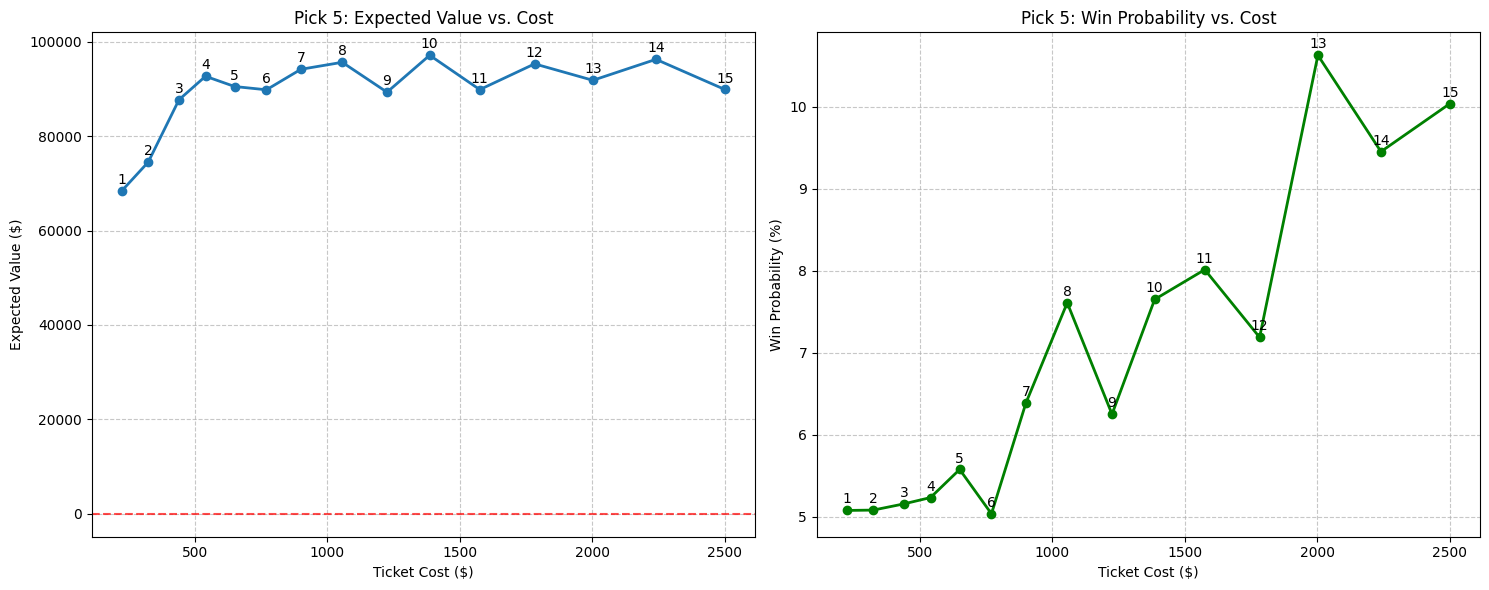

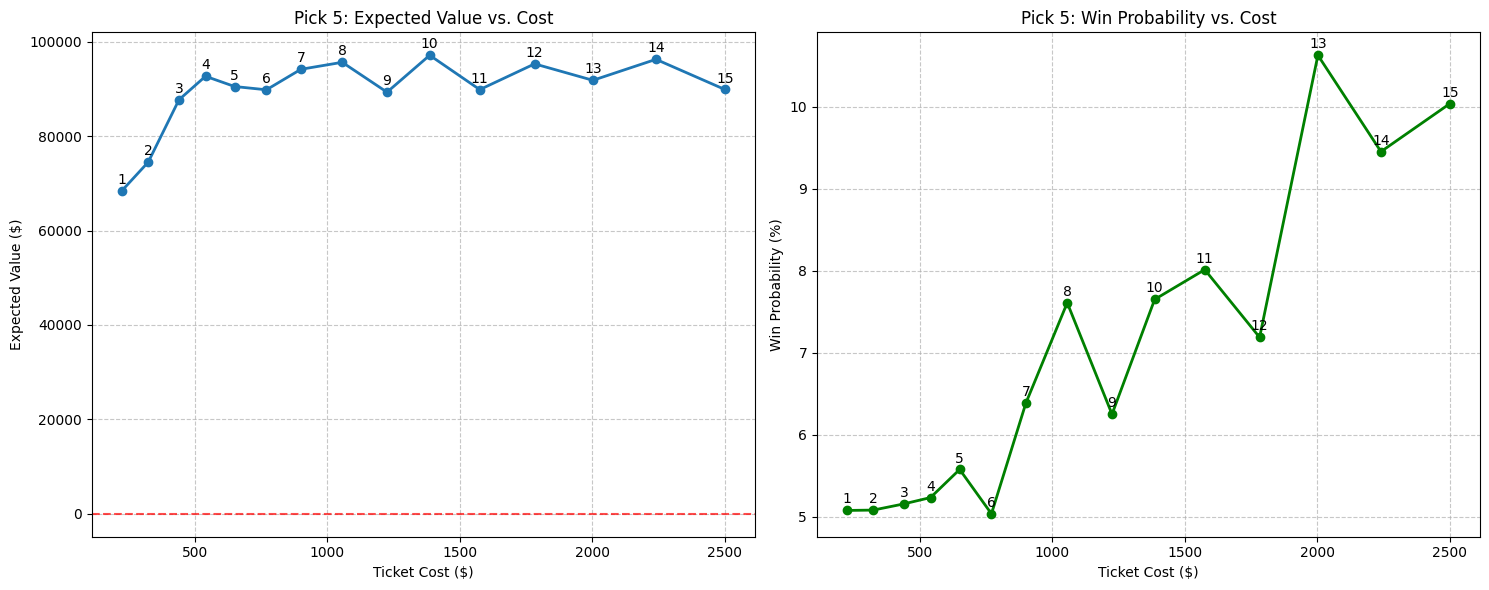

In [174]:
# Assume df is your DataFrame with projected_win_probability and ml_probability_normalized columns

# Specify the races to include in the Pick 5
race_numbers = [6,7,8,9,10]  # Adjust these to match your races

# Display the probabilities for these races
# display_pick_ticket_probabilities(
#     result_df, 
#     race_numbers, 
#     blend_factor=0.45,  # 50% your model, 50% morning line
#     projected_prob_col='best_win_prob',
#     ml_prob_col='ml_probability_normalized',
#     race_col='race',
#     horse_col='horse',
#     horse_name_col='horse_name',  # Optional, if you have horse names
#     ml_odds_col='ml_odds'         # Optional, for display purposes
# )
display_pick_ticket_probabilities_horizontal(
    result_df,
    race_numbers
)

# Optimize Pick 5 tickets
frontier = optimize_pick_tickets_with_calculated_probs(
    result_df[result_df['race'].isin(race_numbers)],  # Filter to relevant races
    bet_type=5,
    blend_factor=0.45,  # 50% your model, 50% morning line
    pool_size=100000,  # Adjust to your estimated pool size
    takeout_rate=0.22, # Adjust to your track's takeout rate
    max_cost=2500
    ,      # Optional: maximum ticket cost
    min_prob=0.05,      # Optional: minimum coverage per race (70%)
    min_total_prob=0.05, # Optional: minimum total probability (1%)
    budget_steps=15,   # Number of points on the frontier to display
    projected_prob_col='pred_final',
    ml_prob_col='ml_probability_normalized',
    race_col='race',
    horse_col='horse'
)

# Print the top ticket options
print_pick_ev_options(
    frontier, 
    bet_type=5, 
    top_n=15,
    # horse_name_df=df,  # Optional: include to show horse names
    race_col='race',
    horse_col='horse',
    horse_name_col='horse_name'
)

# Plot the EV frontier
plot_pick_ev_frontier(frontier, bet_type=5)

In [175]:
# # Assume df is your DataFrame with projected_win_probability and ml_probability_normalized columns

# # Specify the races to include in the Pick 5
# race_numbers = [1,2,3,4,5]  # Adjust these to match your races

# # Display the probabilities for these races
# display_pick_ticket_probabilities(
#     result_df, 
#     race_numbers, 
#     blend_factor=0.45,  # 50% your model, 50% morning line
#     projected_prob_col='best_win_prob',
#     ml_prob_col='ml_probability_normalized',
#     race_col='race',
#     horse_col='horse',
#     horse_name_col='horse_name',  # Optional, if you have horse names
#     ml_odds_col='ml_odds'         # Optional, for display purposes
# )

# # Optimize Pick 5 tickets
# frontier = optimize_pick_tickets_with_calculated_probs(
#     result_df[result_df['race'].isin(race_numbers)],  # Filter to relevant races
#     bet_type=5,
#     blend_factor=0.45,  # 50% your model, 50% morning line
#     pool_size=100000,  # Adjust to your estimated pool size
#     takeout_rate=0.22, # Adjust to your track's takeout rate
#     max_cost=1000
#     ,      # Optional: maximum ticket cost
#     min_prob=0.05,      # Optional: minimum coverage per race (70%)
#     min_total_prob=0.05, # Optional: minimum total probability (1%)
#     budget_steps=15,   # Number of points on the frontier to display
#     projected_prob_col='pred_final',
#     ml_prob_col='ml_probability_normalized',
#     race_col='race',
#     horse_col='horse'
# )

# # Print the top ticket options
# print_pick_ev_options(
#     frontier, 
#     bet_type=5, 
#     top_n=15,
#     # horse_name_df=df,  # Optional: include to show horse names
#     race_col='race',
#     horse_col='horse',
#     horse_name_col='horse_name'
# )

# # Plot the EV frontier
# plot_pick_ev_frontier(frontier, bet_type=3)